# Utility Costs in a Downtown Bellevue Apartment
**Arvin Sam · October 2024 through October 2026 · ZIP 98004**

This notebook reproduces the analysis in the companion written report. It asks which services drove cost swings, how weather and peer usage put electricity use in context, and how costs compare with local references. The target is a 1,195-square-foot, two-bedroom apartment.

Use **Run All** in a Python Jupyter kernel with pandas, NumPy, SciPy and Matplotlib installed (e.g., `python -m pip install pandas numpy scipy matplotlib notebook`). No downloads are required at runtime. The compressed CSV inputs in the following folded cell exclude addresses, names of other residents, account numbers and payment records. They are sufficient to reproduce the reported analyses. Refer to the source register for original data and preprocessing.

In [1]:
from base64 import b85decode
from pathlib import Path
from tempfile import TemporaryDirectory
from zlib import decompress

dataset_dir = TemporaryDirectory(prefix="bellevue_utilities_")
DATA = Path(dataset_dir.name)
payload = {
    'apartment_monthly_portal_verified.csv': (
        'c-pO4OK#&v5Z%uybO27H|DS!3^&p!p1zV<LVKkCM(KE;{XUWlWlDuYDRWq0Xp-'
        '1w<c&3|Vz52f5m&<v68NNNt<1}2yZ}>e=57(FBb-d2Q>vVY?r}>Zlcp4A$bUY06cz78ekEhe|{M-I{9EaD-'
        'G(Vj7$1@&q9_QgZu)kj3rUMRM$Nlr$>9l~a<8*vJj!(-Ue1Km@f4`lN^L{aG-wbOPVAcW-mubYWFRu^N!{cdOT|Ax-'
        'r?;nS;P>_~ryfqH{pom}>-)#)dO3r@a_6_p^!f2}`Me*0f5Wxw>*+Z6BmK7jJov$C>pvPjn5;t7_!(SME-'
        '%Px<;#M!N@f9BEr;;GpmamVE9Vw8IL{Y<rFRV}t4#m>WjxQj>&rOKyTAYZYgYrZdxER3ySKCW_R|uY-Ssey<N5k>nTHTm@yi'
        'oZRK7jS;G%8jn&?z+(8Bc6-k*&sbQH`=sF1jtAy{SF6OHz&*agO@3Oz=c3CGTMMK*j#wg~?pC2K-'
        'bn#{0xTC>f814HKomZDrBCqxxmgbc366gpo!_{bhKIx5p1AB*z0@-'
        '+cjlj&Z8pMLsz;d~vZugAl<8_!R>FH6M|UmU=BrwqN!TFE`cjY8u}Way(+J`p>3B2l!BvW|&{kJ?nCn#|EbnU=foXmqy*)+p'
        'WF+tEgvFp})mnX}U(M#WHQy+Dw+6ek$%Luib(idJ`;ww76F=kPz*P_2@5BTEaXWlzQm+{P2hn#uK9s~m_?RIx?DYa=j9Hsd#'
        '56IwVud6sy(Y9hI&hLcJ^6s5zhc^lEt3RRB4ZA86cmsjImyVXVHZKn1a8G3J}Dl<42N_T`gtn$_mPD_4+XwaOul)*RTEjlJ;'
        'ilA*Yo#c}#j(dj9h5Nrl=VX|)G+VS*N492!EUsvVO4AnUySY6ceIVT$&y0rN5~`!kG>Kb{5M`T9C~|5U$Y6r5a-'
        '*{zP1v;ZlyDQxSj#i<>_J*2j%L1<CSDaRPr~pXnm$PD(cRxDRPIeBFs!K@d9v5m8KkK7ie|zjQh_qWXinM~n85$gq^XOt=Xo'
        'bIqjbcMHq!Jm95luoy*0t9M)H@S!&y#7z(~zDRcWwF+Faw{v(V(3BJyJ!&Car;X84dC+uYISpvEMfh$^tMWjnx@phLozENm%'
        'Q26<k}DyRihm)n#vkxMB=zIhwlD3>}Swnd~@M;iwzTuxCmmg7*n5apXQg`tP(mV^<;MT~*xudzM0rsg`EZ17Ag)_Zp!woAt7'
        'o;><J(JkyB3yDCL<}hX{=FSy{9y|h%vjV-{_(C+=vf{f4U-k<+Q#PE-'
        '$={1_^)|gg;5NRfbuJOynzfK5mFj|L=pm|TMKLKs1kzj$q%erD9fIajY;<B5;f@&Y7vE?lzVSUR83Q4)kVVFkq^}CrOCKiaa'
        'kfMeSJe5f%~Y0^Z>;(kexXp-_-g4@rQC@xl9H6?3T}+A<wdY2W+uLnf{vxXW9aK(qPRhCN9sLZQ$-'
        'M8TLlIC1$?9DZspRQ_(Dz;Dwqy8)~}T@ik*eDRF(L}%6>!8Lt&BFu4j2I^L&8#LJ*6bSn9W#lRYn9xAUzdh#E<U8~Ms!YHec'
        'bASJ5baCst4;T!7Zs7qb|YT$I}e0`M|G_H+t9O`;3-'
        'm89NPauIC`KG?uIo>dx)!b$rs+yp8eGiBz`$GLWuJ(Yq2xO<MmU)!4^k;Xs=}UvWqxTC)Bl~pm97hMeMbK+ZBVGp}^L1b+*|'
        '=gGtFodtV6YO=ut1y8_lj<PB~@>So4YfqzB-Ml(K%~*S9C5h^i}V3bkW&3x=FcpbW`PPN*|7%_kwV*?u=UUM#i0g*JldfyR('
        '&PR0lC7wvz)MT_^>~W^afuqM25FbNw(#yH$}dAGpEXDVforNb`2IjjRz3UdJgf*>C~rT?-LqctFWOHubX$-'
        '^R_3$d<~2lR(Qh6!OLueiPednQeNH(5P*OEW>WVOOel=t?O)cXKOlJ{V%pvIO7)j9#&Xgz*BVX4m!heH(9}r8@+s2tY1PcZ+'
        'liGN8Q9}?jq!@mr~#UF}|9B`0x)f3Aza'
    ),
    'portal_workbook_month_alignment.csv': (
        'c-oDY+iu%142JLfEE=H`b$Ee2!R`ZhFp#26QzS03$Dd@8wB-THa+BY-%#Y$pzFa?-'
        'vwB=_@2}VE`{^+)^KHAl&yW4(a+~gF^>w{1(+4f3i?)z1+Oqp}nNOE${`9ynr^~ebKC939&+^Yru|It+r|;$M<867H@9KV@Z'
        'u4oP|JN6*t^Z-'
        'PG6^u~@>4E?ORKUPd|uV~>95=OtbR@(_gNXOLC5tj7Ui&0L^BF47~d>w5819V1jr5Y<nfMYJ;G|bEVULw#9k87Djz^6GKpZC'
        ';}{{hRh7q?i2+RGgbco^23xt-'
        'X|U}jV~Qn%y{tt1p^b7Lu$jynTvLdUBLheN?18#OgO?i6`5*~sl`F=LnDosMX3#A@V}JHQYam+Mp@tL=l7LQ?Ncbqgm9p-'
        'EcJsuaJ<)inG##NNwU<Qnm1wgRMxsJ<5NV5JhdN@h<hS_SgCru>s721U0TbC|65`0AE~+RQH<nYeNg@X29AK1?(<VYGbH`~M'
        'In-'
        '6E0cWLBLpVqx#+oRfgvhmsV5#ND4(*9iOUkQJ#9k6HDVL>=P2lKb>A}R6GjeE0bk>)?YfFPIrG>pDVpcBj9H}9<mN!9V`NW}'
        ')7^GH%lUfzoh-MvP79~;1@Frr*{1b=vM7Q;0S-'
        '|}$l8C0xSs4@&usIpaOhKNiBZu}xA9+HU=*lQPNFrK=hTpCxwInKMJ_1G#b$iresg_ne$Vv?BRMmV6RATU)D0<_GLwjPKXOz'
        'dXz*8PY60wX`>9RF!&Gl4<Y2pbma;V#52IM?uh~XfK=xW0`s%hioOe`j;AIA=Ldn{9sQeH+xq|;F(5q%|EEyWnMl!oI8Fmk9'
        'Px{Vk%V(5ujTRc%L%5g)pskW`moRLF^?(kbn@N5)G#88QbTRcmmq%5B}beK8Z9c2OMLL?ERDyJHKN#q2X=4LsK90N!G?8j=h'
        'GUV!a0}VNm1WYB)5c$NFNsUQ3Lx1+b6y)Uaj$hg&0rOMf`0@Tb?!Sm;Eer}p&fL}I%aHDkpYC|Bo}Es*9|QLC<uA}gj@b'
    ),
    'pse_printed_charge_lines.csv': (
        'c-pO6OOG745x(bF%qft7o))WEERsh@kgqX<1U?FD?LgXC+7)KUQT*>yWRcz6o(CyA2MMj#@S9@QSMT}q^mzI-efV^D{CJq|A'
        'D+K{zWe=f|NeM)I!wQQ`!sz$K0Kb}#c$8|Q+oOS^zh~I{9gX+{l~kn`SsVk<LTk<^ZVzMJS_h@Jl_8W4bmQP`rF;}!-'
        'w5l{SrS@oXX$R@{xZ&9F9BKz54Ot_<Y)-'
        'F}q)X{<Qno^WpyWWM%+I)=u(zHWS*}#Az>&#?qt!ut!)Pt$7KHyH`K_^7Nm>Ijp7NCZI4gvmBp|Q(Uxh1bC5`F3U?<Ug8=2l'
        '*PpYg?j_bBVH4iE{coM&sHu@@<OF02OZpZpAR2S$7F-2$LD$X)A8x!@$O5tNWx$fMH5D3H51P^6lAuIjedIiCgQz)k_-QE|L'
        '@<PPhSp?r*s+!(bv;Ja|js|h_E^S?(uN^`1|hNe}!$29}l~?$HV=@Nx#TDxlsYw`vj0*8^_cj{QdMv1XwSV#ed%YwLm>j{;)'
        'S(agt!goa}?bxTK)lbj%<5lXS$DHMqC%61GD}pGA+Pj1j90K;9x^2)Gi_x(th9D(4Gf@+0CELC=ZkFvetQG4~u|#v};bK^>$'
        'aBM7jaz0!!HyjxAvVIi8NK&%R+7-'
        'C0*7Xf##;0?S<AKC49@__mIb^adXi6_dpr<qE~5KVI<WtZ%F$vw?noW+Lr{67wlhi`Ykd_L?7QUOqg>m`l;Nq*M5;}y6Yw=5'
        'Sd-_c0cb;9&<z1{Zk#Y_ORbJOjQxMa=dBQH4*NS8P-'
        'uQeK3UxEp1{8d)k^)b8zUTA*?Txf4;#uR443|s<?;UVZnX2zGugkItsqevX)P$?DM>QNY%$HlH&fw!n)1v$okmWU`(aSf{!h'
        'k)0x0(41UrHG5OQ4XW$8dz`*0W}j{5cmvNB_@ef94C*nBoJk|u^r&i6o-=Sjqr-0#%yYsbu|{CZQLYmg8{mbDS@-'
        'sOivte2sT#O<a#TtMCf2AiCwc7>SLlr7S?%gVEY+WZ@Z5(6{3=D<r?zk0<v{x+s~tR%ld5|DYVboDY#jxjeSW^8;F(STL@*0'
        'C?+v6R}OBr5+q#%G02UmAhT#bOA(<3xte#1t(@i^UqXV3!r(@Po~iV_)IJix_jV4OD-2mmF}8-'
        'HzM*K$P%h*EB?V8pBrtFTGN@;Tu_^AWxji%>9X;z|NNKZ#-bk$oJw5Ar$-7I9>qBS&h7_$JTSdFRqTM!kF<(-'
        '&P+DTPO(~{CKyu_u*rPSWP-'
        '#gnAd}sO?3l`NYbC!#KRGkAtL=kx1<$R))k!6>Ko193728PED$y07Cw3p(2VMn7>D5#tWI{*m4wWQGXDZpE2q6eJmg-VT&x^'
        'A<4HzO&XwDBYNinue;y#nO>$2J2gt?=$RcnY58;n8aD~fG2)!dZ3dd{a|MqBF|dLcts&-uLQSwf?Bg-'
        'z7qK|Ld1(6jIB*^lYjx?BoL-'
        '=X&wyEYJ`9M2$F8y^eQf^@X3ho$VsqNJt*@qH!h@x8d0FWHZ&IX|Ri#n>u2^pzaCVKFNiq=q%3Sm3qoLa0%|?~#_rrIZc5xa'
        'g3?Sw)3&l-h{o2DX-PHK>F&zJxWtgkiJBn7s!|5oS}juwK1q*L)g8P_?U-h`Ju`+ch5-=P^(w3YMDlV|L9LTf4@-'
        'U1QIARQV2Us>!9FD#Z8f8jL|TE6QR&n+oz3q*qqt!!T2+3cw(=B6Q1&d_EO!r8E-'
        '8VgoQ%R%DQkp22kWEFanW&qY1U>l9yd?UQA!t`pbX9GBc&QP+NWi|Qeu(0fi1rxtT&N%%KGSAV3fs3ztXFpm+$(V;qeac(e+'
        'H_Bt3E}aQ`hU=x(<J4WJi9@Z?YvpqlbdY-tn7J3!$-'
        'u2$rGQ*%|6<cs#y9q?{R39jk}nZ`CG>SrFwI2Aycp>ic2eLFB^@jSGPKq<sF#U;Ro14}%);(-'
        'me(1Bg8|%Y;$~oGVW`S0i76J>w2aswkIkdtLctFGQ7}L^f@QjD3me4^>O_dQ5Z7B+WoGtGNpM*5w{H<fX_!IW46#PB(12VIf'
        'teV3Sb~GCX^L72ZbZOrCq14Tt5O23lLi=_8nU@yCG1-X|GbrO%u1O@@~2FfC9pOK|A%0KT`QHtC7mPs7ZP-'
        '>1f~5ozD(Az{qjHROx)kA@P)k!giB_U*Qw}OYH5dMxSE$*%cGWfd||J$g)I(->R^t`&D{{}BCQRZ@v3DPC!0qBQusq1Na!e-'
        '*EL9f#B0)?!8)N{+NR~^l-Fr65_NzF`R9GMV%m0UwMC7EI`qR}bm>!SS+YGP-'
        'd?Y;PE_?dXDJ)JgfEKud!#5Y?TCd&$S%$GihGHKWq@qjI}Wj2A+{{PvceEozWouG23E~SHuW003)GUgNe3~ZtFp<hW?xyRTL'
        '!+cz}UhnwWO-z5R)q`OGX&MU28VC!IfO^VUpKcvzfYOG>yEmJmMbW6?xBanOu-sMI^P7LoB7Kz4m78JII5+5WLU6P?wmoafT'
        'bQSV^jft(_y+WrFq1@h(jjV4p|MT9HcI-2e;`RYA5ywf%6s9nVW1x@1<Ddg9cb6<4$dY0<d)d;%-'
        'W7(SobpWzm>N;Zz7FVSC3Mgigo@+$FmOu#6C$#GtzftnPep%n?%M|(}&4JbRG!Y#~(r5jHg)INthsG|%-'
        '%nYP5pj&?Oz&E!Jg@O67g@r&E>)3~TYX@au1`q~P?OWM#12D!wyi^cSpMm|ogBmmkmH<m#i#9YEqw|4`BK4^%+7dJv9X;z=;'
        'Q+;^b!<fF=~)5xHtjWajKj_GvFSjD*lOAJwS2a82p8Q3#1Xv<DdD)XGPicgIJ9PlI=;UEeZD9TR=g(tW(g@z*PsTvP?6nQ&A'
        '8RohZh5j*fs3{o1V~p=tw3mV&hy}PwWZZ;SpKTs*Wp@0iZEdmq!X9-'
        'Eb(2=Cm$a&;NM1KOFBq?|y!Gyx$dBN~cYwxlR=ql@4Aju0@6C+`571)&kCz-8H|i?&-s#JbB~G=n-'
        '6Ou*c^17A}yU`=syhM=~=hm+u~CS9S}LxxpADilWf$YE>K<8<ZX?bfp=V9gTCLm7&WCU1{d|i`L|}y+c>etIZ11GHkY?shfR'
        'Y>3&S<&g6M7Een5%#n6BZYF%My_GMr1(KjHyh@KBitg91WlH#qEp&QXnnfTf|){oRG>pRq5pkT(L^@f9?uk|pdb-'
        '7>4A|}<k+EG%324qm{3S*aT9(u41N=NN_8sxZ+pbdj>W$0;L&rAHn`dcP!>ZR~KS}#zdkFsJ<LxPGF`)ZGaYPYEzrI;Iex%c'
        '|R4jx-'
        '>sMf7+V1YMd8@{>RC`!+V!7e|DH3aQd`&!QcN$b^NJ%$G0d$g`lqV*DQ;}R*mn+_h>bg0tHrbE(NaZZS}5U6VjUe^*lu<Ky&'
        'b7|ylY65J@7QxsN*jw9<v@lt=9m_A4T@iO#Oz^sx;DK!iM@m~Mno&CCSbHI2?>e}Hd}L4hOK~bS*BY{}?Iu<}>S5$s3|bqhI'
        'o%&(=JR`6Vz=?GWzl!gu|UCGC&E6@Q~w75#`9$'
    ),
    'seatac_weather_daily.csv': (
        'c-ozv%?=&64Tbl8mPs)Bqon63iY^PINzp8tF6u=eKjI-ZHgYenb(lr$g$ZdSibs^F@BZ)Wm#@G5_xJ0UFJFJXzW(RS|Nrr?^'
        '~Z0&<Bwmz=%4@o<rit!KlT5A`P*Ore&2Vlxs)rfKYvR1Pj|XxTve{tf4=eGHTGX_|I2&Bd`Y?5eKq;HZNqkAST2#P)~mJMP`'
        'b~Wte2##j;qz((y}~ivt3fJI{D7ZB^|@V8uqI<ZBg?6wsQ87Lx-oWPkjcZof%FYomS|XOsj=?)xK<>3CU-'
        'ctGxls{7gtb8lIHl1Wld5|NT5OELYF!c9M1%>senb#<l6VwrzOSV$<PiiTBqe@Yk;Xx-HY0W!IkS@H{Q0GcQO(U0|)Q`uJ&*'
        'v+rE~vl?83`&gbC<{Kk>tD$$XAN4gS^>ba%&#0uc$;_*l9WmsY%yc%JxnO*Xj?ZrMu(vfjCm9~J+T_1ef@?Z=3=mf4Zt^Vt<'
        'bluZfzD1$r^eaGQjRRkt?R4i6=<L7JPWfW!7{1kZgU>AnN;}HvaybkRQc3}8vC6|rEje-Ym-'
        '@=Nu^I`1!LPD=R2}&=<RB@KbHN>65&$EmL8$54qry#I|o8$W3?!${ONagc6lb~U-'
        'K~3p0#q)Th%`uSbkPg4)?Z%d#m9Rp^sZ-NhNSKSk`ww>YnqNrRe6Vtp7jJB-gX=)KR_a>hKfT^L^Il(2p!L(B{N<ihk#|EJv'
        '2vd?@oCuOfJ3l|7!5=9y)V$x4C<2HUJUpZc9oOF5mj2_I7LquazrQG5H$MLvrOO9hvu`Yr1T*?cH3<H!5XqGraFl)A#-'
        'V|nHYMSUHXkFMksUCF9t>bGlbpB0i%wnG_Ow$|s(j%`*gTi?0HsXX(U=UJONHtQd+4)1?o(wSvb&DP%1-'
        'zgeR)D!6M?ARw%RzI_9nMy-uBUn}~3&o+VTBbgf)%)(pZ;vdYW!fgUva@PgD8^^iGL0r!+3jibWQ0u1G{&=Io3Oc6OV$&T`O'
        'plEP}fzap1|!GGt#++^9L@`$*N_c9b<-'
        ';P3*zA+#y5D2GTN4kutO_l9pv?StKpXNazxF7@Q(yXj#Ml_VLzS&MXCO>elb+?KtagkLhPdMt4I(*$9?rbgdLLsFrL5E7<;*'
        'rZIk7{%}6ql0c|nMT{rZ!7OuNKFtyl%)aw@XKa=gV><$tI9Jq_P3+^%QUdYTEOFXmBXk_&&2j|xnr1nnNJA~}C&r(&sVX=SZ'
        ')wXE&@!{k*!MMR_hyzwhetL0na_MSpGyVRvQoQLv&4p4drRyS%u?{3C1BYDdup>p;9C)}Jo8x&=Tldv?@~F-'
        'd<XWoW{Cj5B7J$HPr1)5b+72(Nw$e29&7V{_S8q;S);R(vAxiJJnOd^_dnWOdRB0#sco{}m$4hyHtF6%1=SPS5kg)S8rzZr`'
        '`cw{x!{fU$$cks!4>#c%S>KomN;%vOKv`q3ogH1<5Zqlndg}$wioINoW~;<)ZX6g`a~|MZH~YQ4HYt-'
        '6>eo)E_nOca+a!sw~r9_ol6CmC#;zAt)<e=EHmQJ_j6I|(X6C`Hdk+-'
        'T~NtqZPxGzHLTCh?lqAM>fU6syBg$z{HcIhj=)L2S<b*21}s$tr|+b=@66!{rnw-U(V3-'
        'P?g^Finq|dFehG|Fi|ucb3yLleDi<`%uC*6sQhByn4zxMh5h^GY$yh72WsZ4Y!F?H>Et@5(J#1E(450XZnPnZ!d=}i7Me>#6'
        'XN;P4aCuolc17Pim?ds&wYS90DJ;_+%a#ky7!xeHm{4$EM&I+AWx-i$3-'
        'lH~r0bKmwEMEj&u2m*g^keh8KYU64>jtn#w?Mc>vs}oHD)=Z-'
        'sid!Sf4q?l(+0N#+yAiDbSVbr<3G&Rz3OE+8E+K+brAFix)cW{m@yHqIEo4>vmo<VuoF{!Ro-'
        ';Q?7K>WN>FvP%|Q4W5A8<+P@2Cleq^s%M|Nv-'
        '8Cbb^`N?IMiQ%J6&fh;TH<8fEUP+#?h=S|e6w7>ht!p*dNe~p+0md10?o4H>Y%aHSs{Vq+r{H660@9e_?z8m)?G3w{CBDZMn'
        'YzV1k&X=W?8hT#<p(9*H30yQT|$}+DEf&DDXt#?7a&-j|?SH0c4gPfv-^ImS#Dwj(sK<GAjg-'
        'E}ey?Ub4mfT?NqQg!S4bfI)xHR<m8G%4@T%TCZzE+jep2kzvD}XeHV1;+fB?{^3TNc7xml*Oz7)xu!MCum`CCn$vROUC$S<Z'
        'nODpoK7;ihMND0-'
        '3)73;IoY#*|ux`GrLaO7O_l5pr#_$A!73FX6~%T9*TJlRgbv+CY_+EgmsjBaFMI2f@zbJ?rXw1fEu1x?wetTmNdS_g0MB%1>'
        'GQDvA#C!DJmN&8xlBF?~t452Kmac<g~V_d`Wi6B-@;U7YeY{qW?&;&{V%-lcMr9V0ivO!3+yLZ!!-'
        'Q%&;O*b}|QRDqgWbnepC8ADd9B*HpVYP95m3j%(l@hP>$V6ZYO4PJCmfTU^4`J2KmEu5)IX^c9!AP$A|~aCT|0A*d)RDtO&q'
        'oKf>ADtH~`MVy8R^sf8!uhVBrX4o*QIz-'
        'P>KKsTccY0W`7T2Hu{qtn)y<vyvG~RGr6PuU*GML}CmG3R*H99O`b`Ou3yfs{MH<0$ri^p8~qhW%VC+0bx8RCVTu4F1&3FHp'
        'djjXe(+6CgHsM>X$s&Ok>RO~vsN<4Bj!yY=^5=b2m9qATlC?X4l4%ZOubXYN@w#aF#xX`Jyk}+TjoyLG=_~N5KFs#?OT?DA*'
        'VOg3Ql5tLjj(v`4hCS#3OXzxoAv-t|gVRWb6cxIGGu8g$+|PO18^f-8HIR$;m%)6p=l6yg-'
        '&j=y9>X7xYR98&JfI?;)tX^N2xxqZ4P7myUiGM6b?8;YsJ?7Bo<RBDa6}C!9xLm^+84w7lVQ3MA3N!*UFB+2ZISKjlB)sXVS'
        'RPUm5TW?d<`8bf9&hBLFUq5zU|T2_lE5nIP~o=N%FHHd~Yb%#53^m+G6_L<nkRslP^yCY|!5u4o%RPp_D%d)E~?wGJA`2L}c'
        'v{tmYdJVwc=iu)1wMNpD?xwI))%l?squ^=iP)Sr4$p%wjp$Rnx0RPe&FQ7E*RP60=xWSJcUv4l>TEUNwv=>8q+&p*Xh^vw`y'
        'fZXO3tBGFZm*9G~}Fe5+?a#RNrv*hcMNInOI4m&zd=mvx?usQ~W4kz~X;B<tJK}zdTp^HR-fxOHH=jABp+19-'
        '^)VyqXLf2jrx=)7KBCS13e_b7^eEP_xbTdP+Xv-23tO2FN!V-'
        'B+ct3unCf7PVtkZdBHu)C28miM#nZSV1#lCUEaMCR<q3g}NN-ZoEy5VUO<>pK12DYC4CH6l_;d?{dBrVT*vy?xs<)w5J8EAh'
        'qtRKg9N!?6XT6CL&MX9;OtK~<xvr|a*S4y*ni=8S6rCCG8E+zze3V9<elR{8%d!`CPh2;sc3n<8h*i9I|RAD^FChrYPC>xj%'
        'yI6~M3OUF%IU#m|d7M$Pn-IG|z?y#N7HBcup%aLSLr6R!=8nszYMmyagKx2fHfGZgA=QvdTP6-'
        '6Z$E@2P9P?dI&A5=pgbXU1HwZ(xk_F3T!8z=iO`YAm@^@DU<a`+W;?#_WWF<z(*@3iC(a;a-'
        '&ljAs+VoqNrc43@<dK|;}n`Y+n+9TfrXsy_&SrPo)edCC<Nq=ujiIIa#=YTlD~*@FeHC3=wL|x;={R+I7*~0O&=^|q(yj+R('
        'ddJEZ?w@gCCp`U|+V)g+%o{Rm^EzNJ(yZzOEb#*}dqQs0}bIWJ6^V_sGP!kZpKX98rN~V916iPP`?yx>~GH_g2u`OxBke8B$'
        'O?Py2zE`B%r*k-bHYn%!h^ZF-'
        'gCAPbv}4Jmju#8ucD8!}Q2V{AxWDVYujTID~y9GED@b2Mb2c-hd9Jk70bHe~f$bfW&<*^mN<r>fYU4H+Au0`;<LeXh-tV!;F'
        '?kx0dvvmpa-'
        '7mW=Wp?WwQvO8Uf{7xL77~1x{6wA?&pdpc~)6kGKB(ymivJHny67}zfh7>Sy$%v3*Xymrhkb!D_M?=!!rnb?L9r25c(}sqma'
        'g@!`kkK}AE27Rvk8O{I1OtiCP|4<K$YxMU>H(soA*;Xm;5;Fx(4!$oL*m^dDJzDC3_OH(G-Lp1<Y-'
        '8H;zT`NbTs625hQ2Dd`S2>q#_u2it1=c@ev{(S~?oi&>RF*vTZb^I8KXzVi_8e2adIkhNK~(&C!q%K$W8*Bf^{g*|x0}($ci'
        '7v#TucH*1}I)nI7I2;#udkPXFQTz$EtA!B2ka@aD0%5EDC862S&fTlM`L-Nq{w$YFgEzACF+a9AbaR@k&YKQ|iCS>CX-fWBq'
        '4kUtPb2Mc3XWQI&<`TgFHb+CMmbHLo3qc4C4XM4AfMo~FO?Y)sC>DUa96HC*kkv78T$|+%VHF$=c{?cY7#1ZP4M{_p#nF&F-'
        'bEY@$!9vU(U3HBM>ZOgUfHtIkkwcA@!mu>8ZvvE#}FlPG^F|vkcsWFJnHQX?7?KCA*Z92k0Y2k8j^?6h@&BSMG{9tHf%SU>`'
        'ELB$!B!3(UA0>S{x0@=Sbpc$Ocbf@-'
        'lHWWJ63~BDFXgvKbzY^}dWtBSa%|mE{ybCdx)bCRh@PJ=ti;=DEWjp?+pr1DHnHXvpT4$GRdL4cVbcY^2T+0FF2sGPtty3}l'
        'hwXh{A?WMrcu?I+2I+(8@-'
        '$>;XsXh{B7rNq&Y{H=pH8d9>K+8v({iK8JKwnXIES}thdCi*)gKNBF1hU8I5;%G=7U@ne^YzEn8+w`9a7y(Q8ko~{_6XWe?0'
        '&G5s^90#wNE+EM8x7eV1bw_q6-PtreyC8;SNVp9)cq}|NXP}X&C14j%LSA7_I?!U#4;oKG(}=!{6<5X-'
        '*P_WxnLlIWgLf^4{_e-xnRH(vi)31VfWPbGXeC;uQ(c#&z8l}kUUsT91W@0f}Og$l8uJ6v863bY<~+hWJt4%|NIOe;|&c-'
        'U)IV-'
        'L(;#IC>sq)<L<=Kkm~WB_1og$eG;}P8x0xpTc9Dex0T(E0}ZLkXQpt@veA%&sL4g@;@K5>`XL()N&kq9Y&0Z&8zdVINmug7M'
        'nl>!?sB`-'
        '5+h^DH#DT33UD58x<dZ=k!&>N?dVn}>o7DV4V4r}Lk1(Y>5Apq<aeT~TP^9a9kJbb+4p6QU)kl3oeCHnlCClkheL)=?F<e{7'
        'v#u>L(;@D*>Ff2pD7N9q<<1y91huW3`W$j%4S2-'
        'g*@VHNUhMD>@LCBkhqB?BOln1^e?K*cWB7QcQ!?S4p|%x$=9EWqakbe>tSXS4>V*bWLB3z+b%Mjgc|z=HgPtjSg9s)Z7L3j>'
        '^S;h{avg5?d9)z(Y`nuQV{v*zItLcc;Cw<Cf7hi^3*$VHl!e6GUaEo;gG|Drl%Eeve}UI-'
        'LPynr1*Iq7o)SqpiW2Ha`RQ@vdNIy-<h1gau+8<c5L_P77Jbu3-bs^91KabZp68eQoPFdlt?Phg>2m~V~(prWrHEvcLuV-kS'
        'r@toC_(2Av|Y6$>u@|49Tu0bDczcfRabd=g!~%igO`DmtzkXa<FmIz>xH>#>;nL$jZja2Mn14mV*b9%H~3{3=!E_$l;i+)2B'
        'G%RLG8EKH~M4I2DrS-pQsy#=g-Ws@=?!D%n)Xh&;E=G!8gygbOK~3yIe_^5Qbj=e{?bf#P{_Fr?s4jJHgX^-'
        'jig*(hYz?Lda4fk3j!knFp2*<?r-'
        '(IrlXqzQK7WXO=$0Szh5cP>QWk*MH_*Z2oMQU#ACu8NZ(dvU}ku~z~avR8++5fKYy$WeSro>ErC$&h0@aPt`GAdZHd$?0D0m'
        'G1SaP2ouZ@*Nv8(@RpHW#i{W=oV)v)PW62(+|bjkR2B_1PVeN4LMM2+F$<tlU%+xGy+NECsNsvER0Z`4XKF7$~>=@&4z5whU'
        '5&51yM+`0~=C?zgebYtBM^et+;(Q*pM{KSey+RGz?Hh#o3TFj8HZk($*Cf==!FJP#h|8HYANc6K6xxG)i$cWJf^`Z8#CFDuW'
        '-9&4wHv=7@X=Y{)Lo^x#@Fibx~3EMP+pTaRpuH8_uohGdC?;%LZ7%mEp)XLkT1l=ltH657f2TruPTORi|hk~kT17C@*7WSTe'
        '{a^kSAziwGl{q&W_5iyh$aWDin<gf{$c1eBz;u;_4asaj_n+=J#_1wk-'
        'Y)G1xB+iD6Ih`IUhQd`bBCU`sa_qCnK~BeTXg`N|l+A_|7Xe}^gAGaJ55?J#y0@APyGWc3Iffga;(Eo|kOL=C+-'
        '?qR$N`t*cAj8Es+czhB_+;=q|wsiY{)(x*i8gTpdo4OnK&6Ta*92iflSA8kRfS6muxa5i#-'
        '!3L(+_RaWdq%9oWqc&V<V~GCYC|8FTU_bR#*)mU41Eg%pQa61gYHkTm^L91J;<%N#d2jfVn?V<96My-'
        '^_p`Z%`Cby@;c=2*<LY${~T&^FhV>?){`V!LuGXEiD$3kVmdLPionqe2GK>*+tm#zDwrQz4OFb5j0LAv<q4LZV|-'
        '$l)6#A|M+TGO%5FsF0bgFPQtMX$o(MUt(*OJY=2zJE9y+PMiuEIhdInfXsW2=5v9whZ*{58gVLQ<U-'
        'o0kSxDYHWf1DIsVHujgA2J6Koc9xUSaFxqgfaDNcnHqdHJm5THT|uG+YA4WmM$pqRX8d9aX$JPZUDlKzo!*;vTo*Cpq!V^~N'
        'UC@LEZ$;S@ILb5;IB^wJloYKh|+K(D#?k>r&kb&jlSV;c%%BYb1uTzO*AtMD}#)TC7S#jDjg9ez$8Y<&L^1lWw&V`H(t!viJ'
        '8`=-'
        'g3cW<ULWI0EH6~<qMrL$e^BuOt)rS=f5;eKbgfw0&RcdHV$Vi2?Lm`coLRED;6q1G|%7#MPPXN**6svD^C}e<h;ZVrtb={n$'
        'F+}KEdxt_+yubPM0^$#c5Nve'
    ),
    'seatac_daily_degree_day_normals.csv': (
        'c-'
        'mE%%?@R$4TSgoEKCdY&vG;!DT_`bMYGBKzerqVun)^my4NnKV=(^p=imQGzkdJkkAMFC>(?Lu{?C8^_2+N$U%#DyWcedYD)p'
        'zN{4)~^Fgw;4TPo$}cI?3AIDpe}zPNzHaRd8B$-w3)FBV{Rtia;fUZg5tkx-'
        'Q{LFS99N@7K_A1oQ@3oP<td9eb0y`{a_UmQT+jWS<cFYX6xevzuqP8J&a#qwf(vAx(|q{!wtUtBNl2ZbW5qr6yNq^jcBUZg5'
        '<94}H;c2rgQI#_7v2VrQwmK7SBuPKFw=DV?lhUVA}7@A{&Ff_*!U}z4_Ff@nALRBtO4V8UWRao|50ZzvX9F7gx9Xqf&4q$Pd'
        'Kyh5a?5Hx<-'
        'Hi&%6g{t6rs#RqGDT0MmMK=p2K2mYnWE=a%Vfp^)iTA%yMU2*1AT#NnWE=a%M?AYTBhiE)iOoTtCq=#ylR=E=T*xTJ+E4(=<'
        '8L>6hp=adS0zTMbE1>sCe==8anPiHyYZnj7CHI&D&^bzj+%C?Kf|uq5bA<G_>EmjfVD5UKQCQ5e#j2y^V&pNCZP$B!ZzW62Z'
        '_GiC}1p6~WN@i9CT3c>$Z_26|)|T0=7oEuk5Pme?E^S|St-'
        'wWD5$9he<el^w{26F3|fusLp^T!f)^P$+gfXeWbV0d~g<#EJ^B0mZQ=t7fB-ta^=RvT8M2$%?g-cCz9msd-kLMv|-'
        '+jY_goG^%Mu6g6&rqVzOBQHD}PnQ4BatTaDSwvtCt%dCuyBw5)Ql{6xz`ej99)RNVVQBNZ>s9EEaVJ54PMp_STC9I)?)F>++'
        'BS}^}<3}EF%}U3pC^e^=td5LYvNAI2$*Ra`C_&jI&15BIw31bn(N>z5)G;eBBS}_WMkQHs8P#O9Wz>|!sizwG)G@2GMVd;}X'
        '(cPVP1;IY4=9uY$54TnB%uHWU+;ipRkI7e!2!omjRGGA97De+*!jUbPPGX3dhm)<Etm9$Q!Qe9h6|3_jr7)KcCG>a3bU)~$^'
        'L}-jP%N7zD>ff@ZU^g1Sdwve@O#6lnMzt8nTd}u{uFNvNRBm#Gg>mNzegxgH#StnZPY*p)zTtYFeZpq85P%@Pb-'
        'o9%6P`hb%jNg-'
        '@W84>5a@Lz7evQA??ZsHL=r_`N%ghbF0+>arf%U#j^bXz4}^j)53+!LcvZhuTB^&?1e8=0oeKo}~RH$+0gBj`^M~IQFF)ySv'
        'P>X*<8nv7m9NlIEd8x{e8HAL35Xu^=H8TP+;}Q70W+_GK+|Y}r@0%(3k>4pABIEPjJjhAWF-tI_?EsS_6#zj7lv6`-'
        '_vd$Br%R1RfQWgW5N_N}o?sIg_Wxvj>wRq<x`&q^Jnb*k71`iq?mo2@_Vy^-'
        'Xc1(j6JIYFK1`<b0O(e^Vtb@Cj{cDijl2a6NEvvY9UIoO@{IU}i>=is)JeZ#SKPyG$Y8t(_HF7=$=M(v#XTtm6{gV8wm3RlF'
        'NYdYPVi|bRz?8YP2eD22bLoz%Xr&j@$G*2@Es^?}lYH6NU1k}&{ZZy*E!a+0Ljvcg=wiCJw|D}4g<Cp5uj$aC!o#I$;?_<bj'
        'XF2xUMj4LVWErvrn~v-DYla)>n$Q@Q5M_;_CqiRbBM}<I8i~*t*3W-C&{u@UuzmhJf$`rJeKBxH*Q|&-'
        '>+xR{+U>`M;}h@JMNX$b9cwiH!tsee8ieB$#pXET{UIEm_+v#lK9PC1j^h)5_Xx)){zwvzPh>_YDe>MCIZrna^?kaDoTpoa8'
        'u1Dgj!*o_C>)>ogHkv?@z<wteBy6Y;rPTKvcmC+qKC5AwuiFUc7*Ej_!c>@?FcpFSub~d5}|gC6XcFhPN;WYB6nUg9cv7Pq?'
        '`d*cI+{El5z%M)p5p%OUg3<lX3=Np2!AZ%TZ#|CN?jrkymOA?ZoCKHDq93^2GskRhXC5SU%<@U)&F3Uh+i_3w=eUyjWjs?|='
        'J?<Hc81S&!zjAFTOVVEv3R{|{u0!^{'
    ),
    'pse_residential_electricity_monthly.csv': (
        'c-'
        'p0z$!?s<5rpsa6ncQ)g{rJA^XP*O%*g}z;3FYOJtM*rIp88eZ|^T_p<y43a~QFk>_4M&iHNNJ_W1Df<+|N}ynB7Q|9b!O^X~'
        'rhwSK&wUp~IvuE!q_x2NYX_kWJpug}-'
        'h?fdQF^>+92<?;3T<HP5>*XPgI^T)5Z=eut|zFePPpI;uo@saD_Kfc`kd3(Cs?_B)h-Tw6d{Nnce@3&7c_up^+tnn*8`-'
        '?=8zr=K<T4TI^d;R0~^5LJ4uMeL;{0&Hd{QU6i!>8+Cf4zQv_<rL-PapmP)X&%7?;k#X<wIRd3{5ri;gqG<)Pj{dUd9%4DOZ'
        'x3f;COOU#V!&%3r4|hLlvz76Lg$kR`_&N}D11PeIUnTnJLO%D<(D8f)~QrG!?ch)o3ch9Dmzkd{&mz2q6PHp?w!lZ8MWfmsR'
        'Kl63>4h8|1eT?b$}^#!0D0!Ur02Wg`SW-'
        'W?_s5^cZlI@UqCnaJ4R!Mv>GXc5n`1LHl)tWOYHxH;HRV|3L9ljB$_Z)KRNz%nHl`crL0jQ6z=<O`JW-'
        'qvw;_-T_l1r#&D|+c<y!8~ikfwZfa-Vv&KB9LTa7FKjXU{d#Zj#2?Q_S7FYey$9{pyVY>4no@+CwL1k0W}`x-'
        '+kb(Rmn0({XmqiCl-6cI&syb2)!#O?##XQy|;5>CC)ZS<&q<^R=}a#Kz=x%FY}%+tGWgh0J@kb5*%C2FVR-'
        'm|aJY&gdx~o*k~KOx?(Qw>IiN4)4*`XnK+!ELt(5H!|OPo^@}<@``>+e3^;Lp{_P(m@R=OEe_}o#MubiA*eYw`uPi0p9pA;h'
        '2WI<s;MU+P2vNM<Q_))2Li?)LK9k_V^?+RHBUUhn7uDe96>%O{}zk!s50A~>egOEO|lV`?m4KLo@^!MfuNPj$T$MAu5BSW&O'
        'udXs`V*9sTa5?l)B`nGk&lN9S~Zsg(ggehRu{~a9@_z>q2l!{*}S*(9h}v$e%v2$wnYR3B~_~BOvAmnvz3r%_I*5nGRYAPT4'
        '=_?2~P2v40{Mw7US*Na;<8AJLpX<PTU~`;2cfulR@TkKh%iOLfwKA@%|VwjIA!1~L2i6*avKX@V8X3Xd|c@Tc_8S#lWK8!sp'
        'aEktP+0e9MtcO$f0qBet}k;xLvEPrNrR`gT)FPVDQMS)S#wUFa3J|pIsXwZh*MyLOZ5>5i<>}{uBPg7qq`OI~4pz?}BZ0&>j'
        '&ERFimsB-hHe|B)G{Z;Rskc+@<8eVJ<Iwl`x?p)9-U>5Cu5o^)pg!up&}nl-udOWhIpu$>OfJrUeTW~Cm_yqpOnF7$nYktuc'
        'Rh%c+s?cuKj)SFV+AOPPNmv?PQFCUT}YdI6o=`?Goy)kENCB!h6K7nNsb^fstds>`!%7HLoAd11l3b#zrGN_E#exKaol8H2L'
        'IyK;zCfQ4Fu&}0hnWzP<3e#T^0$ERtG96aK@<;;DJ~{;BKU}RE7djz?c?-V+BA23y+_&N0kNoDY~oBqH`YqLnI)kG8BN!(|-'
        '#=+X#*opm9(hm3HCXYuD|A&|7RL5fQ=ES{VXRYi(5B0Z^E@0GtYdXyoxU)))k%@EA_pgP{0scuy${bf>P8{1&FNnSgF}#joe'
        '<2UTb581W-`D2VPZG+rYBKB*%7$Xg+~A)WDil--2wSb#jI+9wOr0Zai?Hsc#hsK7%$dxdS!S+MY~3>HKvbf>?croVPyf#(7W'
        '2eR}+I*SHPXbh;iapvkYh(&Pvkv4d+z>T`%>oE_aKWvoaz-Ug!aN#pod^nQ$>?myFUB@a64<>CxfQ#lXE54nkALp59c$o_r+'
        'i>3Nm|HK!@sk@20%RzxEO<}eU+GVC`!44)fWwWx{N|Z{Bd6qgSD%&Jl`%U3HKzi1XO%r^b)S{heaAAuK85gPD|_8%2?$YE`@'
        '{Fidk$%GujMXWNCneB^WWj{1>lqckv=%sWVvt-'
        'N4G^=42T;T$EHO)bemzh#;~e8)!6}kc3?eL0YPDN4ziZ7jM2)1$;^wABf{jjBp_f0Jqq>k)bvS#tn7UukW&P8Y}qnb4@rJ0K'
        '*`ry040sd^C{?_aZegO$__TRF?4gXKs{Fh*4?H&bIo0+w+(ZUHUbu7dLOMcBuRXC3iOE1MWneOUjR;3phS9|!p^&Zg2WlS`O'
        'bh;pMy@0VjePxEo2evI=pBjVp{R*@jYD03h_)UT&*}MOf<yDZo<NfS;eo_=58g#tni@6?>N`8;<sZO)^3}42Me->tX-'
        '7&?*7|Y4pU98f*7aF;0zu@jJmD(r!s)a#9sC3JQTCn<iFPgpt3gBAVYGx-$J5-'
        '{zrAj$GflidTd9r!l8)HyPzg)8>wwu#A1vL)aF(Yi{x7)z0%;z5x=n?ulT1jAUXQg-Xy-'
        '}*Netscm8pPdNqNE+5X41fG<iG=OrksOKmg$u?|!QAnto$II*zx?={%x5y8W!1WkS+>i0K8{c4`^aqlbssSc<c0l!z71dx<<'
        'JM=dKP}<{SNAepob(ZnlBWT!k0*GZ5;8X`N8e*)s>+ap3CGNX-1}r)Ax>Xf+k46-Ov)z-'
        '%oq|CD?LY^9d%AtS{|1bwpBG`3AX#T%>E?T3e(OYRYM!@3Is4390u}KIIKXijtgQ=&ybFh5Jz!*cTgWi#SpUAiClF0Aa`Bao'
        'p+rLjM1Xci64uAJbmaHJ@T<vy;H<dC4R9@QUssH2j2@g+VUSqkoHtw5fuk`y3rBemj^vbtKCE@Q`^*7jRfXwgDI7kD$#4#)J'
        'tO9P6h-LRQWlE(E)>=9iJ{FMb=-q7v+LFr6vjBf9Ra?Oabf5zRq)gk1x{h1XzxSew-b9)?iF%^7_%)DxI-AMk5Qd#a|%AFF-'
        '{cLc4zc=p=j&_u;Bdej1_?e&FN|P2}0%D%=oUzS+T(GPHXc2DD-`~(DALooKF<OSSCbvd-'
        '~np%!Oax$B_%`et$DiP`=%r_AV5h%MIMROJZsCi`ud)(mL!->jsWpt6yuQG-&#)NOB?n<v$U{kcR'
    ),
    'downtown_bellevue_posted_utility_estimates.csv': (
        'c-'
        'p;>K~BUl3`O^xq6cs%By9%<c1WC~N>dMGDQ$x7Q0DezDv;Q)Wnue&FZ`dqjOh%SQ%2S+V8ozIf%G~Snc>aLJ~yw(qu^Hi%`1'
        'Dk>?$P2aVqN^anz(f?pq1<AV?}4a4a0}+`T)t*0yed*N6+QD$qZI>)>>RegJ13+!(wjZgUdFx%r`LP?VNRAkR%%Nt=Z}tB{O'
        '=&V(~uRI@x8vu)d<%zOxGF@jz-V(YVK-'
        'Sf<ZG2%x-gWm+^?B7jMill_n(psNfQO$4K7p4S52lfGMt*!^>?Ej%oHU3Y`FN(CGdH'
    ),
    'arch_2br_allowance_2026.csv': (
        'c-l3}F%E+;5Cp)US6I|nU`I+`z#AyhVQ+{fu%$gGk$+E<)HB2rM2T2Cl(HeQ*3-'
        'nmPmYkYmi9XO`nEKLDcmK<d>}UFm|J&RlH1k9-yVM+7j2+8!x#JoZn|R>@568b17jt('
    ),
    'recs2020_matched_public_extract.csv': (
        'c-ri}Tdy_SbzS$K-?Fn%HE%WNqhryb5KFWzIzpZd!$<%F0TLko|446b)ZT~U`S_dwi3E|~(q5}-'
        'UdOeMKK}0S|L4E|r@#NxKYsmR|Ls5jxBvA&{h$9w{`-Ib`t$$t@BZ+||M>5}{)a#O-'
        'GBJgpZ?*WzW&XB{KLQf;~)OjpTGX`kN@;<|L!0D@DE>q{?niT>EHjGKmVsc{NvX@{_`LH{(t=ApTGb6{{Bb%{zw1*$N2uo{Q'
        'k%K{>StEkNy3R^Yg&#=U+e1zJDHm|2+NvdHntJ{QKtx_s<*dpI6*J?`S{oXupmB=N;|m9qs2G?dKis=N;|m9qs2G?dKi+=N<'
        'j$9sRdO`guqHc}M?wNB?<8|9MCMc}M?w$M|{2_<6_pdB^x|Cw|^Be%>*D-Z6gOF@D}Le%>*E-'
        'Z6jPF@N4Mf8H^F+wPxt%%6A6pLfikcg&x6tn2H4`sY9XcmM7`|Cj&zzx~($^7W_x@HM}h|99Ux56|lN=f2li{p&fSefAvBlM'
        'Q>GYktN(uC<<g>pGt?X7AaoXSeHf&FAWa5BW<!?P@C@p8b6GJ^RiHdY-jDGmmRIY|mNkb6>OVjQcrH`#gR3mgDd|<9x23-'
        '|%7W^=Wsz_LULr(?2J_+&KeJ{^xVAd5xQ|J^M4}+2hGy)?A<a%z4)0H_zv^kr6QJzBABq?;MlN=laYwo_yw|<MZ6(J~^a$>H'
        'h4@c`=_1?sK*A^k*@jOyRoQ*(V?7_?&Z(&L3v`w2WYEW{@Sg+H=q8PcpZ;$D9oMem;Gi)>+-'
        'Xu1|YT7K>%e(DK*ipc&dT*2p5}LsoZ>d}}j<ncu9{?z0$Y`>dzU=DMFO=-'
        'K%<Be>6Jp8Mh7yN^%LFXnaFo$GV5Bg=1Pp{}tQDIe|(`nr0qT0WdC`*ZHzY7_7K8JiVY*UH+AlV`0nGyXQ0+i|k(7w>n-'
        'IUV;kp24o&_oweOGA5pNvK{le*Ugac&saG(EWp#A&&qka9rKk%YkOs-dC#3gbdA08o|CW5b@ja&*>f_OlWk*Z?w+shYqNz<%'
        'elEuKAc+hY+!wj&FMJ~yYrXEq+1`Ci*{uSIXBtR9O$n*)5+4EpS$v}|J8d}`d5x*zR+0C41Y&x-'
        'o2mkxw0wwdB&Y<)UIs6@N4%c)5s0V*Yd@TGgs{4H&2$}xqIZtop&#0(D&kNEt|XcSbXT?`LvAs;yo>gJ-'
        'f;M;5YNL^S!fqPiFmGJh+{eS8|XVAI8iXY&Y-E$Z~{oi8^1)R(_syb$@=cZKvm`-'
        'aI(>D{Gq1{$+eJu55Jvkh68&*Ha&^o*R{O$|!S|av^q`e(U<=9`(mp=4|bg7yFZ}`5w8qCx6Ki%PToW{v~h8E%g042%lVlwz'
        '|ud3FPdvG8uCoz0Np~%e3>(emnhV<tI5I>`(6aXO2@VK0lns8cTlgjI6F>iAdTkMSEYra-'
        '8<#^m~@_ar*trlJz<JV#r+EGqT%!I2q-'
        'g=lkTrJwZC~tz4R(2Q)XMuTLiVY#+8W<(9K?`<GnQy>if)^2oJc5v`t?J=x`Zw|AD={qwlYEkhgEbZ$8mInJyGs~N%7`t$^5'
        '&^yv0Lc}GQJ;$-%zI4xg?d*Lq(KcP$8cjBE=44);tQ+yxW-aFWta)kzkur*^=kc11T;b39xg`JmeMvHjD@t=`;d9F~{Y)#@I'
        'P;B)$*$(6MjA&jWQq5kbC5OJE$fv#8<89Fm4(S)a&{Sh&UXH?4!0`GW`5-'
        'iWgYJ5nTWsLXBIyqCYK^Fxij<YM*KuKMKwenWO4H0ZoKA9hBBf}B4RRm2ALg>z{~y3Upykw78fH!XXL)_&2JhaFXx51<UXO?'
        'e9M*XKDmooDaIeQ$#q@)Wg&`p=ZJ3Zads<1%U?#$PJVMCJ@S8<bJT7`ab#!?;#}y2{2|AMo0~htD|4&!pEH*yQ@*%}*PeXfB'
        'IV{Z#~<+<?X)6fcO)%xHB)2$5gmEZti9-'
        'sP0hpk+MSz_Gl`7ILCXSg#3D*E%<FTv3~ce66Q$X^?`LHq{c|l#US@Y@wBsJ9&)VILq@7&TtTj7|!NB%%Pex>8&R<@Yt8r^^'
        ')W$`jj_vYBG@UiG-'
        'K;`HILENDa5sXs<xrd~_Q(V7C>d0;Bgjti{ySIu^ek2+@Q!H``PEl0ca|#4^UR!cR+I_lz(+cBa7Lu@y$8A>216D;f^WJBYT'
        'As_c}KF`$PgYDtrH_9=P1ALS?is7wZ;JU^<kEe%3;LBxqfj=a=UI+$(>!yIcqD%(S0MMBO-IO`H&lMW;S^9wOr9P+KDpHhYa'
        'yv-s3xC_#nC)KgkjNtaDw;rI=Np`DijkZRG@I9}d?&|C^hcb(p**0xvsz4-'
        'CPBSRc_UM@={LAu^_ZAL+NUy8JtHinMwVn7KPG#@V=(#K_eic~PT`$&ed(q2qGcqJ6T$%;jV(xv|-Aelj_lnYcsFLZ0l(bd-'
        '@}ng8Tl_sA?GFK21!j4kIeOW@cV7otC^+??^8tIZL~9|rPwwB?Jghvnp^G0{jDv@{cquE97Nk6RGAxaQu+F~krUk-'
        '{ua<1lBWQ*ChP(YYrWf$RsWHS*hS%Z-'
        'en%5mds*{Mi}!CxAxm3y)sPEOP4BNvI^L<%6xRUucb?+B4nlz9=x*4_O}q<OCKp3l1@NG^?%#hHy#;KM+`MTM<89wV1-'
        'IhYIi5CwL*0vO1->K-+eX7t-Y&$N!@TzfXhynA%$I-'
        'bEEiJmF>&umWCQZs`ai*)O^Yko4U82v70etr1bc@Ial+fbQz=9Tr!?Tzk@E%PtTt$|y@|7vb!bjad7G}DW{i&D;Q&tr1%Ba1'
        'l68DH*V=6Y06x8m!de)t380W*hhMK<K<V9Vx%GAX7XHdPc)q-<ju_)Tt49^W_zc|g~yoBSrrpA+x$Y|O2LTH+_T3^`$(-'
        'kgXBk%E1rj7HO4{9+>HbHumL&7-)QHxrw&;v$av@M~GQrTFDxu~4qa-'
        'iOyeS&SaBxm}E`HkN$%X;B#+JB4ZH=4Z39>sgG0$j)}NX8CVS_RFzl8qtg~wfTVUHFHxR9*`4~MVnbDzJ@8Cm-zt9nvE`SIp'
        'ffwvwhFX7Uz{$cLX_l(UZ4ZFgQE0Yp}RBcPz)E$H(<Lb9FG=Pc7X<BB2dk$LvWYH{vB?Db{`LzuIk&;O%wHD0-%z-'
        'JE_6`E=n$v340>tV7RE)MWg{I*+kx7q|98jA49#Vk_YK<u5s6cjkWc`)oucNMpYacEFv*p3Y+E2MsqOqr&;@i1D~jQG08|Yj'
        '&~`kl76vHSQpXH;3yhcQ<}*M$uflxMtb?HJlsAGRpYfNqp1@&<rgqH*)X!y%*1AYZzS|o80LKO9xvvGAZT&syNnTcJ@IOL^f'
        'm?D{F^t@6jMpV_6pT@?<;X=cx*Fx_jgZ*MDO$#<1p;qa+(j`ii*}Rjj9pYk@(6-'
        '4hQm!n#yu48YmuF2x>2*9U*;S~Sr*56bw;#mym#y~3j>Hg9iB!>8jo4-'
        'LnxeAMiU2F4`JHHh0k5r#4L4vzD6Yk}lM;)UWh#aLYY1)YbP@ZgijIKUcMShF!7P~csEF0SA%(*(-'
        '_{iJ1)U19lo=fa`Lim+^vHu+kll8Y0|DJJd7F^NXZpf_f{R?me>M%3juInB9CM{@!(8(Vf^V0J<&tPp>RDvRR9nkn;&+n?Kr'
        'QP$c2D2=WSlg*Ayi(QNj#rEX3T&ylacp#iuf(xfUTW~aj;$iO?$(K8VcM!dagO|;Y4$2-'
        'pn$pV$WDS@CUP#RK$r|P#k+_Hg&F3uDL49d)X5A;&Gs9tfa=daU*m*6dXm$+qXrV||Tu=^3)XNxn%AD85g~}aRwLe$P^X_qr'
        'e7G@Oc~2B%Mv%kSunA`tCkx_0BTzm>laQK=5K{lW;g!1<(eU-moO+}@r#|kU5vF??UTK{AC>!Ec3bDwT><p2D#o3M?Aow*6Z'
        '$#J-'
        'H$i`A6vh)c3pun8f5EpNErOU2_;w@4(J>|z?{vgUJ;caj@qKbNqHcNg&1g0jHL<HFS~I8oS`~iVoG$`dIZ=_5QES;24vG)SQ'
        '5^_#gG4<RIp;24y}3qNDBgvh(a$**Fo|&yxx#NEkYelHL?ZHl;mMzbZ1N*+PL5qB82OS3M#=jgBwEA{zI5(F)15MC7C9Ufxg'
        'mRbPsFHBFkfqg?P3lxng=^R3gGEAgRJG|I5^G-'
        '=bT#tSOgLC`pc!8i1An=tTwS4CVKM+oSs;={W~^@X1Hs!v#Qf5RScD!#<)oY@FqKlw;M4M3qC)IDmb}Ad2iM%;-'
        '%lc;)EGt&Pl5w$1Y#ZUBKUn-R=BiIO<5;hTQV48R<@7YZ?5B$!=sUm;FHrK7_Awj-sPD-'
        '4z<lb>;L`I5NsK8p?5IG|x}ODhDK^AX1w1_#uvf0q<a9c}%x<5lzgIz6`?Rs1jxD956H&PVHroDYM?~ucKYJk>Ti+Tu%%J6n'
        'zvORtUGFV`N3Q90a1K>X>*E@v$*NM-CXG1&5Pp#=}X~;TS{=qjn8e<VfOw-'
        'v&h{F|C*)3&$zWRA!%rAzT%8f|s0w?RyqZnO5vDu6Q1Thxrhh6OVGE(BtYne!y^uaERQ^p~T7=C+<QvqGN{V4+BR)b9G>BY$'
        'B`9AkuXb<!pSI#0dNLoeQTn>&65S0~05WcV>k?`1<v*oFCOHznMCc?`R&ah`joZH_p2PaQCR`MVB>V=R6)8Wf@ejHAVYf{3U'
        'iY!H%b95tTJI4iUd`eI8?rPAO96sb!43&qYFMGmXfS=)%D?7VhPm^%~YkN8PdJMrUWSn6ld$TJ%4rcU;aa$(rYKePVj%9898'
        'igUEB_!@z4Agt3wDF5}@IqQ7|nk$hIprPHO2quzZ_JRrhmY;kOi&0#;jlmmy7!@V1rkxzUcSNI`b6B`M$JXbr{HM@^XILcRv'
        'Fl7W2Nl&=REkd!y4D=|U=;^kMNMincSTxrL=ZtHX!`Dd!ocYVh@R(S#+`wFPRygPK5OqRk<kmFoyMdgEQ*$FUC%O$cn<#0E-'
        '}r@77p)aBpO@jW=5Tp#`4Fpi@Q20I_{*6bnEWp0hI-eZ<VfYKOoN;BArKRBR(7_Le*)cDsWF5;M$x`ML@&l};~~TYW5y2$p0'
        '$j6aQPx<vdX!=82AU(locb^nSr0lak?CMzcce_t(eBq))DG4hMtQLT<aYCoRxgg0*|Z9HpLJlhQl9tP0ZMwpB$Pzj0nL)+=t'
        'iT0+S_T6$rM*#)uSq9~^hQ4ObEAbL;lz;7lUwyH=i*6Y<o%T~BOs6!HN-'
        '<3Uik)RTyCtDheNk)4<rZ!t@@+_)&99E_+Nmx&;Be+Dw{JgP3#e11=)C_lt^%wl$etIhR0k*m3<*Kh!cMIv#2jSnja&&fm&O'
        'q|5w*67b;xbro9lk0t2WMuB-anthKh_%I~$p+MF7;ia|yg5^(B=SQtStKERO>E%US()9J>7WQNd=Gw-'
        '6Oc>a2p+K!q)xWSAvcLhlcLH4GBljOh^P1poZR2vlktYV7D2=(BWH;hjyJ(TB+epeV@fV}YT@t1_A+W8rIv#pza4KGTPef6a'
        '4r`vLtL!M+UG!HaYb$NmyUfI;}F#qY1v2tAY!ubxI;tnnQI?$amc*A?~e(4xce(26_2y~mmZ%!i!yvbL<ok{?UV5yN!mCX;x'
        'DnOcMZUBXbh+Ie#n$=e;@OYAUq;>ky4D&I`H@Ksxs$@X+8`*)~6A<zB%fVvJuUWGiFTGK87ii=AHSyb0gF9m<RQ!MvvloFaT'
        'mk#12?>_Bh|+_~kDP`FoIC#9m`k#nf_YIf^m(8VX>IEN9HK<Ek;5XxUu3cLib{?NhJ0BV_x7YRJ&?n(RhRr(=1<eqm_11?(f'
        'Pc^-Bt%u(Kp5c`e3adD#7V=F%2(Sj^p$FiFE+RH3N6!>&}v5%uIb-ZKq=7=qlo*pC;PT#+YM|5LxHaBt-Of?sj!A4ufUs-'
        'NM&gjG)a7Z2BZ*3pl4Tn56*a)_qkxo9KHZMx%p6xwKxKMk%YZuLHmI^0}P(OA{_JL5(FLer@3K3SqS9y#f46b>sIKyA~dAZ-'
        'FcVZEd)H>J=dixQ1!x+!#ocox(Mm=(gkeqL1YGR8mLo^c+$fMUA9Elz3Eh5N{IB(1&Hzo%n!{K!4zvaA-'
        'U11XfOSO0z&24@OI}w4Km!8Ho+ALlUm)WM6!uiV}@{$h(NTYVIt0rnTXZWF`*5WD~D8pcl(jdc-ujM!BaNZKLmKavMohPB_n'
        '5i}CiJ3T!z>)umNVu0PfMLIMuJHyVddSTgv1)i>%iL=|T==$=+m0#n0WUFX%+ax#l2aQf&UUnVE8fv_h7C|<p-'
        '3){dK%7g$JuApY)DkTfuF2&6qT`TghsAzH?;2B<elB%Bw8TrM{0&_{p2spnU0%qd|5umK=B{CqmDfa4C8jyvOA`Omg~ufU7='
        '1~?TJ3*1L356N$b{F>n1K*C$E#9Ytu!<DvR(yU~E)m4E_r#xd~D~dCGY2Zbca)+_vGuo&RTs>bv6H=NjEgE#Gz6g4;bh=r7#'
        'ij@~%`A^<kt%M!ExD?T+LqBxBJH6{jT!yAk@g`6PGq3b+wNDeZGzvyY;=<*xlBazbw&_Rqw1pe$`T8zrX@DW^r!JS!mED3Zz'
        'aq-yOc?;$r(X)wbhI7(xQh2)Vgn%0^_!N*5UEg)5@zgI@?BSs0H?e7W8o`4YHbf;5qYcT*3#0F@2;j(seAoaR$Pneh(EuOZJ'
        'CaZN3yJNE%rYY*M-^MwkxlF?B6$v_5odE*6uY?Q{D7!W&Q1>I!)<D)L*N%2?A)wPtOAMKqn;;k=N!a>$-J3X#+Cb@-'
        '{dDfaz9hbvM{c3m08MyBb-|77E+^tZSZ3*tSEpB*`%g|%7^wbyL0L09<mRYff&a5c$-{U6E^Yg-'
        'k8V)_%bzUn1x2}C5#8a)5PUr75c_f=A3p0%ZkPbyjTYE8L`B0hjOC0P`9QO<^mo=#2<gjqs^}gNdXj-'
        'X&5aSz<p*$dAY(__(&LcCpJSYnC&J$T$(sjL@`FLMf6B#EJR%gPCO9-47us;UW^h`^bqakq!1Axx6f54;`fZ-'
        'Yn1kFedQG5R_d-Tyo5>Kf2o*^`aH<c7)j(AFCim2Z6u7)_o%tJHW6H{egb^q){KaZ#iDPj*+X6}3wUcSFecQruk64_Vo0eAi'
        'K@mMLJDLx4R)_ywoBGAqCl$zZzJn|`REljJ0ry$=8Vvskv=td?hFZYe{)S$n%^QiaI)Wgz`!N|bk&DJc=F!&YcFx22^El$%R'
        '03(A4yYXHST(6t34v|vq*?E%xDI^$^R0I_5nG5ge{N8&&CqUjhU_o@Q4eqCWC%3A+Ak4W|1l(rmjIk{`ihnrI8isN#5k~HCc'
        'hoa@49}hsX7DqPcw^VsqNepz1p2p@Yu#LTEI96SoLoU$X_Tpy8i)=Z0xYIDv73Lx}FsB3gtN?#N>8Tq1vwbh&qBm&M=7I>wc'
        '69v6{y(*-'
        'i75i#8NYwUJ{PkxO9LwL;X!qqw?!hA95<A(E!VVCi>cC@!{<NMpOW|Rc;9xdmM$&kZ;Tt>q9cg3a_F~1zwruBwL8%@5LdHy@'
        'r$X{QT|Gq`7oQ=zj{Tp{qpbW`9Y?8*LVlrT{#*V>9Vze8qNCZHX3x*~hD#Ez|Y|%x`E=}+!I#p;267RZh>{v|gawJLdT#Foh'
        'y(6a_4IV?{!gp00=VX=!-~J@SBEasj2yDmyY5pF$8wI6@h|vi|a~U=8{FK>y9>w!xM(=3;lcm=C-'
        '2{X3x2YpYGB{?KJ}Q#pY303MWW31y`)GcX8E~3Gau7Mo5%+5>S$p2_NM<nFsNuwN$~o78$wV85k1@tWm>V;#5t$&L9?@)~`w'
        '$plIT;$e-O0KVF#v;t*Jfk`Ok>>PQyWMi5Gl<EY`;i{X~@Cp0FrzBkOhtHVibiy*GAXtJ}<-'
        'SO1q=(jG#9d5q}5}OMeWFOt5+}mV7`)01&An2$vz=XWnm2CP&yUcE1LRX1q0b1zQB?)6I8Ica0)4JLc$J)8Gmj{$U#V2Z$H%'
        ')4{S}I~*)tM6RaTj00lu#>3$~Jy$#zY+?8x!rqbDn(7DCXMT_!|B9PL?&0^TN02P*`ie#OAY8~YEf5}YhA%Q;55cbd2cr3lx'
        'Fool>mjI*8T)WyBYE>1oF(vOQGpjY<5(+`*!3lDjd)1D72y#}=OQedJ!!~#Kp8G(eoE4R;a)Bwj)Z(803yh1)d{jiOdO*YD2'
        '%NB&^3rEiWC&XyaXixI=-$2Oc=i-'
        '&O`%%#xIBt4GoT{+#LLY!9Mw*B^jZ@E6ES$3=SV4d}m=H`<5s_%{sEC5p3jicvu{mMP?wom#+;q%mJ87S~d@iRo)m{Bf9i7z'
        'lJZHaq=}6<jStGulZUQ12cvUS4=8A_nBq+!r6_r0a%pZn0TI9$M&v3c0INsU(2JhiKe@l!*~;8VQ!Ci3diq@csm{t_$%IXad'
        'RT`ShY;_AW&lYklc&)xiRS%S3gH=Ee}hS><#>T?V3(BKHfk+5L3+15D`Fu7!B}j2F=v~#lRW@vmC3rw?s+NhmD7k!a`+Fe)1'
        'R<AwtGsRmG8G&(N@>@Pb@VuwaqDC@xHb4_MuS*?Zym5{B%Y$(tk^@PhuHuH4OKmRe!{`@|z?mbfVUW>tW6Y%-'
        '&O>(3S_lBEGZK1m?*wX6!@(?hZw#KoK!xk7Wzi-Tph{1#WSnz`8vOOC8BIp9sCutnS5q`^^KhJ|zWfzD2S(Q<|(mVx@~)WyT'
        'g!jf1;{Z7<1f56=#2C@n=$mz$mCZ7)|m7F1eiI%-'
        '`LBtCXwgmTa$l0Q0ZxZ?MoWaqt00e{v0!v^cX^<PR1^M4eoN*BL1mFK5WxZS(lJ(JY0u#yHV+GwV(<S09!+rk{%NfHZXBhO^'
        '#2hIw=(8({V17T60QfekX`+@>w=CnwnaSbh$(bS1pNCu~Sx{rerp-xbXG`K^i5-'
        'ka0`krS@GCJ~ny5w+U4*^KdglyBwq#{CX>-'
        '!W7eLltsLvetNo*mH=fo0LWCl%DBMt%7>6iq8TcJjC+D+aRULX%7q{HPTkK<<FdlZtOgCp;E;S}+=g^m&!<Qc*~I>94c-'
        '2EarvL2wzx44$RMal#5#?E*!_k=^X=;di1pR6FL@jAK>fe$QggA<#}kK}v|_WUyKI7CJ^(vH9zZo!1Yc})r3pdj#J9zR@QCU'
        'b`Qfcp+0oXC5Q*!0k&<Zi5*_%0@;ZlG2<q&V3Hn#`dQr$|6b<CF*v*&^^SW;<?{=%J>7;Y>0sgrEIdZZyaC@oRvO?#eDY1)|'
        's4T9y565Fx@#=w&p+2N8ljnBOgd%ot7NML$s{;-'
        'MnHa$fNYe6g^!ILrJ7fibL}xiL2I2aZdEu&45*JGvXVuTgXSD+G5J^#^Rcqo8W89F&-'
        '_KsTo;&c~oHiO$?4q8fa_c#k)W(R&lqh}|KA>W+A#uBQ35iQ_e9jf^N13U2sh<i#!&CaV$0{oveW0YFe45D+(sT`-'
        'J$*VjmP^}hX@s%Li0`WsLA+JcDk=mD&B7cA91p&E(bU`228_03hs3V&A(k0bY57c~RD4GY&_9-;R-'
        'YXo13cxd+%UnE~wAYCFU4?f%Nx|4vOD9;-)9IY~^BS8LMlvH{8D7o27wC4>5hbdeRG-`f<!4g?}DOwk5O<!yO3ilPY_O-yJ5'
        'j)4^UdY$ncz{y%mqo%c_iusFAtFOEHtsaa@g_@@zhoykPEneTRCQD^F8BghhdnZ|JAnQGL(8`1Yq!v!2+=4_^h4tVUjvyHyM'
        '=YghlMG>g`qD{ypgd45xy2_&xR}+4wF)y3q_I-Sj4gAH<lZ-0T+xryO1mxx}--'
        '}Z>55@3vaFuR`O&D9MS=_;>%D63MO9xT%BJ}*2v&;uK9Ms2>W)cNfzj$hnQc)0r6IH&#L@|nT&QODYnp?xrCy3@}7pr6a$wB'
        '5L3^3E$lwf5;KbkidhR4TQ=9{5C&XEm8n)@5CCKv5foMpaf*$|t2%g<Xg{&CV(lr$W7WWGlI*15U?FS3(`p}e)O!9Cn=Gn;J'
        'pjD8*lAX6igovEB)+H-BN;)(11jswl-kGufT}IgpBvkq_vq<n_Z~hFqwCucD}f?FGK)MMsr2ZITj0||C1r01!J7;e=?&D84<'
        'rLR0*?{o(YXT~R5gnGqq{UXhcoMls}>o%xJ;dR^UYE@g{7?QS?YZ4*H9MH^D|Z#s6UemlVD*Z!oY_(E&#fLEgIGa0D2?QCxZ'
        'XVDv>XkPwv3n9$J2brp2%4FO9Q#o6XACHrOXKv!F2v91ULsJTh_-NrFQG6b?fue<2_Q?(z76N{nfGa|!^Q)H#9`c{EsX&!&<'
        'HHN>}a^fQ=E@duei3JwvYOn_VtdG`DpWddxH;1FdiI95VbCV&#KLIh91W<`cvH?njRMeCS-%L!oP-'
        'G+@O;r1x_ngF1SEVHj9ClN_1+;<YU!2BjWF$sd)1doR!%b2sAE-'
        'k^|gFEN~0*LHn3SEs(fz<5tdo&GT79S#Oa@0)HfH2AhpXT_cU^oguU0VtUuR^F#(#ZP}3&!SxJdU(-'
        '))=GxfSN2|4r%m39^!rvMU1rOK2m=bt82Tc(XNQnR_jOz9&6xn<fJ&a;9rbPPspqtUS<uu8@a7+9H^8?4&tH417>HkSGUdqk'
        'qj!r!jepuy#s^KawD4dV*rVIwa<Q2cXLxGM*_yxdhqR=zAAWy-'
        'G3h=wjhrZ3(Ayo{Y`l0|1&@hOja|>a5)ak5KyN$Ku!OKXeA*VYYg$1VwQ5fvR`<!w}u(<LvTb@V}>s|W93cj>cBz9mEzptx+'
        'sbX2R49uLi45%SY#RrFHi^uh97X|muX31HWr<Xg5y0tfYr|qgQ;Mk9BFd0eC<%>)-'
        '1+rY#%<e^&c2G5rXFB+hgRW5hZR`OXnUrfMz`m4n2QSNxp@3<R%6XQ@%z9C)%iUiW?9-'
        'bdHOQ+jI&k)+)C%JXpTJ8GG|l2zrZVreXHFgy3Z};$irvfotf|QI_K%g$`H@mx)9<<|$Lofd`{n1&rXg(ZD`!Vmpe(dw0zYz'
        'aJ<P8HVXIip{{P{1B)q*k@<SmBIX)?R(QO&DXo@7g74=niCPu7FPY@O`7o;F6~tS!~KGmnj$l97E-'
        'nmd_g+6zw3a;S_%o)(h{Ls-eyc<`}heuJPPJ^OK;MxUCGoYRw6++NAYMI&!2M9i@NOGi1GYoq2pgFm8u3Nf;aIy*IV-'
        '&zrvO2L_?_4b4&uM&U$JdjV$^j+^37s&K*9ln?Q0bw`GyvLJ|N#x(w;HV@6}#y$U*Sg;4XXaM+`8NNF^HUX*~=kWeNO{EsEQ'
        'Q2^Jl5d5b87KhNP1%w&7soOGIqAkQ)_Wc&M9#X%<%_5{dOkQWoX2&e5C1TLQlUS2$+Tf|mDPgI^;+?@EoO)GV7X@z*I{0}jY'
        '##y-)}$gvPgfs<4HBg}Ez!llZB-##rK`vKdrlaLS8!)M4P@tDZ}BtP*SV`e3N!*`<sLVP0=OGaG)Fj=Qe|}-'
        'Sw=$NR*!*c%o5xVhl*j&Q&rWHnm`;s3K?oUyXh+uN0?2sYO#rS@3Cilr!c6}_B|b}7G(*3jo?If`}sZw;OiXQ!3=C;SN(A(<'
        'G!Bz70&3|+C{|Nd1`x(b?(QM6`7O|Ip4aogoYmr?PJO|ffJ`rKByen3B(33OV&=6R)fEa@|ZOrpg>m%tz!i!Xx%TZo&CG`*Z'
        'rM*jC{m1Bf=cRvg3L`fbjAMl<h-sKL)JUNW?RhUFNMKisI1ln;2b!mLL9&cLR<x-'
        '&$DHxiSO{w6&+m#f|#>qOO*h!8U43rPu($LG*5tuzSwISj)vFI97S)g&U5eNDL~bHD?e+^HWdDvQWC8r-'
        '`2+B88_0=pbV?rfv1o6yNei=mFC!uGu>Rr68UO@((Wnj39taOUkH45vB$k!^P9g^iy=|(owmL8HKSuBM8ws4_+RL2vUZV_%c'
        '{9WFjDNGrboDez72&_NH2mzaS!s#<I7obSPEuyoa%ElBmRN2x(o&m{m^$n@SvUQU5f>B{BlaNORCA*jvED!8^t2uRV_JZhA_'
        'j)-%(lxvxf^R7^8dU`5pHIX3G4!L1N%CZB%+g62KqXrLc(OAu^?067brN}mf5-FwO+31U0&G@y21wg|-&KR6`G7<6okSa+1-'
        '*2D0c;RRVlHX_miQnBvl-'
        '7W%2E?eBe3tKXSAa$K3e7}W=(>)~h9nYeJ(D3~SXoxTuC;@)2S>}uUI#z#Pnj8lhZO*9JHbmKn^prU|48|N_JqJ^ik=tS^4+'
        '&$+T+Jn-'
        '6Lz78!Kvc{nqMOtk!>`qNR+IKU3e0q^tgqO6?&w&aWsjL+``Dky$*?1x~BDkaRKDLS*6Q3f@ps8ZVT7WAp&@=fE^qVMDHr$1'
        'ukz!+9Pca7y;s<=Bp?yLF$=n&2=IYw`%gRVo-QelLr?y>NOZo7ZF_3r5mYsl;47#JCg7b-#aLJxeBG7`vx3rn*}7uM=W-'
        '@$do2a<v~qdG;)bmpy{PU&7Lh%%eTPALvRV_&O9g<*Crpt2kO;2E~gtn)H$cv0W2NrJc4l&0A8f*Tqz~uW7_*z&DRS~W|A0Q'
        'i07>*IQRw>^>}PR7v_kL?}Xqb4Gw9|1OBAp3LkMP5g1MapW&8Nfv*{T%=$T0V&cbIBvzqUvT2)(749caf%>MnTW!~38!;s7F'
        '4p}}m0KBPpan?H_iSRQ)O>ac*Bm2&3!m$6-'
        ';gdBP7b?7D$rHr2bhC{@Y2Ma{366f`3I#Hd@1@m3dd4W3Yb5zps@BGPXz8776C8@aciTAL#LaNmv4ctB&H)Sc-'
        '&$@u*7N@4CvPQak@;Dff3<kdGfW`=-0aC`^Yi&kZJo-b9E`wZy-Zd>Qyz%rMoZ%k^7U__#|Sf&caX|-'
        'esckR*s>RNtWPp$>R|#D5}Fiao<*cPc4xF!N<nVss{`F0O6Jo)3n^}V8~w%(#BL|Txh~Pe)@r;>8qJ4Clp0CN5YdVbT>3w9|'
        'rg>sv3FPK*2n2aF+xsdYbufOs?~YJ_1d`A1I8<%H&K?-'
        'Zknk*uCH^oxvoVTI@3$=u<Y8TzCdR`f)$50Ei)Q+BF^72%<{&JDo!Y)%V2Vi1=u=I9PK)lYGy_Y0YTs0RSeN=<SZdb4As>VL'
        'kpz-k|Sy8sIyRrPE!s$wOAn-OdhYtT<s9Bl%11mZ{ELZky5ZH)6PQLOWG-'
        '19l!)UWSu?)qpku<_AkYcMN3EFJLUq+{v2^!Ex$RGid)9s<}Z3ML2D94F|jCd0knyR%(a-(hZ=*im$-'
        '94{S#K1y~BzesVG3zHZDFSPj|-iUmn0u2ogc#<>r5ZjVrjn-'
        'd6;&?wFbpa>Y+k_;@^AoQMr?NTGG7nHAY0HUUfC_+=#%4w3&ocbcVAaI5{LJ-~*2n`%RoS0@1=`z;Tl&psK-lRyZz=~Q(h!T'
        'NVBneYPpBR35X{7N89qC7q2&Fc9xIUyz@S(mZ7>}Yd2^@{c1UN`;D%C&er<YOzm0m?B)a6q{uyh<N0b>aOBm_j4E31H@zA`6'
        'iCkPUrx`&Md9@g446Lec0kJ+3L6<FQe04qnh^pQ{EeysO2I0cXlo8V2oS*8xbo9j!Ue(d-'
        'Cvq)5QV{VPuS!V)%BuIXAk}*|>d^4mt#D$HT=JF!zi~^X3Eo$q^T_W1rH@$`8tG;${%cx0rQ>}M@D)n|uxKh9B4wGA=#^xnC'
        'iG583k^+((q~8a=zS$<kT5J)uBJ;rT7P$Js4ZZQC`2(UhDj4(TA*DVyTmyXIa%CU<1?CO$bAZ~>>!1Ci!{GxUyJG<0(OkqW1'
        'jjFB43SOYj3hx}s{lq19Sw@xzkrI)eu=}UK!oL@*f+mffJL@ZtH%QNyO!%A60F4s=nymNp3}IQQ0KUD&EH%`NTGAc2Mm|2oS'
        '=R{#Ih6c2W(KdVwepon|M6Z^`WwzLR~KLL*-'
        '+8i$|Sjwwapg+cIJ@`rAb#S35?nU<~|^G3Xi@C*JHK<~a#jUP7%mbx5~MMhI}jE9m-'
        'B1X4kXhw}SDoQl7|Hib!0W5FEeB2E_*y!o=))FsOk#W5l<sZXBUnGs1xf%*V)=8@G%)B=8AmPE7bxFS^(0B0U-'
        'I|}fJyfHG&p#l2jI6Uv3?MlQj9ZDXjrv3vvTy8*>I6x&bDU+P<35elsfFe(WT}j+HN02f}io;7(JviO@kM3BBK2Z2v%jnf|4'
        '?U|CmVQx6l<oLECCfK$kp?~R3`@r@F;q)K4$`1myeo%FU81-'
        'e>cd=Gg*?yJSFeCIUNqaHo;hf;Jou@qyf_z3vtv5~oS9@6G%>LU;NY-yjrc$|cl^}OaZ>$#q#a8)ts{hxFcL;go~55vZ<;~x'
        'kANIY-'
        '%wQhEuFhzk%5NI*FanHhV~A%3mCl5W4$Ax%|m(%MHxX3maB^QfIl3oa*pM%(^5h(e3yiqr@nUAbe`9R>)dAFgTD#vs(hkLRV'
        'T)<YQCn`k0#}&a5?-I$~TMU<WTKQ>5!FtPcd~JU5#l#X^;(I)|3X5DR>JLV-Uqf%3myf-'
        '(|;Izeu9u_?sMH3U{^ayV=!UuEEieMNNyw>_Uu0fKIC7qmg{iKzfsl6+gKFnDNO?WZk=W_z-'
        'N5_Blclt3&{jG><lq&%17&NjOL;k#JLC;UJv5n$@W~(gm2r%522AtDqA2jRZmmcyo-'
        '~S_J&Mam;ygl5^D_u#`eLfwX2X))(}0aqE7`??oDAIixN0>gyqCd<|?&k!p|VPN)U}{SiBTC>5a^=>w&SRF!y4GLsRI!aS3#'
        'w1YOJG;kTg%%d$V0H@Qx)H=ctuTy}whe+@EMmuK5sZSwI0ydzDd)uf;@P$M?cr<JXP|Ot)k}5G#nvbF20X5B{8W<eJEs{}6t'
        'qbTYn7~>5lHv%hgf}z%1=5ugsa?P67F}m2q=6#ll2s-'
        ';g>f4X=Q3xlLrN~1L^)c1;?@@Qk31`s9|H6W#BM|j6NW<L>2I<+@W0}O)*8gNjV(i<2*G$!b6#5l4HP1RGZ6{V1^*jPJjT^#'
        '92OoAAprFrME001wa*l4i#r{#Ry@UQ)$kj|Nm5te3W`M?Aq1G(^$Y$mQa0U*6K`vP(*V+eB7Q(4J(nKF*$9kxv5PDB(xIi01'
        'k9yk33nV|<1H0kg)Fz^C6m$c8v>^r9y4BP5I<@~fNlfvv0y1%*iA9pAo?tv=kruxlgmYY)dWSb8#KN}JL~pzY`OguN)o&X(e'
        '-Cr@Bd2%;%f=s)#kmZfmtw;VcH(we1_z6h65j@BMzT%Rbe%aL<z7(Dy$HrmEJ_`5ni=GjwqoBSFsEfh_G}z2pbgQ3m~RCaz>'
        'IiPa2p#ROEX)q5fH}^0Y8T?8}2z$SE;YxJ{0LXJ9EQPv6L%QOAO~A?3182#!I#A(+-'
        'al%h;Tge<A2N=_DuicQV`Eld`p=$6p(k>nHjzxV4JqJPLBxMhn3J;;x(W*u68t2j%e(OfwI73V(h*GL_;VT2XGpCtP5?yrje'
        '8WhFF$iOUNT}Sv15IhmYMDVtEL7h(?;}q=KVnihwW+^+TfFNcS*TFzA*%^)>MFJi(V8D~m?bd4?FrIu_Uoxh(g@pj_po6&Ix'
        'c&G^WYbqsKLdDM?-Ihm)|Cl}bohPQst#6j2`gKqV}-kTkf`mc9I7V_UOu#!_-yEKDRIwnghq2y-&YIWM-'
        '^sWkf!Exk%?2r#`2gVo#g|*mvuTze~<FeJ>P=}c`r8=^LISIEZ?f27k)@AMRUP1iJ?$hLgnOgA$%fXD=PV%Hzol@YXg8G3?X'
        'W*ie{+4{=m4ym&^n=iu&I03DMYTiU`Y}Dh=Nv;a}^;#7oet;qppYOf+gqPS-*3z(-'
        '&h1U5>}upe%#lAxk{f3qP&^U+ieEYBN%!9u=-'
        'QgqBeJkG0r1E6S|f$MV1?PGMScZ>YD#(Nk2I*oT4dWjFd3>pDWe(oX>><}!VRSgeLxoW1ga(xJ88<or@&98?){a|$3LUzRX2'
        'c=%=T8bLZ{nUcqVg|HxJN3MAPtE#up;xoYbc$M+%B-3w^}K+kzCWz10*9p2Nl+IzG$l>YPxas4;{ZCeVB|{O1GrcYbm;EeV-'
        'SDTpvh>;V&lFy_^`WgK`7p074h4EK~|&;z$#I<^+rItm6F@MA3Mx4W;g3pf;z?GdAH8gyo0cO>y}`%1GyYTjlYk`1*(6TfF|'
        'obmPE`DCv?P9oeJRo<lDatp`Bk}l~y3)Dk8mwj$*_`e_nz;k(1ES<I>==3tyZsK$Ng-'
        'K}Rj_hwD#NYPS&O7NbjevTrG<Z*WL>Vueb5Ds_E)DVg{Ms12fhOn_JhL%zPwK4Z0rE<PB^Mqi*pSm1hPU;<XlItnnwP#B{Z@'
        'R_3aRyB~U3IUgkAlwZ@a9`scrZf?Tm`wS>+_go>;#UJKb^%CL+!8xvkR6v-'
        '296uI4LW`@=eGx_P5lRA@7U;a@!XVbp>qr}SsV%Hk57ZUi3(wXwAc;%7+K)r$$(bC;0|J}Yr7MVj>4D6>n2Xhatbd2Lx4hPV'
        'u2yR%bc$I4XFi8qW0pCNp2Rhm>YQ&W9RKDCDSVSmTcl(ysh)D48P!AOUH+mK<wHy^LF0+3Ki1%>sHF%fB-jA(x=P!Itud(Gc'
        'Ih@wIy3x@>TfkMp>0N#XTkD?q<uu0^6+!WRMA0(ezqlK1{q43q4%jVJuVvPCzoQ71a7T;otc3hzyF3=!5W=Jj8!td{H-'
        'VJ}F`l@XZ&FUyjK`9M}nC-4JOOlXLWSV}F9qg}ez|*d{BL-vNq3*sQN(y*crzoYey<Gb~l`Kpv=bDcU8!!}<NlpBg#j(;z>l'
        '80xUdkc4LHUvS(RiY9=8IYhLFv>0{K(7%Cq`#K8cNo4`wx{5^)*yMps0@OR`Nbnh;6*eXc*OZ_f?*5^qn(_%Em2gf1Iqj4MQ'
        '~!<Rm8&zSA5#wWZT>)b>jB}r`LKwQBfNQV<9Y)B|Dp_wpajvdFEaf|Gk}jQz{DT2D)dOP0B(d8lmQ)D`$!mT9m!|{IB?OR(4'
        'RgUqo!0DZuJM>j53VcH7eL9;{?w;Ks+%uVx#wCIjp;#ojc^P53&{LHh_vFEzX*qfad`*y)i7A0a1;Ma6*pbp_l^f4HkgY>61'
        'c#&H(Vvn71USkild-GLalHaV4ixo97nv7fr<1ZV&<}VBQ1%EFyY6K43|IHc4EarkjKX>AsVXg<OCQg}R8c+*Z32Q!~fQokk@'
        '=3eE4yA)6IqaZQ2|KY$DL{uk6me^KWs)SggdgFy3$QXvyfLJpV!Onkf0D=_eoo5XCLwl7(zlrNAjIU<aKuTdg}<$UT}9a8))'
        '#svzuF)r~buqu$7TcRlr!KH_6OMEom_(-m{V6ub!<lI6YfFvTKK{=3Z8B;XI5J3-4*!LHi6o*1+#>M%-'
        '+c9bTKsXOhqY3BekF(?^fHtC9Z=toGNd$-'
        '`p+*gtnBPNE49XEa%AqI<x}U<ZkhJeh#LuwTgvfRZPltR%<DKRn7IQ2jwXm0>HeK3{D8TcOsxxnQ&COb8M{&HTK!oP40;#}F'
        'JT%MjC#(1(0ICp7qV%fQX2SG}v7j>uuBRR8OTMHJz^fJ^BZ)KNdb|R6;m{U<59Yr%6{&6<EWpR<84;mqPTUAg&8L0>@B~Asi'
        '9*3&pmer73#y3Wes|}f2&M4g)c#VkBe2Lw6@7Yq^u23Jmn$be8=1ris4xP$vI_l^qa$2>O=+FR1879bE7BJpH=wb^V2B-'
        '&;JF~#=Kgg{D}R|qiC|Xw0C191frdENRH_MqC-'
        'F!PFVQd{Ec_jOH}FS(S4)9$!YWp^n!lU#dDB=_G3;4|KL>bWlO_VYTYRH@`oL5{pH|Hm^kjD>5QkZFW9n=vwB46B3Fs>jB+p'
        'yhLkAtL9oVj(YO!$(>}%wzUi&7OR)7RV1Ey}Z13^nrVCT3v(a=Iz^fN4u5SM$ON@nk>Qd>e}Oes<>37DkV^kJRk+*Re4))qo'
        'v6P42Wr>N+s5gTzqIXT2<Ee6Jp!$(>Ad?xNXIkZ{}VrbL&{k??17wl3isMFs`J4Mh;uQVcT)fm6E<Zz!*BRb#rPz0ul3II8O'
        '*xHx`cp+tW)hd%zd|^<C5Z|k$=rrin4d%nOq%U7zBNMXPECzpALv9N~z^ah1jPSYNvjG`hy%Z8KTVK2z3PY*$v2nqA`Rqy3k'
        'Ye^c(RhgFO0EvQh9Jq%@FEy5|L%M(`&it9rEZW9+0n=JI1hj&CyIB9E^L3DN%_s0pCAt7gIoBwL>#Ol*uYvLe_jP8l%ri;lN'
        'u@kYO!Vanm|MNb(ORbOM1E|b84wc(kGeOgR5rg0qPPiV5<eF`Q<D~$VP%=nnjqz{SQbbequ_YUvl?DjF5eRDAj5Ok79kGh;d'
        'Rd3Bd^If!zxW06f~Vz4l#NVNoA_sigS>>jl96NV7*S?(u;f)I&_#X8>GT6+*CNqFaID>c|;x)<3HwC;lMIGP~%D;t8B`!WIc'
        'DNq2%gXZU`&ig0x-?eJ`?$EfDO23pdW8teydT}w?#zl3jWf?1j-jEBT0I-'
        'vMu#%)#1U8O5lomo6Nw~o~iTry=2m__<A#mYRD#+Y~%hZ1#`CXa)lz~UnkArIjFV&&D;pG9fH!_IBaX&G9ekljKR3)PRPC?e'
        'EEErv%5`ioX5&zf|Wq18fD&@e=;FJeU)HP*u%kau)?sdWOzG^&<LTTw1?Cav#2t9nVhgmxBHzEts5qK?oh_VG)7G9V!)wFUj'
        'wC`v#gp1T4rgxaJVk=g}=3^bJFJ6=#gwl90npw_L3bjZCl%S?<L8z7WchldgUVeJSJ61(?m^0oHLC7|`hiMOwLY~f=O!76^)'
        '?F2QcSO)q3Nc}>`BX<sj#zf+!Mv~xv2%4h56_$ahNr9^e%!hab>Gz9F2@ro?FD(0^Dtl2mTjNK~h>VKffXMueqFlnf1Kd?SJ'
        '}lWIy8j_4!A0Ei=^U|ywoF-'
        ';2aup1z7sOCVjq?=2^`>%aZ}jXvx~~e?m|s}7T6$Xd>1zqsp0+;YrjQD!#In2UxIx`)!j(q1c^w|Sw0?G;jPQI9J3qJ1C2>M'
        '=Dv&f6IQ;Wwghtpf0%@Ymu*WPff8`sSQ9QA<u-aWiv<c&jQ*^bt%{gK?#!;&TwrEo+l3^V4SM9@1htjpB?3pDN?h0O+LJ-sG'
        'Kt^toltY>a6EgkR!WQn8m3>;&fWruslSn=h>gteEV}a`g742t4RR{~l7jfR)O^2e04BeIwGxCz$p;ILgG7ly^c#~yh#$d{Hf'
        'p0VcG<Fs-'
        'a66eM&5|jf^QVuWpM(f4ozU%V*?wTiBS|dXRr7rSx&pz*c?x`3#kD+T?NPu8NUS2%=3B6vRO+rkYl5?D4+KyM5Ld$(;h((np'
        '2JS6Mv*h)>IyK?g5owMoPQ9Ny2uze4%kz#(C!rr`Q`El@RW{A?_oel?&I3%BAo}rhAMAo7Ig2_!w5;(YSM4#B;Y!b2phzX<0'
        '(;*{LZJ<9TeyfbcZcUQkF0AAt9}zPMAI4JS*7DtLkn*6NDiB4T1?Kvzrky@6;6;;Q=|v7p8_+{RYPNuUiJ0hX{C`3mOK9;#r'
        'P5ZTfaqDpYIowkbz<FviEs%4%OwQnalPyn!0Tb@LazNve=YJf=DG<LkmOI3}@P5ujQXl8udqwXCvZq{80g$}hnA%hB~lWblj'
        'qTgeAs4uE0KmKXeHvyf-'
        '<vF#bc%BD){427GBD>$Chvhpkk>cEq8&pq57*pTyJlu)BK(eD?OY0>%>oBB81*lkzbORI_^Ih|?igBrT3o%=5Cw1j;F}gBX_'
        'WQeh=dQYyx8TNH`FtwlK(QN0U;iSx%6Y2&<FV`4s+<X-(`g3<enbDmCY+OISE$4D-'
        'o7E2Mi4XA;@O1)=W_jaRq=AU<?=Ky!0jjh>rtg7_dt&8{V;^tulfyvzgFHrCw9BO4;LmZP&CKc;F2FzjbNguJ@znVZ$WWi5-'
        '0TALiYA1Hn!b8r;mmsn}RAg1-luEQm4y8j%erh7JFq*CG-'
        'f^<(P;Xip36})s&m>z5HWUYGk4J)>FR$jZU1&8+v)CR<HSB=JZ`V50T7*w7^Hx;9^}hYN9-'
        'ok~~(Ix@IIs$zZr+dbL`_FTQ~YSrbN?BmF`uTi3m=BFU*T83NXvHli|H@4+<ABq<Ds3NOA%a7cCzgH&#_hIKk=g>&AXq5$Sh'
        'FAW=GT;#6b{*u2e-0F5r+4P~ATIuj=!C)`Y%eEKSB55wSD8xN6ZS1u{>#Iwc!Gq)fK-VS%Dd#V%I^LQ`%Dbs&lB({p?<A-'
        '~Si(RqgN(a;l|jH|NW?}Qo0@f6oZwPNLk(N2SirQGU44b#PwB_(Jklu#x0_10<bPJb-z~hGvL%M?x|(Kq-'
        'cAw+3T;~>!!#l{D0N%WbbvCdrz}WSk~6fD0f}^MN=tb--Ev2DQX%z!u31E(L>M@pwgq{#nw{rE=#-'
        'veyZWtAcuZK_w!pxw?za!fpkU5+AxP`yU7>{xRFh{_yWDLtDEV!E17Ha%G**Dwv{9W{z&>pG33qi*p&HxnFGd(9vJvvto1i7'
        '=^!@$eq4c8KvOolT$&l;CovKEfA%4tqLaGIZ%wC?h|9u1sGcbD8#LhSl>@I3QzXQP?e21<6Le&}8D!-'
        'wY^mwMK<1(fa(!4fp;vRBXF;Mevw3lZK5xuKxHLiY^cE4vbGR?j}Kmxn%DNprSre_uiG~g6j+Fv#n0vbspS*Vnny*`hurwiu'
        'Ue6ZE=q;YdTP+Wwee#i)Pl6-Bj_4S(rT?r4s|LjXN@|I8)n#k-'
        'o{85mO4yp_ee0j8BAQ%BXJDq0D^TDK6RL6thI;amiI)9O~q1J=YNWL_UpvmV30hqN#<N)lYMlUP;^o@4~&ZzqqW0-'
        '5(?X)@(7;)w|C<^Fr$#obI!-b+=ib7@^7Hx`cXuG<|K|no1r5JIZY|K-'
        'TEZS$ug4gN1%EJ`JRNgX4Yo@U{zOb@BuxgQ#*+4cR41xKRjU`10v~yRfZ<C^NgU8tb(YEO&^90jW3E663La^ZwIG~_J19TUV'
        'h;3j1bcT{WiIftt<KC@|0(*eDK!@^8du<BNFlg)?2rm{qs6?{`9ulY6uz^xZ>0gd&pQ50{K0!5apMgW6?^BD97jmgi*kXb61'
        'D-196>E$v@0Y#jNRUFRebB4?VAU9lckQZLS!Z(*b#b0xaA`3Mj~mfF!Z-'
        'jSw=&A6k(<h=fkj7d<pSD%HF>Y&0waq5Rt80MH)YBIOP<>)-'
        'L^%3Y!~|+Sq_E7z$mH^2ULMg$B3Tlgfh7Be1HQdI~g7LNMMH%DQ7he)O*)Rq%Ko^MUnJ_jd<{<Hkix{Iw<razn2MuCZAulI)'
        '<g<veCOuZ)qDNmm#rWbO6GI9CC!#WuNw2lHy`12IwbO%;S4t7qEsD+!;Uu=>L&uFx};RN>@~HeZZCwi%Z<o4OPPT%uTwi<co'
        'B|Z-khTQR^HadFPkl`$oX*VRa=?#DIRFlE(cbQXo$wijblwUP=XG%&Ox9Kz8T8N^5;fs545%%H>1^m-'
        'bcw_OUFW^n+{|QkrHLvFa5};XpNt&L}N>ZU8&2VSvl?u6IpoMeL47!WJ?HMJ_%YJ?-'
        'batCS}18aNr}eF6V`Y*5(f*9f~eB@Fq=aKD>P{GbH>GQvR<LaEzHtKKx>Z~%Z{2AJ^kuD#(=mJSB8G2i8;?H<+1bJvN(Hf&P'
        'F)4w@F^md$3hMmV&UbljSW>LK6mOh<e)K|gwVW5U`@Oa99S>OnOg+8OC`Y(f?*KHxAjM~SjdsY*;jNOHfG@ubi$B-'
        '_On1>)U786?=(Pm*9Wm6=m#SdRO-'
        '#C>QwLny{y(I(o)`5+lq|M>3(~=Zm7<G%3{|ePO$hwE7?x>_=lQ)=*G71#Wf!;T63H=qQxP@<+N82(1b~b)vd~?Bsd_W36C='
        '0T(lycGA#W*VMu0LY$8376S2u7-'
        'TIo+7BcK$hrPRRrzlo@rSgDKf`>;JA*?Je;60pDRAP{}Bs8*D{2IEqb0#*F+j7B49r*r4U7g`xO}9qh%7dhAONdhvFgL;Jkn'
        't}uw-'
        'c#D%I=wt%{RIw3LK5Eb}nE`#GL_y_i8&ya<P?z9=#tU`{Mnj$*0#fHj)iLl2GUKPvU$^)rs@4H;qVL5YBec6)jHIF<&kf<g>'
        '{|ksqHpHk4Enap;TC=bpB1ov`VG-$4Ji7w^;%BK1q$MMoDL{zcvm5$qY#X?gva9t4-@3pyp-wC)vEcyrjT(|oLhs`iQa!-'
        '5Ec_PY}T$`)W0l1I8h<Th~eKTbF7Mapzlw$0h4_jB6ABNAP%Hk&gkD&(L}hb92{UD!i*XM+qK>%?I1oT-faht^VrntS=J<M>'
        'Wb`S`_`>LkX)X(HCG<F{9qxD^;^D&Hs^OyiQ}5H$Z}KzKmfU9#WpyFU2c*cWr^jt{Zrdd6v!$Of*WVq6#3x3;ybpg!Kw3PFI'
        'or_n!S@O*{&`M@&ODZNAF94(;{rFgMh;#ht8niv8m>DSDiL?O1yRfY)3B*%fu1brft=4$h#u%i_%)WUsZ1ayTIL8mc$bxo5R'
        'W|qSR)B@2aV%*uDs<c^0fQ7QvIvAW`Fvl46eTlinZR2n12lZ;xtxW^%`e5pj_poA~<b6#)<w^H_Yq=3KfcRrD@n-'
        'YV*VDSTqp?`izORUSpJK-y`%>kOd8@<|$e!7&8aYZc_Pi-'
        'X|Xc&P}YMy*^s05_?(?M`*t%Vyh++Rl9go&`&!F8fD%sBR$)P3Yz^>J0vByz~v*OYqgS=<Z+pDL2{m+v0@cHbnxiBBvqh1EY'
        'd*qFd5KBB}jF98RJ|W~Xf=MnVMOn(czd5MoyWdtxP~;3suy_JYDF`2g7&^=MKp)r8{KH|V?G13pQm%zN1KamnR=i`sb#jY^z'
        '{vt;U0>doj1sS@zwZGvYHa=Lbr!Zx3LTVr}Z(shEUpqXod1RvpM({wP{Se#5>3SbrHdJzTO;R{4k!7*`?Pt5?ZGKeTK1$>P<'
        '?xI$;S;jK+BLtK(-'
        'O8yCTMH7bE5w66=GRpus8b5)+YXDwOzqlQYd`HnBLCT~nMqwbPo%#N5Iu{bp^aYjd_FI}@uJ#Cpy2|vy^VF=^1X1j#*4PJp4'
        '0sT&J6-'
        'auq1bXKSppxQ#8_9>qUZ&m%#{^86w+OsK;)BuxzoEens5dM$Qkp0<9pFcU5~`1yb$ecwSQ24q=600^^q#G%7Drl1{)LU!a1d'
        '{oD5$!Kx9?p~*U{s7!DqK(}|yh{AbSXcN)?H+uz3YjQ!PjlChg9@JS4j2$6=T9b%41i1jg7%n9kPuho4L<g)(B>V;!Xy-Xt!'
        'NA*b>~U$q5-v%d*wyDtWf8?igXu4?KjqC`=$aIckYR)5<8agb5VTt(9fnziOWQ?VL2Lkc?-'
        '(veR1+sg)KAiqhf;zI$W7rVn{-hcFO8T0ZK-gB33U!!0<6fs_3ueKd>wo0&}FFbcKBaSs2NT3xStOyt{wn6nkYlH;$!1#jm;'
        'rQnodY8md75JE`gU~OQ><-'
        'AruGDG7(7UBPBN}mI6Lfhl>0q6#kLHP2lAXhUX!5M(Y*2<bZBsgYbYS86LNhZfL|G#2N1DJq34kF_MCB<!(V;039U2LHrm^@'
        'hVN|M4?Die#jwEASY~<cpg>W&N^lTnYAx#Uav`|1xEtAh}7p4!%4>M!r3pF6)}G@jI=_6w1CwA7a$fK9HY+%iqZ)oDjP?|Ab'
        '9}zU_1sB5L(m-'
        '&4~<A!v0BA{xb@83c$JbDtV{Afabum_LEM7T8y;Bmnrz?S0oenYkgUYcFjuiJb(o#+PCtYg+!`cRxx*Cm@09Ip(GVXp+180X'
        'Ymc{^8=`v7ORh9B{R87bdcd%_<UE-'
        'Xn7rM(nY37oC;);SyBb#BboXF`)h^zCFILwGbQ4Hoa~ZzS%rEkv))a9PRmrv;kD%1dV9zu>0bMmd-KxgyV@F!LEDgF0XgnHR'
        '3bms<iqlqM>3sV1<_cKAIX$_I`+dJGTc4jp|CVhm1{2${QIt@gG{7&VIOiMq$5q~D<UY&>~<%jq7SY^OUpsYQ#<57fE)uh;!'
        'DNA*xrr60%V!y<XAKZ+MMil3(KyOaoTg<qka#Jpm{gJyi-'
        'kDuA6PamVKn$6iNuX*rkWd@<5YY4<J`0Lix5`Tdp(3v0$qp*(pQq5nD?r`f&z&g3=*AfKF-'
        'tb39{EV31DmYf$!ptFgRa_NHQ5_mG_u*|!lNio0YtU^ytxkaz*#4QVc31bou8-2`)!R^IM?)CU96tfq-pNdEe=TuoO6I2&vV'
        'mNm;7YePD0X;j3K;#N5aphQ<?5H6^^QdLi1Rg$HAg^m9iZ~K}9_`cY>Y?pn%COZ|oP{nBrlbE{1Uz9kk8p8ZWPD9#-'
        'NJ+&?tRmu?GNH>JP01)AQd-Mud%|HcTzxnya%B43!-$GRtR;)iWkeO-Ww#r;U|OOLzy+mP4S0G{)4#R1w+=G^<Wt@bJPz858'
        'sxEl%flkMg0HGmbu3hPUIH@CAo9g=%M1H<zac*ay1kq#F!!Ulb9Ee`IjU87Kw($!q{n>Mxvu+d4@5Gf>~x_0ty*B}O3G>E@*'
        'K;;#NSZJ4Cv0pF0>i2K3zp1W+9FypN)&zcS+C4f<b0>eRHc(dDPEaIRES-cBK<NU+cyFMJj^km|X%hv!Zs(J|=#K<iQ5NF#z'
        '6fOGT|zh4-'
        'M8?rM@tw>MJG0;rB9cd=8ZZK^MMjjOK}0q;p(@%38pXNuSXh70JctK${E=f>S{@P^L*t1LaGDcJd7aoQ?ge^MZ`U`&*Rf8Yp'
        'ws@etLf_4HTJqdhrRV^)o*!6ksXwW5e>RK-'
        'of3snU79n$bnfP(i0NUwXxGC3=WE3hZ+iSEJ*u2P<^tS{HbyIL(yCFU1d9}80RoRQm-H_8)br@^^?3&v#mbR+v0$co8h+Gv}'
        '4Lp5;UAMd~y$EnH2Jg3s40zyWkI1*(1O;C?_HXf)yePY{$pBXx5I9lGxajskscI>ZhOJf@wR>Otd$lOFaj*at8bYSMEfGLdj'
        'c;sltoe1?3-He6mp#I-wJElpLafJz>(_5^V2FtX3KJb~1=FP*113sc2o*9!%JaL$1C&(bb;Te8Z-'
        'w)H0R7qoofbAU(kT?RL_3dtZ1~ViO;?u<jOTZ~=|us3MLEZ&vmP<1^cIod%967sQH+5ax9FIhsX9AaWzK3o0Y)rxx=QQRezS'
        '_y+RMw|U;hqX3`aIhk+iE^CA#7bT19_>?8!R)s@{>*N^va1Yq%um-'
        'O{h9L!0{O8G27L0z<MQ8tB5tivceP>S7vH8wm@`a$m&bMO6S|1I<%-'
        'fNEg+^!EeZ5mwc0V&P0d^Mv_7wy_sXg5>}m;&>UnVP-orFVhmK`th}D(!FdR*S0ke#ib6}8r0U(<nC3%NT%PVWD&MQVkLg4L'
        'B5WaN0eAV1YIef7q{06gZG?ozq>sW&1~72ntfwVFANS@vu7`{tTd@4O=t9|$uUYOs#XUfR`{smE{51w@R$u&?<!R$9ZCZvQE'
        'vhh0YSKk#2-'
        '#kD^ZSSM6%#4fG8nId)`McMpeKkuuiui`nId=+!lPzwBu__HH!E<Y^+6BEb+v>zsaC!$0HtwB*!9^;tJ`$j)MJBc1#e|cLF}'
        '6#M~tya=n+NZf)yoZ0`xxX;IOSm8u;^Ejrh?_Cn0otm@>e$xl!S8VNU;sPh~Kr?l7_iF2AAA9tJX%cIY4Cg-#I3s;-'
        'A1!tXLaQKYB&GBWNC8IB5H`|3QBF%5TD~^m6ls2RQR9f*S09Zx;MVCt=Bc*z}UgEJSgVCOOt&%EK7s7cyOX3|_f(+E4j=}yb'
        'FibUG1?sseu6uAy*Bf-%r@(QBi@=vy&~Y1wSmLZ8J|wj9YAEqwP*=Z2&z55-'
        'y&ku?>W4wIQ}R|dzexS7B!W$Ta<Cu6K2%E{;+5wo@bvU*cQfH&TJov`M5i!UBqUHT8dQlqwmyXp1>d$D1d`O4C>@0o62&&cL'
        '@;#b=oqa*ERFege7dyd#Dw049K0THkt;RnMjp-'
        '6(F0?>g8(?WN|C{Iek9If1Q^?^mZ5p4iwu$69#t|=HSGcRaaHumuB!KvLF*<fLLRQ_XMk_-'
        'u`3D)Rh?|EigCabnN@#dVb(ycw;#}fiupT8HNZghw}KcWWUn{$2ys?z9s%Ll7k&*0;{BXnh3#mSQA7{-BVSrPiS-'
        '^iLQ17>kjy4d*~npjG=~|;PtMpcT$NruP)T%Q2g<7sH3$y7<_9qxlR#q0pbF?Etc&Y_{^I;ZNDMJDDKK%Lz|R&*YLm!O0(lW'
        '7DCheHy%9$_g{OlBZxqjbm!pL^$~Qjn8X7g7mbSV7Q?><j0KKYsUebYOuA}47w55)uHEtC0BWu2p!kmLq_+<DZ5G2b%8_%_='
        'D~pD4d1{<fJ}Tqyo#l>{s&`V?2dRs)p7K9v0LAkSJ7Zf?<Z?n8CT<YN4YKc7Es-'
        '%Lma2Q(dzH|%LU!V9%~_1JfVCpfiync<EM;1!UR&(4g?@ajj6Jixkjog;vqnUiDISDqPWwrWf^TC6+b6z0U{t>lUI5aN&x)2'
        '_(mU^`h;OmVi&U~3XFg}VfMmL89!WR5t(nhNbgD+W2MwWLKGq5Osz=Au*31}m(0eg0REr%ZO9~8R#u&saW>v|MM?}TR#n;JJ'
        'g9Z?RT4DK{;#XK?NqVf8n6;DYr6}4{jZ=Tj(8Rch*bLSE1tjn<kuCrFuON~rC%O)<qVETU2b@KwiwiF=0!%<AZP;>}?XM>86'
        '6A#F@|z1A<Gfh@fg$cwS{$3;fhex<zue{9hRSL|I`<WnU(0CC>Yzf%eeG(j@emOvQhZ)zO%hXsXFUr4A~M~^#<B@^5LqA`x0'
        'q6GoST-'
        '>WnsWKNLL(Z+U2E_e3TyG*~z5^2o{YV?~<2_MVpmLYXo&rr~8{u6@DzTB)>IMXchHnkbwcRkWvLqONS+>za0|v$K3%U2()kg'
        'empI?v=g@Vy3&7@1#{82(3TO8BQK#<D5m0KfL7juPdR2EYm7>$Hfa1PZL~#<%~<bkGq*<SJ7!jyO;SUTQH@-Pq0nl+jsm{Q-'
        '3s#$2kf+7r~x5;PSuCm=>*EtR{NkSTZS-IC*)}Tixf*&5z2PJF*NEZQ;|#c+|rjfF=BUxOmlU?LR85iU3$?=t!f|)ay~M|So'
        'Q!9jFK8dq+92ub%y73Ns~_JL;8l8nQ}wqF6`(P=(vAxh4r`ev0+=&cvbrqH>(wKWW*JcVi_TZ3zGEIDVkj@3$j1eU;{oTBsO'
        'hg2<}JIc=gPbqksE*3n0kW<i#Q*d}+A@@|qaCgt4&HS^&%+ZZWE5+oS$$h%L>pjbkP4Y`47xZc8K^MRVtxZ&xJgC3~IaW_s*'
        'B_Tclc(@oyeKaSv4b?%T|hCukSb&;%wx4lrX^HGH!INOSXqOf&QCrh+V!DpdlFqylS6Aw)yhiWkbF}enH(M#U4pc3T!P<!BC'
        'nsx*X<gN|Lamc7_*Fz&8&@cRjKuNa+9c`kTlod|LMhBOL2#p4Ti|W|rs&gB+Ib|?fz(B5VJ{6b}gkS1F-'
        'WEzU<0D|?h(r5Y0^tZGPsmN=xw>C9LcPUE$ck?K%Ifk|jS3z+w|Ty>H}7gc1gD`GjaDd;SuLZ0@dKr?JrGU4NDz7E?@PW|Q`'
        '{sHFgq;H@qBEWR`u8E1}1bn02sI)`7h`xN`2BYh}^7Yy)4tPi0JBnUC|Z$>k)txRRy<$<pg$s%K`yO!l@pRGs3yZLB#}(%`_'
        '$Pg)|j(MODkvLue4LgGC$+#0F#N2Re*Ee`0y2Z7<4sr_zHiH{JSOY6&msmMQ6k7@WQ~>?Xhp0#()b?vnYx&@%*3s+SFqzNDb'
        '<#j;NMBN1hLr0D`+wo>b9KWvPz+fgGyr_r$q_?7y4?6FaWg`^r8s4crLo0CoT>=y1!K+U3kMl-'
        '|?EvtgZ5p~}5Tj{xnv+e0~WH3@Aj|WX!fG7F~%+_A|dlCm2XxZrsB90>gT@6SK;rL_=ux_uXs?dA@RU#HFgWtTsVEY^U_hiU'
        '+f1?@|28iWClT#tg_70j1+WlQZ&AB0+ESbC|op{n#es{ZoQE(t}xG^CgLe+bW&DuIN?n5^h*Mw9GYTK_Bx>Ey%Y6l{oSM~ps'
        'ZtfbmWl(8x`f5!r+q>;tk=>S0*>Yw&f75EvE{Rb5072z?3>?7)%Qqj0IKTw%m?0zIR*^6@h(V!RyT4FI+4x`T6jP9Pr^ejF-'
        'rLGokp4G+q4n%6hUAUleCVcC7**(*rS0U4HU!vHsk0SUZ0jMX1M}<K^$+NIZn~Lsl67|Ic9I*?ZVYhjh^Pv>*WS968zQ9L^}'
        'nAZoEEy4+m^|*Sz5KNzCK5b!j{XlOyblKTA_(Ft=@SFP?oJ1yyfzRXxum2Qo&u_ke!0!ME78%K!YlhWmA`ZmwUY_#v(Ld^D^'
        'C6{`tlfp0vB;!>ks_D4Q*Gg~L7kK-'
        'N@NSyqhKFTHq@L)JDUM4+++9$+8|sQHJW7MBCUP3i}p>WX8j;IXMAbc>*`6zJP#gAqyGJ80+dGnP*S_ZP=T(l%fv5C&@l<NH'
        't$H&1;Hs{iW0;GRX1E9<viljy7F*Cr-Mv#HD`+kA?N9=QTLt1=vjKfP`B^~rU~D8eP)<kr`lVA|U*F1PJiHu=IyH3h#R03AP'
        'A%74<Z5U)Z=1j{Uy2A7HOZIu`CJN_b*@p;cTfDIBn^#BU5a>z5cX0hboppZP*OC>m9y40byy~%9~9nlNj+I)MR(7dTcI7QcF'
        '1}wyeM-Q=&ljQ}1%QV6Sf(P1aN&aHX(f-'
        'Kyb$V3|Q!v!4?Hz#DYwuo>1h|MEXc6BESNd2Q<(w*ueZPO{!gl=2vyJ0az`(u$=wEB@fMwUeDNvxU*OGSf05TijRl-b_(Gr_'
        'B<cgxu<{J<MFyFu=@lRN&%S8tfe`Y!V_QHF4RBS4O5B^k-'
        '6l%GTElWEj&<}aUa!660>un!nF>&=Cp*cCxSlbzP={LAc=XFT?sdkl-'
        '#=r5H)8Lm*nC1{V;r21w+ZYB6+qJZ#n7+)@22gM&29x)t)Y#J4)0QHm2wzt9MKMIwzdPtO>R0C5*#;i3T4@YOic>2NK)q<eL'
        'kA(ZdsJsAlnj9cTb-Eb-'
        'M01Uv~~jqeboUw7EElz05k~&+w|S*gy!pOz8!qVU9YF+4A_xB;ZPG4_ceHSP!y=#fEQZ6;cIM9CU5qFi*5h1<`Eag%0`N(nw'
        '4M2I!qhwfgAit;;|_(Gyg@^tbZA13&Bc3J%$M&YrXY)v4_lFK3pw0ULGn+aL@8%qhhc`**yJzE8L*ipc3@KRcokd2Y^?>w;n'
        '42iNke%#b1t%YLT;)O4^(g-1~zr0v}}Y1O<b+me#mG_-'
        'Y4%VqN1@Ic_RAz%G5jRawtT)fJREFeg3sm7Eq0@c?XisO9qj7|bcFr-'
        'WpggX~hE(9MTx8;HGYZDfRF&;ajs5UjE^`ANv1>Obn-Iy?|e&EWsq&SpOlTJ=$-fSsUE?q$BF-'
        'G?zk_2RZQ1I))PAzCMw6mtECj-'
        'Q;v+Z7<lu;A|FYlOpRY)@+xt+c!5aHTIxst$+|5W+d57c4={pi_{%x`l<nPcHM|R#`%9eps5vl9zE;o$C_f1l-'
        '`^R7bjIncQiD(maK!$?yjm+^PyzZVwU=BL&v?4bTS&0I?biatLQp7Y@?P<{Y_Vz?rf%op=GQ>3ILPu`*J%3LA}smwowAV@4_'
        'v!fMfy>(_K&v)T*6Nl+;e(yPWatF22hBo;pwMHJv$TlH&+y8`RJelh1K_sH1)krv}rYJvy}7qGmrS?ttiobZIG%`*pmYQ>8g'
        'bc+kB4rK9_sKM(6?L7sh?5$b{QB-ovUkd^XGH`tg3}m_ol>2-^McH<%-bartvLZ?;m5iTcdlw8s+b&cG9-'
        'x%PG|f*ij~+8?m}GM1>28*1U;dJeR2VnyeSgP#E7ubP;4Tlh6+N)PrW@CRW}!CNg>!@$k_mp?opTJ&IkN{(eZ0Mi_KVhlH3q'
        '?DlpT|jCI=PHpuB@FG}S_gpvAoHvVf%`ZEI~P8Tq?dh<zv2-QpaeLhr>M?dgCtr(UCPAhx>MQD?M5P-'
        'EK<kV4;afeYjD;pEy8h>&Lma`EE1Yu!XF@I{D%T@fN}aRugGy@JFz7E!A0sA$73Zi2qC*A`m?{f04o^EBLCYNOnFjvLX9!nO'
        'OG$h-CS!|D*HxZCg-'
        '&`x?37x{jE&(E@6XZ{dvrOs_WHl`q{eZJv7xZ_VXz#xoUctBFoAF5)iQwO$sw?RsQYBD{m8KB#^i<~Uys+m%6)j5SY+k9&Tw'
        'n33zT{}QUQt{SrTVVj@mG_*BG$c;G{D421e+x(>!4O$z$moCy*g#rsoiZfnF{?#P0o*<gciv+&$49mqE2-F3P+tJ9=-'
        'gA?R%q?Ih@pMA>^OE}t0$AJc^3-'
        '(Xw6=M!yvc>%~23Jx<CLvb`T<l%c?wjJU~cmN=@czfoNN%T+)?n<tQhsFl6+TYf_+)r37biRr3?6?ZJ52zJ;_Qy=!ThB4>Wp'
        '3mj{Xr;P7>4J6!i+p+~rc!QC`_ZUOKA9d!F`VN@sA_vHZJl3rO5C#g>bq#5*3`(@HY9b{dL3E;I2MG9EL8K(3g$VnAjJJKT-'
        'Em?E(&>!#xFyPl6NwKIOLoR=?j1UxKH~4{T%_8o>kL!4y}d+`J~$V(!-yr@rMx9fQop<d*j46Jygcg{aj)^FQ)Fg`=<L#@-'
        'o&sf7}9|N(j@&Z1{tC1#l3NvK;25-j`2bAPLrC6bl?s}ZbP-'
        '`@<`L79g^)L$N+D{{gIQrfjf*MDk~Ugn2tQ{rB<Ta^UY=%94uq`43a>@U|Z*CoN6vyr0)=<RC<tZWxHTE6crFJIQ`8pilC4k'
        '1{cF(=Qk%vgcFt;(J7<au@&bBd1Oj5WCO938BJ_{??~@_6@k&Vpu5QTZ>;2D`&EgX03As(B$M^34)Gm^%{E?t&f4RBzbl^!%'
        '`Nybd(v%oR=ulj?mMi>=y0<F;dbTWgT3yTRG(I~m3g2(n!cRHI*&EccDXAU%BO%o9T3|gv{;xPKqkulZrcdnP*5X@qADpn$}'
        '*H04EVe)_bMwqY!E%J@iL}B`%@kpW=5N{NPWlzKabTmeX!FnMRy0D52dZs7X-IPC7GmGSXCR>t&YM3l6Hm~rqM-BbPwKj#G^'
        '@*Pus8J9I_EC&ELNiB6I(`?6L4Hh(tJ(wFBf3nys=5muz0AYGX_mL9qRedosF0VM}#8>_u&+=7U@0yvaV;r^j_0o&m6K+e-'
        'gZ1xvfIdV~W9+RAa=LddJp{N-u5cJ)AnJPz7XZ6i4?wy9r45>z>qbi5`Iu~^NSD#kC{2zPo5b1Xv(5((36x6%70VO_J0Mx#-'
        'H3)CrOsGjeL2$V@RmfRM#JvB}V4!6i_IIT!38%l1}7(q6nrAGCvVC(j_D$ETS)mal378-QU_iK6bC}Wk}@om8ei-'
        'S$uY_Z#@kB4R3B+iX?y<ft$+hVNSP0$X84_zpwcxXJ%=k3}F6vH*ZFo8u`%kRJ<NBeL8LbpXB2)+gLsjL^OyCFv(Zy(DpNt-'
        '{<F=^v^|3ZsWLM(15rZ+s)`~@1kUO5jUc9N~UYlEx)l%3XOMY=_(=@!JGt(@3n62s832Nur1Sr$GG)JqnF*eB8WW(9c|HR5L'
        '209=CFX<xz_&o5fn-32Fx-'
        '2u+%Er%r`sNJg91(hbOoG2`KS6LyLAb^kpqj(HQPw?z<Kx|V1+YNd2X7&S?`E6?{xH1VhkGof5Wy<DfdFZSbW*O%j$FF46ut'
        '(vvSMlC<Dw_}of@CqB(u&+2Kb&L*BU<8CIPh?pRMG_dXMkO2c+1@EQ?#6f?#Y};0!vdh>iwM(&>f&#MdHd;X*&PJ{^hFIU7F'
        '<7uWF1#6*G?Tqf<d@9#Efw?RiUtSS=qXl)2B4|D;~pdPSor$Qda8>o=Uux$T)TZT;O}YSfB;R^}Q`nP}6?UZ}+2L}ONx0>3z'
        'V)LfDNKRxY=_0_zpHGt4;d}QSAQs)xQ6&VcUC5#%X)d?~;$Gs>$ufm3k&!5(*;-'
        '$M%l)$2(JTE}BWdtDq;z@m}S+`VBa_XYJ_Dkw$=Q#@F-'
        '5WVgY|_RNUD$m3Q7+)F(&338CY{^z?UXZ4>rj9}LvmRQ1HE|ej~#X1hjqa$(^m0QeuY6lt~GvHq2f&;%@H|$WQE*{0%C%<AC'
        'RUj)h5_Psgel>Z)iL;>l%>X)S8cq_HT=jv|L%YrVOFJh4>P^2G3hpKuoF%6K(^?wu;?^1eR^l@??6VtYRZR(v9Q-'
        'YwTi`lcq5~Px{Tm-sabI$g7wG+$mbyqLEweI<2-k7M&fZc1+TtrnF-'
        '1GJKa?(CyW0yB>HBEGk_4Esp`v;L;qKH`b^omsZ}`@vDBn=xn`T?`1#`=WOg}QJjgJSOw_^n@8H)A)8)x@Cf;~EzGqVBsZi='
        'TO<<lil0I^OuIQjcSEgLRpDG#V>SuM51EUN%5yR7W<RWqvpDoIc*<aazY^|snDA!B!0lCGM48;`?_iEB@wlh(3uXr^wQJJ|;'
        'sLgZCy@eUtkozeri<?4Bsh?H`(+@{p#yw6wU1z$q8^9&l;6kBK{$RqdrSiaDv1$tr4)yqx7Fum?^f4j+II}8wQ+@MF=v4dsk'
        'v*}j<IU~Nq@?^Y}xQHStQ%ExhmBe*X`A}MJ`gpGPt=bB-bno#H4)8Y5`CO#AE^-'
        'zG49x^_ON#8j%u@lpptFy_Z~iq#vxdBXvRC$-'
        'cnEh2dV1fEPB4bxW@g@QP%pcsHWwxH3ke9{DTYln+JO0*37#jCoGWHit$X)&n}$2gpnHNa$@)6axKajbf=8wA&Wqj`>Nko)I'
        'C+%HA#8)jR%@_Tmxaxwqml7I|^NS|@2@MR=eOf%>@swhsw<DA;R$kl_I(c0|i=i5_Y>_ZHr{EsUFm)l^LL=#4KkEy1J$uG`X'
        '^Nk|4N6pNM#^z#)F3H2NI(1ZyRo6aHTGM**J)RqI=2D(&uwJKAD-'
        '^~u?j~RGcH}GKtyN+nFjub_48H)h`K^Ms)nuHz59#GcE0-2?j!qot{xnGd9G5jdsYA)QdJtNvJ^n~<pLx-'
        '_l0JZq26ADENBwbD#@N&cWFmFnt-Li#8Tw0E+Pv*8tzct>z&(WiTT(|WiV*^Uw)~n55_Ch6@V(N0;a?yQZAj**e4If|>c+Dm'
        '8-mr<10c`LiVTN7Y{2V$k)+R>S@2x<E)dey(8)L;B#8BMqgDfb~*c=BiW(^^+yX?=8k@Ssg-'
        '+(n_^S02XO>@Lie<5X$jkuwj<+xM5utDuF-om4814U|vQ6rwg!xHAmsMXozCcd_<YGQYjSu|%1e+s4+3V>KX%-'
        '?_lAa2kC+LEwd;G&te^?AesSt)|d!1)(L1J>B+rnUJ%_^(4d@<j^?%EF){st3d#opRW9BXQ9AcBWI^la4QyYG%`1{tMQ03m1'
        'S~yH}Uh5<Gx9Lh`6lM4Q@0x{Je&Td8_lrb4{OqaS#}r?YOwtoX3k0|EJ9kPsB7tA(YMo{tW}gCF45z=^zkGAZ;2dMAcP_4p+'
        'X|L)c^pMkgn3P==fa+)`!5*>DX=2p>6kL#Bx0{TdIXZ?Wrrer%Wo$B&UB%B33mBi*RK#>3;kcE&i&*VSdE|=?ww1C-'
        '`3Cce>#941ydvB=m*c9}1QCDu;vHl`M|E*Oz{WfANYtT{=PereODfOu!0BvnAn7q^Za=oFI4#n>M=9XzCVxAbnBRXe_Ie#of'
        'xvgK#^9enjY6Q5n@=l>isgfcGU$GL3@@NoHiDtpy^#Qy}BOYsb1e@!st`SD3PzXL5TYJ7mRb0vp?|xq5Ty$LhoZvP@hQ38wf'
        '>xBt@Vi2-'
        'R$2UVw5ru$FXyaUQ^G2x4E&D#<i&5ej+CHBgPbkU5f3WU>~@dxYuE>qqL==%h))8bMuCWd6YDXch5JQfO%wo#d*$=Hf>dYtH'
        'Buee$@fpgM3d400*vJKsu49QT@aiKu~BY7K&d`V;ZKkI_{ah{gtl}HFKW{yEygV+-'
        'EZ`Wa_5)Momd)$Ew#U!@L3j1a0f__s8HV`No^~16i{-'
        'zN!MJL%rj$u<0pn_jJI}yD6WA@6y5{v$^HFO*bv7H5$L3B#v4DI!0EqRYGMNx0)*DLL}EPfBr|hU>C_6)>KBCf^M!m(kx<QU'
        'XgKi@hGZuCVGg|woli{bNiabKAG{*>V_=^&Z<Y>1Bz-'
        's7m9*2z<`IG_dVYBIX(c<#hlg0^c)5HshLv4gAl&NlB+rX1n=o|%F!y&@WDuZLSON18R;Ow^0zLB9TbYzvV21ba9wv)0((>^'
        'pPg*&OV&MyVJ%?UVvr`8wZ&a_C*%XL*Kw;^s%R<&)N7WG5wnPCdn<^VLGU3^$GX1U=0ZbU~_UkD_x8?6in$rN>50G?{I9V@5'
        'QW8l=!|yRS*W1w~$3(Ykz)%{se=4Y<2~ObmyFm<1D47ApjqqIvp0rEt)6H#8I*8KtvV3Jq=UUPF&El-NL?;>^km>C)tU^+z4'
        'kSqG%CsKi7}QNZ_FlzTDqrk*BOJ&bA1xgzbfx>dQ4YZb8@ZU!jlpN=qIuh_Wu3RA`?n&)uo3+n=GzDcq=Kgpo)mZkeOR}#RW'
        'XN?q~l6kcLkd@*{6!p=rhvc0(EA2=U>`jzqK1etu(uEw5kH3jMOT!D(^V@TBAw?DCe6}&G6w+)}WQ!v|pcN{Z@l(cfTL9JJ|'
        'N4BoM|xEb8j_+rWvgt16EyqP=!~OQ>bBkXZ^r-`7eekab#X|0oi2bw(RGGErsKBA9L%gdxq`Kv%V3l)GPcb}G-'
        'R+3iJ1BrT%eZWrU+RX?WDQ(mpP8Y0f$#Pd;8Zw?0sH?ypo)u))^t1|$;dv)akcZGiMRrmsNBF0kH$xe97w&7M=%pk+(3vMGc'
        '{MPR9w7cls$;M<ct}1QW^6OsK6VPACel6p-y5atktrqkx`g5znE<$ARiPbd71mX<5y)@|OTwf!<f7u3)g`-'
        'aBJe9FJ@E}wGmed=acJ5k5up^PPl~zG}J=;ba4G$}>zcv4vt>UIyMH8Bo%#z|vLPevBqguhsMq6*o;|BSSIVnIW(G#c2eJxs'
        'gDq+OMr(>zd04AGBAolI*0J+awr9A<eSdQD}zaEdY?)Z+sL`WL^f<uVNx#;&nyM<UAm7Y5?M-'
        'TaQhV{7<?UN7C1`st6{4J)oHKhl%pFk@t<{7YEk!M3agBvG~&CP)0UvvzIVaRAVL|FikfYH??$B_7H7AYF7dZKlY2V)Sh5*%'
        'rHn>{3N6A83shM~WS+MX8gZ;PhJE%|9Rf`FI^45|ry@XO%;P{)*RqnpKW5)J+ka~F4xM}$&!%2*e?tA=@7CDIFANjwGpQDD('
        'IjU)@Q7|_&BoOGW-OyIVCeE#y7={GY$@d*Vwc8nOZ_<|<&F9_<Z%+aB#Ol5`Z{@6sts-ht*n~E4#q+4}&%z%)MgH+ge!tw>5'
        '^m!Kt6=G>ZajmUgV9(pG>xL7DXZh(C@Qx<baK1oTc^mH<GSTz=a;f*A6j{w46~ks4yVbr~pwz0zb0@?NKFxKfOZ5bbWi}kqP'
        '2!plgb+K-'
        'M?VMexsABP$quu+T@!PrZS!;2#tn;?#9t3Pi{}&ynDsK#F{XXdG48MM_T$@4sb2K|pXfG30WrD_{?q@z?a=?L+YXfy{C}X^5'
        'cCD-FMFc?fQfI*=oj!hx+X@QLOfo8Y=Wt5<R><kvFAnT6K@yxQ*oH^`2pVnGrLIj4zdvONtX=X>lVojwo0E34^H-'
        'R80v{1F5174+atL|s@^&#YBk8MkW``0Hh;l^gnK{7+DEe#phVU-'
        'K?&s{e|fAiwcc)l+HDZc(T*6?GRt%bSFdfq+l%&bJm8i{s?#9m0@={uA>udqvruFYzV;MQ7LT3!4*<cmiv6-'
        'JA9PQod@?r5@&;4o0pO0g1T+I6wu@5{_dkCjd$HWMg-4rVS^`{aK$><lP!t#p_jE+w))PaJ%s?R|X|i;)RD{JB-'
        '~)C6=v8j>!+WMz`=IHa_TIEdW?%pBzRoPSvRp}m|GgF=!NZyR-'
        '&oVkscPU=zWym7OVYh(<PhO*zVsAP88Ls5fC?U!iSY`P3DXy~3YIuHD)==$bBvnvm~m~-'
        '3q%#g?WI7R7CC7u@Vehs$Eoone{l|~%aud9A2nIr&-;^4w>8>wzH#EK<7oJsK_TCao_P|_+!zb!r?VQE?ELR-'
        'Z$?1@ZJ)y77YE4QU>&#?o307Rd)?U-HHG(y0hkbHDo?Ea=pO%w=_%je?I}8gp=;h1q+yFylxYu=2q{f1X$@-'
        'zhI$$aK$X=VOD8Wm^q})>v81GIH3*ck>gU{}?-'
        'Vtm+LI7Di~Y4~d;od%ic~A(a7;f{s%c1}AM!<}O&k80)s)@1;x8g&OB}c4c;Q7qQOr;uSk6B9Ht79DGNpbOk)Lj0lp8DhsoK'
        '<O*G!*72|JAtRVBDd9Kb5RsgCSgQ7jX8wPH#U6Fboq?pNh>#9j-7>kb6NzpxlQLeF5M`Ugg=Ujo7sOkKptU7nQ-ciq%?Ut;S'
        'Dr2ijA33V(mJ{N7_IFm8ut@vOqZucRi1#9d-=w22xCS`eTIWvH!e&@l#O;(rJ*>Fd1Cp|@W8qw<@S-'
        'a1q>;xw4gVD#I(4o64Gxw~rWB{B+s!nU@*zc^k!|wh%>?)ceI3=B+WQ4Y?@G8Zb-'
        'e<53l(R`$^$M`h9qHOUeN{J$W_aLe7Kvzx@*7$F-CyL3b@`cDkG_hbYO7{cl0E+)3%vv-Bv17@q^Y&!GTXfUbR?>h3alC8Br'
        'nR0-I=`>3VhF)0H~wuB1cdD=-n-'
        'qoHYHK_3kJ7hGE}<`=J5&_<mAqVp8);BlaXx!q<aJcw^|v@o0%RSrs$?A6iiU#Kr@?w#cs;&vIGNq~7V?E^|dLf=)J{Ohys5'
        'W-sM1Of}d9w9@SaYUw)-'
        '^US}Op_~PW<4c)QX#wP0r1p4q@VG&F_f5mm^%NSO^Af$NZVqR0m_HTq3loFFCLh(#EcyF>?UBE!tS508=E%PEEuuPWmJ6fav'
        '%=cdtb0cZVVLV(fzD&(_fV|ZJFj8U-'
        'j(HCO|I^7?L(!On=_<HsBXAhHJ@*D;O;~vIslg|q}WLRHYUCFOUaa?+M;W)x+er)sG!aG)?*r9g%giO$LrS8ZE*{u<pYIzK7'
        'igHEkLh9SE=nfK3oPW4BwL_-gRe)3E&eD7i1(On)qJdJ3+!+`BVODDp#U(=q8d-Geh)OsJLvr-BZ5*mkb&9cqkw4uXXJVwit'
        'i##)7{)KoVDXCpOI-'
        'p(jK`mbETXX*dG+m((+qh45SMpET)VANjC9fz#fL$r@^P>Cb?y$B(31>Rep>MUk1&2K^TbDD=h#+L#D<rvMxaiybq_Uj&Fts'
        '{n%wmLeWzYG??SMdg|W$!x4g_pZjwVCrt+SdWlSBR%?4W3;-'
        'e@?+bGZ4nh4mb;t|M^IE2+8(~E0gxg;P#lt8&6Q3Ow?KW*_cVm_e$O3vH=1IuG?T^FVQD^&HRVQD94yJZIa{u9p+Id`jF_@0'
        '-`oe_^M-'
        'a)cvzyoO909joDDr5*0F7Q2`1hv$WVMIqYfxhZm692YCDfBO+&~9#{wZym^yQv(FjuOSoG5{Y%>H>nP+8Bj!Ks7z;r1(Q9fl'
        'WMHlIQJ12*5hYA#r0dP!O94Lf{D`O%tw|p@ZQ62D$qkvn&XBT20=opKDsHWy#LHW|ZilM0bVXU@j;*%d}Y#AxTBm;5{&R<0L'
        'HLx!j)7;thy^#$(pA;TF>W@am<wXEwEfHr^B8D=tQQcbm;Yp8i+PaV^8?n&ORL_<t9wOuwcSHyy^iCb*Sp-'
        '=`;T7#z%vSvUS*q{Jk^%{|0zP3y1GZ*A7g3qNIrE;vS4LQz$Jm!H+|O|mq)$vu)gFrgQXEt)X+wfl(R*lUNc@xqs^|YB{(~a'
        'FKsDlh?yF);lD8c3d!4^5THXPTP>E)r&;NE;f-6QYH(y9V>-'
        '(&Y9<%FIT5NDUmSa(R2jNQk^&KuO{oUCBS6URR$cj;Le)%vL`+a3-'
        'M?F*akuImfZ$CCG8xJIbS#EtiFk%iqOxB$}bTr6KN%RZ{M!!K1T@K0vv#7V4>Ah}cXdn8^`w$t^f?kkVtY!v-'
        'tD7&rK6F9j8(EiEyQJfJ0eNgzt{A#IAVu-'
        '6;c!z)@g}1xyxfn)6c{5O8LOR9++_zO@>B9_wzsYAeF8z6(ihT>?sN8^@pVz#t78$<#A53%LH9C`3~@Y7{UY9>(eftY4omGc'
        'EDt@|-J{{cfu=<y&#C4xN=hFsfc~OgWv~_8R7l`#Y@-'
        '8%+O9y<DOBR(p=redSaju;LRA24wCHHvaN7?ZH2<axN#PoCXbA4QOl8#!?&Ftz|Gm}AO}g`j|J}z0UCjN*qKFL*lPp5oq{On'
        'AvRIs`?z(M|Qn)SJl0PV;a(e~~Q&Ock$M2AWLT!xSqN9X!2+#`aPn`FL^KFD}TW7`n2lgux)EFR-UNumfCRQRi7TaygBWuPa'
        '!J1f!7oVNeCKvdA35;kyjlw;A8&8?t@saLwitiN#20j{1IMH+6o3PaoC~(o=HVK{N6v%x(RGc_DiIS6WTRwm+nmhV(IqxBWA'
        'YoIpt%A-'
        'Yf#cBMVfLHccM2@LoV(_jfhVwA^3L2*i8?LU25ilCgK}8tPOE9AVRmJW?C5u_m#B~UXy}yq<h%#>nJ)wv5_(bC?Z5|UoSO5}'
        'U1=JWdEat!EyvC|gTg%sjvxp1f62Z6$>LJOcQ+Qm(Qsr_JOnslIxUlO@@Nl9uhSqqeB*KVniI>#V%1E`byH^M9PV5H0}2A$v'
        'W5e=qQ(``v&8`S$5k~S#-$rXX=q%h0nwpz-Q^s`?oU|som&L&Q>czT9jOUHE%@xnFc49w8M+I!<YZ{YCbCWw`Zn<3-'
        'XMB|NKm`}e!7`crtq?ta$w**EfLk1!c4tIU2Jk|Im^#BxADZ3tau81<>@!v+sABj{{dDRD=hc4sGk8s&Z)65MazRfo&l144J'
        'hc_bmwyF(CoiVkf~mCY_YrPh$cxP#G?CQ`xC@iFy8${o{7&B7d^8TMCvbQ`#a8ok!2Mk2N}riUeD7H{>p0$sS4m<&4+Dqtuq'
        '%2t;qJGQ`~^<&&rmoHsk>0ZXg_A@&y=liPhsx#=>?7B}<iy79p=Qw?hm75HRC`Bd|ek$3<Jy#a0!*z-'
        'E#KK3}tyKn^d{gptlm{a^>UvH&x|>^5_RJV?h+xUm4GVFyq{oaIZi7VY9)a{ODpQlE3aH^~cMw*$!3g5KAEu*xSf&<+}QQ4-'
        'he_W<G%CS=2iOGdslttf;^sD#G){ToIvDO0rE?z=AeY5J3;IR#uTHl_6Qcpgbf@z;zdpjdw7fzi;RbYPc_P0NxT4c^CK8aXP'
        '89(oi?UH@$BZa+x`R!;6wcXB|XlX#|Rx5XUUgruAHxfCHv5)~h_cSlWaYKuS6IK1rZ-i?LnU$z-'
        'wU%G(JC723agr(SZ><o<k_4$DJyhbCYUwj>}LCMBtzeWtc3P3@Y4mvc4!A0`|85y1aMrWZ@P<4&R4!f&GHEwL-oL+^JwY1^w'
        'GY~L<iC3L6wN<HdxsyfihBjguV{}f~1B(@7k>nMYR0wX@7A1x=VpzQqf`GHuy!XSNUg%m#(V^OT)Qej*t9YW$8;h4Dj~pt$D'
        'wnjQ(nEA@BNFEFozk==$)>w=ruB+$tULEOUCAZX$@|SF1e}J~la(9G(Dsh(V~A)!;%3|W%hHQf)AFO(hvf|id)NMfL;zVFJ|'
        '|Ev@AD+aj%6o1z<7>mjNQ?GK<r0SftQn422Ie!s7p|n4oc|Z%Z0*cb7qJFqBe5}uKW07?q|%re=>xTKqB5hRLO-'
        '|pd%%72&C%<U^Gk?jQW<QB}-=bhCfQx?qkJJH#G9og1W;iQ-dj{caGuAknJN!ZuxtvkZg7Qd*t>2N64MP&%TkbkD)&Y0TI7u'
        'B2{-%94PhaoKWDvFRGFYC#9#xCK6fcK;2KxMUE$LXJHf}+!<gb`oa5D`1dr28vh>!#zA|<-Pm?$7w19^t-'
        'uFeITr|3m=H;&ipgqvkyJ{;!pGTzWtxTJ@VR4?()qq_sb=MlLzbnR{k_w=lM0q}zJ)X_*8E%-{-(2T`1k;JY-'
        'E>h?y||4Y^C`$R;tOQB~0p1Wv(n7Cc-a#>zk*97x^&v-'
        'jD7C0nbpCG!GKTiOzCBmEL!_L)PKVSg?(G0FbfXxe9rr#|d8+WX=807a(N!tj&4`5$AXWpOtzkPwNkwo4>%l{%?a4g%EAq@h'
        'i9Dn%fcX#*s&1WRP(-'
        'cCvFpM=7r*?3%DOHDW4EdVO|r_TZE(#_Pw@gtKo9k$CQSU7B`Zq*sw!;Q<{n%2S6!4rUR6gdX;^D}7aT;lqO_e+>1vV|XJnk'
        'r&X~BA6E<g97YzRI8?=R<TYjv~6&cK{>0rC~C<@%|^E|r@0dhtJn*z_Ks4fGWYchWri~psS~F0FLKzbR;0Y1F)AwBR8diZke'
        'gB=O*6PtSbfg!>0Gmab#}P=6d%*<#tswM09%T?$jTXDPdL#CaB-0Z)Zd=^eY(w!68Fray{TP>u~p3@ZL&D9qxTn}a7V>ee-'
        'XWE1ID`m_r8ZYhVrT~IP51<s4V2#dx(hm3tpT4%eJ-EbT{7jsn3_bLBd$ne5{_>?bQdb?#WtYxzg9G;~%4UQ(dOMh2kCg$m`'
        '<sfKq|5;m<m^C!hs&&mSq1-'
        'Yd*#o0LA)5U309D0O%8JZyXY+qw0<_r%y4ay$g*^KKJ4^@)06Y!I470mH7UW^L5EjAzQ#$(!@Rk`B|*J@jM&F}B_Hv$Za)Uw'
        '^138QsZrd*>9_S069^x5A}1IHID+wd#XLk(}E85(WnS5yNeG(NG+kJ;12Jqtah-3P*Lq3uuPz@lOTHGO}MovO0)Ykvr-'
        '@?iMQr5#yqiIchL3WTE&0lWJY{k;6(zx{1oTkCEz&sobvt8@XQ9Xvm<pQiYgc`Zhz8XI+zUiK&gPB<KdAI~}p4-'
        'Y9=N2^d{N%AMxZ)X@5;WcX8i-{VpE@F!CVGxrt1JQZ1^R58&4jT$K=HW#udxj$GYtZ9%G1vbz-IP75@$3V(Y6vr^ECc*-'
        'S&jcuAd=mP#GE(5{1~CUQL~Cv;4aEA(`b!$Z2N7imQt}^E#Xp-r*sh2lG)M&R_NMT-'
        'U#2dk36TZnkL@oP3U3!%^?;U2@}$gBq9z6?dHrS*Au<T*%19cBY^`We`OhWSKZ0ROEKp~+5#%(t@ILHkXgJ_t?mlwx9jBqFy'
        't@P(hMH%I2BDBlsvo!cKo2LKmbOTRe1g;f$s-'
        'vqKL=bZhGirlM|0DiL@CfA)&64@pTE~aMd8y>&CXn3=p^1<v$od7w(Kak)0AUMDZ}KweCBuxHYWSPoK(Vo4rfP#AqhP+Xivb'
        'aNNe~?{AqikMc3eZz|1wi9zkh??d@*?)T?H>!gL^pmvB<L8^zuJv4K`o>?7IgzT%s<`oV&U+X`&Mp^Sj~VtIvF=ddIsRaX2s'
        'P6RUG={7Utk{NX9ZLFcV?#KK-0EjtYjrw;QpC<>v_j8NvE8wPU92wR)wAbb2qCl3%-'
        'f+^8oS%n=dZB`x%bj%BYe42bPG&!ZEZi@xh@aXM%3_LY*e`fA2w1jfjS`QJ(YE+$1ZL%3*89y;k5l_(AkNi(LuCtI3u0UGD4'
        '_Q<&-Cz&bxS-'
        '4<r`U1!=zVC@617D&wh@w_f<Ccl`g_P1E%b_iHYVSpOsz{_6K@*YIjck?{Pw;ZvOe6Q=lE!+w)h2OUCq>Nyb1rA6E}d4Hg@U'
        'H2LOk2D{|Y?O%*vF)G^;cexnLFyrQf83TGSWeQ*k8&cu6SY(&S*Gv@or<gz}DQ3CYZPrSXUia6iQVhrRCS03Hl>St!gNDX_k'
        'R4jRt_gIf=L!)kQ`L*nHtGV|#*A9JrU;#&5^zP|)KBvyw8W$+s)k29jcn7Ng_Fsh>zDPb*b%qoghHHrXF84Uszt}NAZi+w>b'
        'tfO&emZ@G&|~Ec0pt<W-'
        ';=!*z&2dX0*JokNaSh>ST5)Jw;{oCGs1t3hv$JrkFJzsuLBFROqR>hMP;*{IK77{;<~M@~61)$w^zuwgI!wMoV$weaBEgD7l'
        'DB4YjKGdl~<sJ?I`d2)0~QVY^r$qEsJR+LbrnSA%ZNkR|Sos7YoBxR$ic{#&s@0Ny>p<tw>UT%gL%@;Z`hipO28NGGc4u3OB'
        '(>mrTr4&grj_b;$l|6SUp0j0F4&mX!E5W@Fl5TA3oxPglQbM=SLN3wIDH<x4J&>73a{+B;=pE`*@O|))HHkhbwXejo*8VNa5'
        '&3;AII+>s%cHoJsH65)&b9A+6FR0_O?u$Hu4cIY2s1}n5N)%Xpw2tCm&Ch4TMA9N_F)(X9*$gR%PwNbOOi+T|P~cT-'
        '|6+O&x|HanXw=^|v||7IwVe5Ek6nr0%`R7W_uq5i3e{l?j3+@sw5~`4&G_A}m0!UHcFG8CKsyrwGadqH2EOdsHO4`&FYpt-'
        'F{+)z;H%S8aSU6kHl7e}fD`x)dq8;c+H5Fo92k_~l>1?=KT#aZ_56Lso)tlr(O6sKg_t089wjoFqS-'
        '!2si>Dyh=LQ=@kP<SH-qIxG&8zezZ!iPDQWbaz8Bs>2Pz*xH;Yq>hDj`hJ6SYPWUzYQnY-xz<soqR+AS9o{@dKq=dnk|m1vV'
        'PL8LHFu@2sM=C4sg5!NFMp@JStv;0+ZD;zOCx>Y+?T5;XgaFNC;6N`A><XTNI7PAI|mR0iie4k)uB`Z^KN8sn51L3)g%z9pY'
        'RS)IMEUoeqKknPbx&>64iAvjW0i8n&e*rLN4OGks#Wgc%YqJ5J?!eW;*N?YqWieKNm)4}>Vy%_wrXO%7fMyZ&Mh9p-'
        'KeSP$zv%EgMrEfuq5Xhc_G_6)dJ7ScT?knReZ5$y`<$DZB%hn<uI92OL+80-'
        'St2E#rx9vQbvM#+AlPU!6|=*t?lY7?%8Gbe&u^j^VTzu(c?WQ`GDneVRs&t9iAynI><8X%Q1DgVYvcL#N}#}Lab~d*tt<50M'
        'ssDNdT77sIHJY_yM}stvZvqZqc?px4-'
        'L`%y#o7T&Fe}gk+T;PzCPalAWU#4?+tjxJYje9obO<c8opGPietQ4h~Jf%N2Ah^3#~5h%32RDygNVTj?j5IXDbQx*eLtoMNl'
        'Kq?%$juck$n6+&b8~7K82G)g0zYgKeWydOeRtY|TV-EoKE-2%R|77ihbUCVQB813-'
        'd?EMRnoqM<R(MpeJl=y^;M^z2enXu8mT63@ZQ$+NH?9t6?4L=AIXzm&@e)`60u{V37$6!fL6@HC6U^OLPan_JGz+6mS0!$3z'
        '+IxwqzE-'
        'l^yWGLZdi}X8}5*6|W%tuczTgnR>iBb%`!8#B5SS{f)5N3~ue8ExKqQE5LhN`wM;58I_CUAFQ+{GL3fe}o&a>|4)Z+ad666E'
        'Eyg1pG3#A>;CuMX=6&jm5S3VwA><9glADwZl#?<B{3nygJrCGPf*;lrK_z5~c~=F1nO?DRM-'
        '>G18WT;+*rSN93!15uZ<bikO7P&x5C8|pDUWU#Izr?>a`SgFgPh28=trXwFtF4WqtRwT1`hS~O;7C*wlWOIVS**OCh5bvz)$'
        '7OhGx0(N`C8KYVYbf&kxE5VhdHYoNYLe7f|K4U~I?<yBT7Ra^NQK==iL4@&-'
        'g!Og(g1tY<Hm+e+HL+nnBMF|67V)+^CL^_epK*mLcCkCsR!onqm|fRx&ozM8+m4_pX1d>k;$)><-'
        'sg;GAAiLYnrz5wgCw0QP<kQq6vW;+}0FBEMj8&eGu8{piLcnnlWTh-'
        '=_m_Sr?%}krq6Vfh(POO5<ESQ_R#m4|(Usf=;kv$RxKQey|Q;WfOp`|1Ss&bF)waAxp}($PFfGG#<_nMCX!^G~PexG~I11aQ'
        'Ot9yyhC2fqMBsecVGiu{kDQ%WQXIr&WD=aZIX*@8c(*S8TCU%wiHUWSX`hC{Itgk#9}Yx?~%Y+NBvmq?aID@ZvxbX)q8pO=3'
        'rc7E|A@l{>QHT4bL4+*;a`L@E|jEXi{#JVIQ1Z0ilQG|Q*O5<7)v*X=_ff|81u%})Mtej6cdR$Ooxgn_051kG=cmV~~Lf<s|'
        'Tqq&(d!E0Yl%UFL!-euJV(2xK;H&c_sFJj&wn~A>D_G!^5-4EBaK>Qm-'
        'S@rY`Xv}pIWoZR!8lY}GiIge#w+5d}|5Z2>|FBsZ*Tj@jakPUB3+PS55Xq&;WkseEQmJ~vq$S$=01r+M%&mjo`a5hV;z)J{>'
        'kD;5)Q{PKWrm!Z?N-_ZM7-ks)^&qH0=N)TAwpm7*Edxe_Zkt1K8GYTPqLVA&8IP|V1M){_6)X?M3_&AdL>ZJp-'
        '6d!#6dzNK6iiOGlgs21I5qMwClQDhExA}Ek9Bz*Sj(%FCC8(g2BpkkG$qyrS8K%F%l4#CVb&Yr7H#s&hN#FF)Ww{QgDg$EyX'
        ';(&)PJsSSs~|Gq?_S>r-+tIAn{+hzT)|+7#~*WJjbF)$6=$dDoypnea*wYty8dtk0--GhMHhQ${`>H#l9!KU7A~Z}=DYee8t'
        '0Gvbm%AP|u*jn(1Y5k@_hL-'
        'H=6szJj0=Wp&euHV~33hO;?QcUjm{(HUk%UhvC#>XhBM9WG`{zYA(OZ*hRsC6U9Xawar&=JbnqXRvH3fP38oRfayfo#SwD~^'
        'v6BnmMZk%boqD3APk8Z80T0x4DfAPgTC8DWaz$f<p-O3~3Hwz#R0!`dKbORfU-eac%STuF|GX~$n9<8no$aR0$lHwOG;1Ud<'
        ';-^0!SZn=bHlA9u|o!vI8<KgLS#imY%2erwL)|Tb>9sAq*9pH}3L{$I%5g6%07+yu=Zqf~s%}BWl=x={_gmi4Pql9zb>3j-'
        '81a)$3!YLA5CkcAUCjKx^xoF;m#Lyn`^aM8-'
        'eQaKmJF%56nsLwyU#{A=9jd!aD#90uz0*nRBZ1yLZC%2)0GqBbEKxLlp_Ja2k?LD>K0VctxMm~DT6F2|^Y2v(PG{!UPnrsD7'
        '|4r6w&jXIJm(p)!!WcM`%rTQh|S(^S4nNbY&~*u{mw4d1UqQ>qVhrgwQimB0F3}%Zc+dWU20(WtYs9P{?{#hLQzyW)POO8q>'
        ';|yzLFd;wn1_Uh$AKjFReBeI4pU;=Lo!)Q3;OvdC;Q${4%h6h&<+t0JpJi#DWvG$oN%~!|h(_Awh;LI<u8%16Q@bh2~$3;M2'
        'P=BRyWX5*bR`c*n@2Zs(9^;odya=e78qGXW>WOI8z;_!fpeA|qboY=yEZ8~B?h8dei8EcijWF&~}C8!NBBpEm<skq&)VI`tm'
        '~IFiu)z0O-'
        '_mk<d!kAu!2wEgaAzQlt>Ea=fithmkpvSUeK#Z%pufZl0S&1S?(TNOyoQpe;^&TOUzdJQV%uJihX_vosc_ahQ)_S|3K=Zs6+'
        'CL<7(2Ng%S%-'
        '|KX1e<g4Z}UZ;AVW>a%Al$J)dbjlQf<@nWlBJgWW$lS>)yTb+J!Zt4_qd^`q^kOq|nb>xq#fO$%^nD43VkHl0i<=6HNAHc{w'
        '7rAH~9lrA8V=EX0l0l}O*CdZOEZN0fg<iQcM<1qXByXOzQAl2|JnSrs-'
        'f#bO&#3PnjN@9F)VWl~!@VayzKevd_K)c>@bpj;5P18wR|<=6K$Sn=r`suA`H+HcF}ZsKr<@Fhh45Z6k_@e8Z`-'
        'kM_zf_m^Bv2A(6H7K?cfdP<+N29Ij=?9;}@j*6XnEr7hARDZGJ%>uurO}S_gVDsMwPxai8D7Yj{<uUbbnVc<ow#|@XTu5B1}'
        '6a0q+_~CqmI!TjKVSH0l38S)V{Ez(zRn#4tVZfEJ@k-'
        'J<A8+s5lh*X_Was>~urB_$=!1TwvsB2xj?cgf^_2X=WVQD+Q~;eV_#D7IlUBVBX!s_fr!8j7#}(c&7~Dwc(ytXzw<2)r9J*$'
        '7c4&%&TH!m^*)G9F+S|AMUGBm_?3in2jivqh#-o?ym3jW<|@L*TZCCzr6rBm>DSwcWOGn9Oi8AEvr-xpvuw5!#aK&ss|Y$Kj'
        '8vSVIJo*G8gSWCr!CzOP{B=OyzCY{0-jd%`RRql!A!=d{tyftUG?P`C|-'
        's#2}tYXgcq5(Ga(qR3Bn@Bz7TwDAjSlJGT;3%q(IDtq?W~{EacQR5RrnNecNblYaJn`wOEqY&HgoJJJj|3XP$FX@UBk4E~~E'
        '10{-`9tZQLr<Q~b{)W{b1t)9xj9x`!+DdS8fw<8vN;^|vg8B36+UR_^$SQ}aKE~h2x1!EN9C-W(SONqn;~fI-'
        ')#lf7`=~1N6ST{P3^7jV%fl=LkuDBBBmM&KGyOysTLq-fU0n_4CgACmukBS7X{d7>rd^~B?TBo_ORxZ)-'
        'U1A*oB*8{u=J>oWcL#aDO#6Z0$Z;*Z<ilU=*E7xI${!OS7mD4+N!rpyp!T9$mukw!_5d%dp$#54hB#8<KF5aGRB%q5r^7_hJ'
        'I4&(1N?^pomC@n7+O;it%RprC6)b3CT~?YXZmdF@%r{q{VxBjE7NDXQC8tFYf`rhANa+OyNz#bl|bIa7-'
        '*97G1&A8r!=D_+Rhvj}Gk5_@Dm;?qxnj'
    ),
    'apartment_utility_monthly.csv': (
        'c-'
        'n21>vH2D42A#ivtR}ZB;aW>ZsOT^HcdN;_tLjt2^+Ap+nHj5?Jq~tk@Eg=U#{jkJ$}vS>GWL2$I?Dc_lvoVUr+Pn_tktp%k5'
        '=)pYF^0>F3+>v5Yr!o|muFGX7alr_b>rkDbns=`zcckNLh#m-'
        'h7OHs7by_wm!b&9~cWJsThMa($nc`P}bZFBhhDd)DnYbQlJ3X7{(9!GF%sZ1)C)ZHogs<DGQ|TwuLWvXtcFEM}8*(Yy7Z<(z'
        'b<NE+OZQ?`0EAR6!WVFX#TEMO8_Bol1p121ws@UTPtwk;Adt2PWtF6hXnU?7uqqSWn~gD%M(Meaydq%T{AW{Qet!DI;=txpn'
        'mfFqKK56I9tRdOhCqduH;&1^%^=z|fV;m8XmL7hh(Qq@wE7+Av=s8ldUo4n-'
        'lr7kGR*z4mCsrtB;Iv|(STM{1X8g{5+2GDQxofkW#rZB415{4&zpM%X{7?kI&&#wU&k5MD0j;YB^En=T_jq*-'
        '3oYgtrCVZ)~1f0C3jh8#5Mx1*^K)*gq27^h_dX0GF4K0PdKC%J9b;?!}a0OWU0I;OVS<ue0UW@$dL!`Vf3P8tHA~bU|uZho='
        'SuS2|BQ5hn40t4B$5c2DkT+t}$XG<CA~GE+O^`Z~w}z%|Fl<K(FNKb=Xbd7k`Y(WuVxWHt6MZ-'
        '!v2*ISi%hY!pO`z70japOpWx#W$&!yf(l<_1>5Cn)G)jqE-'
        '6I_>wv^_RucG51!_*s)w}xIZbsL%;iKt|fZRV2Dq{RVzwRkunsdH-F)XE(^tai&XZj!R3KCk`>S{qs&$y-'
        'x%oeb+y8@8bg9dKT|B}-NG&2Y3hc%2dijTk$orZhH>lUsW>>NErgIv`2CbexQ+eb}Q;ol}veuM5(bF(8%6-'
        'oyg*n$iLGCQ_gzrUG-P)HL?S_MTUuI?>sXbWmhf#<c%Iuv&~7Hn`5&H11nFhGKGWS;7`Rh{p+z<F-VtLH`99rK~{'
    ),
    'acs2024_greater_bellevue_extract.csv': (
        'c-oa+ON%whaozWCxip!P@1=}oZG;)HKuaUbA4VX&7>yDB_s;Xkx=#jcnC`Fpc2!nB<8k6d)E|HMho5f$`qS;7e*e$6-'
        '~Rr$|MJuAcfa|!{r!)>`2)W1zh-'
        '_9elPr9`MvRb=l8+yli!!_O8Q54XWgE4e^vuoEo3#3)kan$S*?Ux3HL#*gjxx;5^5#XN~o1kE1_13S}AI!cqnS6sFk8tidrd'
        'ZrKpvnR;pU5YNe``>KRchRjpLDQq@XTD^;yDwbIl|Q!7oaG*7HrX=<gZm8MpjTIp(~tCg-'
        '+x?1UKrF(tUN>?jgt#q|A)XGpRL#+(8GStdYE5pmIR)$&`YGtO|kH7x-'
        '^DjUD<<Ecl<$rJg^{2nx{{E+5e*FCJfBW(GA3xvz<A479KmYpUtL*;7t$n9kdHmWl)^=~o?pWC!?|Z>}s<$@tt?xmWhR^W#e'
        'eWv!_qdhai_-Ab_O)q$zOUP3&uM=)+b!=sSLXdQ{GRuA<lhJW-uH8>{_Xg}b0*u)8DD5;>iUI$>;Ap)I{ci|ZX*?bmAxKlyU'
        'fAQ(JuS9=cZKLyTA69M!$Mm>{s7A7JV;!irc=f?`_SmwEMlrt?x}(_A2zf>oIGkV*HtX#r(8|{^PoOTWL=sz9R8Ee*dbwp}4'
        'J=sm}YnjH0fz+Bw}BQ_rF9?(Gv)_d4f->DrH-`}ciT>V9M`jZ@I~bkwx3*(Z49$$xQ8c2`Ho(Dx9}GOXP$mT*r?-'
        'RB3xtN1x%n)Y+{(c+TqBi+_+C!t@9OH=njYb)RCo~ltAm!|Cg^?h{u9t+wk`{2}ly6f&s-'
        'G?^ssj9mleSens3GH~^?nmFJ4zq&4V_bM1mZNfcg3HwQzm-cBoFj~TBy6KS)qCorr8C)Clil&pSKi}!p6!gUeMjZ8>`A?0+V'
        '@Tm?8g0QKC);@_6!7OeG8Ht=rww>+n)Su#V7mOd%o~%V2l{k-'
        'Ua)fJ^H*40{`8s8Q94CKHOBWxaAg@kUgJ!%iy1Vieh&xCw#Pj-ePjE-k#u$eY^!g#vb2$GO$P8tKIRue-'
        '0k6eP6{k+y6G*h(od`|5kP%1M^usujjve4X||r-Cyd}Zh5b4;IDgfVhj3l<`rLqb2{pW9lYm-!^Gy=n+i|I-'
        'rdIyAEUuNYkU6Cle||g_Dls<eec|iRmDLro-+&*1K!iX>6`dx-yD0Y^1xBrH{uc4(tDmbcWd1m=ZnqmGg<=8?5l8=Gy75^cr'
        'hBm`C>!6%P|)Qj*pwBFJmX}J~S;3CUuL4{Q&Hmzy(7m9~%Vs?5pt4z@k7#?&}9Wi9HS6F*ri|ezbPqtc{x$-'
        '@o=XaT_nwI&}W`2zGB9Rw!;WaW@8z&Te)e#2ckEe%|77&(R(!{tEHBZcE3V(s7`f46()@E?g6qoLf@vb=afA`sUl<6V%e42g'
        'tX*&#FJi)k9}<R<wfV_EWGx^M*;dH^GnaKlF#s^Wb3iuAP?u>=qRZ27?aaEa2mQpDcVE4SR4O)JlbwAI^0^I#L?yK*rEU&*9'
        'U(x7n6i`+Jonr8Ldj`uG_NWul#Wqu|swfC|F}g(4My*dq^!2prR*8OFxKVZ`Z8f%Cba6T5M2&wXo9tnB?i)DrZKr3y|0<P?5'
        'JGr4j0GM)t4$zJ1^8I({p*bzuE_MCgWv)Mh`%43E;K!8J7<FOFlfiE;TZjXl=dk-o+-{y;)>>-I;sX)_>!foiI-'
        'B#PXzhZ@OnUw$r&}O5~rXqmY+XE}u$RVWw={oj2^enrgKpA!IKqwq2n}VYc1vZy;e&NO`R2KXBU2?Q+t99Y*ZoM+ljml#W9Y'
        'zyj%RY3cZu4a9-PNkj6QoVvIu+Mb-!*LSJ-j_-9n%H%U8QcQ2KTLaGSAVXprU5ptz$yB=zw-cOPH8~NuQ5%%-'
        '_CZ&+^u7FS8uz$HGw2FCOoP^WLZqq69SzBvnAbLcQ$$0O1Au2nR556k}j#K!-'
        'r;NtN<}DJVBFgZrosDB#_5m|;s&c#juT2T=g)W<Q`}Ywc-'
        ';1y!MzAshA>anvUjT|gScP}vh3ZSok@J?x=}1!Pp}90b~fwnh7BB(Mt;2Zp68d;9LLV}TaW1J*3?wI#%w+%W}9i6ez2dYo7M'
        '@`bJSHmlUk4c*1gg19VL(Sc)t;bK26{*duMPASwZPWA5Co+X$9duC{0P)6?EygP~eDjS7Lz=$hafvm;AFo$^V;?FpeQ$iH_c'
        '3?c1nSEF$@5HH^$=yJ^xVuu!F3GTrzTg*#lg8e1EPEjM0oEyIxvRs_<5`kx_6I$48Af0D(_MSl%l^bt>R$9Dj(|+GDIj$q%b'
        '+5o(D=a9>Yx!)crPRie_QNEge*^JK^Qua4_I6ab%^4SuntMSHS{<<0|y=Q08f>Vz>B+Dg#DTM5Nt%A^d+UwtFq>5cPDtVJ&('
        'Er=2x)ws=wp<pv3JK_>1cfYpKNPHbfU>F0Q0L;<x&}W$?p)*aI)0jW0;+4;Cox0L~~)VHjzXCgsqFnA&Y#-)MSb2T}NAFXH-'
        'r)GL4Gm7Pi=Q}$;H1Kow;LxSV4IE9dbxPJ0ysu8z?X<<+H|66NA<<K_3#88i;DXa)AAZ|_m3O{L21)d9IprGgb*L^`9G&>vG'
        'uj#{~ZS{k-'
        'vxl%xJFK{Yv$o|5+`dLx%g$`;Zi|bp8z$$c(LUTC(zfDXD=fBkKHm*uJv&<tU%A+G{JLnV^BP=VWx=r>N{dY8zo6=5h~h?c?'
        '6ihov#+PY&z~n{1G}-'
        'BJBj{x45VG7D369<?%ywaDPBKXU$8FYNlkOsU@}9f!*JW%r{E;+WkCO+vIoU+mEDbP4^tao=+ojZgMAAz4*LO0rO0m?@C9&&'
        'E7b!2l|@g-'
        '2|r>N5BU~NK1{(uf?19E8<HoT^955sV64C`q5UB53S)&VY&5>n8#v(5!Z7?NJ(O7TDbR3ld{(2m1Ctup(Px1D1|5kV3PTs>H'
        '*Bw@j-'
        'nfvPyUUS`EFkr)7z9ztAl;)_mP1pgDjw+hJoCvuJ&>^xg&%27GysE$H)7zdrpUZDgX(KwlUlj2p(z*`PN%dLuF%mGH$?S`zP'
        '#h$TIAdbSv_Y(RfAsdph=P?yIMKO0<>un=}Zzu*Kbe@RX;wCl2=n#}%~X@m)48R1j~2>$3F?bX3Pbo~)H$H|O3OubY!@;j0?'
        'nM*z+M^kk8Y%~bag=GaM-gItSR8ITL+hOQUw|3rxg{mj!Elz4a$r=M~@IQ_UQq>^bmaoVJw_MCLyiq?X2guxaJ6my0-'
        '5LyB^Cs7H~+D!JTx*Qr9T{3WcNF;J3n0dMf+$VeHU=cw<pkI>@T949?C=gH8lla4A?bfiHnyftRb>KC56&X;l4P~lkn!Jf81'
        '3&_LC@>@ligZlV3|VGS#+U#oTG)9ojP^vqDu(XEjhOZ=@Hs7%UlliwDriiO94tlH4zSFy0VdF*L0QooZNHd9Rwq;v9^Npcg@'
        '(&M*Nc8)munwHD>@$n=erD<4DiDX^lVp0D-'
        '9^1bq%H;rgqEf)^AVdHLYuE@=Mc(=d{Y5qt7*MPc$_{|Eo|+&@*c`Tr#%}5iuJbQ^sARilosZOQKT2MlN^%Z~u|cr~(vdy%$'
        '+0#9m~ap+`99xNFHqhL^*6DzZax;sM9VAY}uMh!lDS=eY{6!W31bXZ|BS;Gljl#&t4Byq)LcfC65MV=^Xpr9at=owJI+z1fQ'
        '}q0((h&%kP%f@k->#HoY+AgCKOtZ|w`M-'
        '1*YO}$)<zYbZQ#B!G~VO$G6mas&{56E<e(R4`l@OCT~K%hOoMIo6Ir6(4XkZ_}Sj!*GK!6R(1sXcTPqIRwehi0SrcWDSjN4S'
        '3o1eD7khn!)njZJpB{`{!H3zW9uPHlHDknYN(!r@k>PX)mdwCcGWyVrvsQ@jy+!D?;+HidcZPVYWJgTZI1gkos7?b(A)1X$T'
        '{Ri}msOE69I(Bfo@Fsxstm<@_7Ixkc<gDM5v%Wlr@DO7~i^rWvew2wMPh&+=?#m22W&;t$R^dR%O0+*l>aPmL<EA)!ry*rpY'
        'a8CEJ?0_R^5DYr5@KSLUD`X(y0T__ms)G)JtqVI3XdSF&o_$!95Z#5?I}R4`f(g$aK-'
        'B{N1|+cS;Mv1~Os;6J2OaOa<@H=L9Oi`5hq%ZbZKJ-1skJ{_0J?yMFKr=Wk(2$Z)mXrS=?h<Pu$^rC2;-'
        'Y&P)26R=>fZQQ0!E01=#q2<{BZA3OHpRghEjAfQ9rl(;?3g&v^<0VPjg`@VsD|SCZ!f*(~fC5J2Iw14V*s4=WHqLPZY&q1dh'
        'UK)&bz3?U2_2NhOg97j0N+(?qIz&vO^@pvu?Jy_gv5Vb9^XC?B7m;)`rL>~ZtC;rkT=qH{PR{oTUbTqpF(P1k#6C@*+HDo##'
        '1xhOIEuc>Ug_jvr3T)tnuV!cXY5&U4i5IJgU^yKXh?jCamda1^jRr2A5d8^zfupa-'
        '!ANvY8vR2=h3I1>jF%H|{G!a;vrJjSv-CP(E^`g&#Lz%%G!k`P#y&buSfLTx&Vw@_vrZ@I3GIuQ?xk;}M+*O6bibO$bM3bvX'
        'd47^A<I96!ra5`sG%cR$&$Me9w`#bgv=-*iE>G@D^NpNwEO5JDQk-7Jp!D@E_n}J0KqPd3(E-'
        'Ai~UaJVj!?dj|jRh6vagy735R+!y4!Bg+8YAgj^uSfDXRQ&Qi%Vbt_9>F89<y6AzG{SeA<c%l~qtUo7xW(e(1!7nIz)%SiOg'
        '<_MhqLdOy2To>Mv>?mLXj_wrVQ>;#-'
        '9uRwv>YOra^lpS(5i1@J4;FTQ(3yd`i4zDzstMg0Y@u*<V7wGh+%h<Ws|OX+G$;dY9(q8QisG7NnQIV>kU)%Wcx8i*AR(&e>'
        '2Gw!(22&mIL15{<}xw|cWuM2h2VNW&^)jE!NM#vw?5*lhzO&To$g5E55f(aVj_e0PTbY1kBa<CpTbO^-'
        'N;Di!6N3OXt%%z#(nr%;<JbTLJ6`2NE9B-3#C{FBswMh)Wf~U`Ap**(<q9h4mBIa6)}@Ke`POj_4WO-'
        '72$onZADt*iLfT4%}^3cC>^Y*gXux?E(KdDa%mQ3Itq=^T&y)MecHy}zLk&;(0gLhg+ZPssUE@@VEI5#(Eb%<4kZHBGl*Rgx'
        'W-mt<R>exxfF_pi-ui`xhGCtiDxqyC|OIJ(dZ~<m$<z^GpK0HD)bASJK!>O&K3FOfZ%O$QMGO2C2+`q?3^EBH#nD+nsmRRM~'
        '}J104pa2U~=JS$)~9*tO}Wxg@-!)z3+uogge%_E;8l-'
        'Ml33_#qdxV<rQFo^${f_C~$>bFGj~6vEE4=HFyDxj3HwVM$J&DoX|-'
        '=aCtr^y<|yA#yO_^uyv4fcykRp?A=+6Cm8(NiwGAqy4bh?etzbrf~f+R74C6RQVlK_{9A~ttXMEKM_1GXjslRKNl6bnNe$u0'
        '@Ve-'
        'I0ec8t9SX<5m(K)3qE?eU8h?g;n1on&hI<)W%t8eawjo^rJ2e=bC;;>TvLiwr_4Ep6s<0Sd4~G&vtSAbF!$i2CaNQxJNw8?b'
        'y>-4SB9MDG-@~#OGXPh-iAJ6+!7qy_F+^4283Q1C37kwYc1Y|b&O8D%4f0Wf5?h5nRzjDsuaj((O!z2>40U=Z<d7(Iy>6U>n'
        ';p$T__z}qV@p}01|}}2Ru-'
        'W{<ASr>amrxZ7CBo!kBlf$pJ$K2q4h1J)PMq>o~!mf%hP|@<j<egFGLcb>~MNK<pjxt_!7k2%vvT6cmD)OBGDxr5}=b|0~m1'
        '*9Z`M{4ym6w2V-QNEq5Jv-z-'
        '!S5^%A>%#fMFQ;bh{W02uFAu`HIrg)*(%7cj&DKhW{oi+#*8sd}<{m=^H@*1;X|4<MLhmm6I(Z1%M8=uZG=|#dcLh%Zk^xQO'
        ')R+RkIV6cRt!la|B%~QGciUv0P6E+hk4_l0=Amq=96c!4mrv2WvGbRltiAkAIj63T7!D+x{nRW?wEEjXg+|%Pil#jv3%TL$g'
        'L01G#K}2aahMarwS>i79WN{~2-'
        '1(F7LjF(|gw3EAgJlOkn)(ZoGN=GrS2`h(WK|+~$UCI1CEUMQwohJSf!~Um7+Hp#EOu_QC9A&(_CA_9%;*rZ$t$yo8Wt(k_t'
        '{^tEEQUWV_GPfX_O|Z*kTG@(1N$0hi*WWuBJ{E_MObLa#3SA{(HEFlNxekU~69I^+L!1%h@PJc+x?(Ln0AUDE6X(sA8s`!jj'
        'ng(0CL~=`yaH*Z`$p#FZ0Kg~j|3LdEc;qX@AkAvDGQP?rB&Wk7M9FtCWEFF(a&F4gBKj4u|QY{I%>wagK*-'
        '%Z;ll7S|usC<4F_X93=6}Bhxh}nBt^SiCE7h@9C!spN07gp(wvAP)NV0X{9(k7Wi{xO`+12%>{XvG7|6`_}YkWHlU2%VuUe9'
        'X2CgY}()P2qX*3TSXnv^%u!q4k0@I%RzoJ%z$|X4yFvhSgX$j(DKQIr$_T(s;@@6YFT0Hq*2um?pt9Gd7{VuWh>3$@jCmX|J'
        'DrK}%iM<3Y_u5$oA=HS8$cjq6nDL!tOyMc5Jv#jz9x+q-0?aDTcxj13Y3%na`aRk4W-'
        'hU2AcgHgk|Ogw8o@L7_Sh7#jEB+kmNm~3Kc8U>*aJ{bL=oDE7wUzp6&<4D6AARp4{w2A#>aDO4<`A*;wfwI$^!paSvnoe?C('
        'Al=eq+3Gb+@v9mHHG~p7e^NIq_qKYzIbJkO7T@D){)pUsM86t3ZRy)Hf83ELo!5jp-w8vEC*diHb58gGXyVcPtpsbR-'
        'E&&O@=Kj%I6@sGY;e|@$&)t+II4rYF^z=Z5C&caSgevWHL7Tm#uqkR@mv~6^sJm#-'
        '(U8e(n66=3x~E)9Hc_H^nE=2qgN#7IdXN+a<J(50p3D?*28s^Iq%+!;fD6^Qxz}4qV7eCD(E3*<xc7-'
        'edRf%Hx}4x$pJ`tLJS$8N8=EFpO~~Nzl+=7nee@)6ouRve2U&jx+_GC&DDWY0&;Mmq}Q?PLPaMZ2zV6C1Z=GoI=-'
        'C#;*<+Z8++BDGsv3(e98j+3aVM#eGa;($6We3=Rb!&}GDAS=VXW0usOUaX)45r!qf;>H!!uz~nIA3y%3V7vPV<m4GwE6@{6E'
        'X(*!m0v?BtP9{IX&JY1G2@`4fAlQL<SeKOoBq7n*AYRci!El!0O2BL)j$1^D2RjTJU(u*Rs$&CR9&~ePYf6dz5R4a-'
        'MyRKXyq#dh0j91Dm^NbkFdZr%jK5<59lV<X!ZTc`#^7!pm<Ysd;KBf%g=p0E*h39Fh3ujrYY{0MWI4}gg6)D)Q(OIDDUK?I5'
        '3dxDt07Rcl5HHMPZIHOnVw^1bggsl!P*>f0hfkTi8w8Gu_40*5F+MtPO(MZ-eAhYVrZtqqlW!Lvh|^{1B)IEzrfrcNnwu~N;'
        '~KX=a9^TFwJ6H9Y+`UaBm0~Y{n}QR%zgA*T#?#Ic+2eRjw^*-'
        'GCh6OAq0MG`^<7Pe3jPZ5#MKIE0O^JK9@MKC=Q`Fto}W6RImT0$`vkb{l3fGu0!}vF`_45~78cnxYvc<g+7{g<d_J?keU_5$'
        '6)~%{xi-7i&JO&qK_Iq>C!`B~@-'
        'wt1y@m1_{eRnwd1Q8_@>*5fBNoe8ft~@`jZh#38q$kqI1uYauv;qPhs<EaF;42<64|adDVmk&c1?kFltL54}^*s(9S#nB$AE'
        '>u|`qnc72Fpe08E$i|nW2mR8BAP!kWQ*arLK&oPg3%V>%kT-DedT_6Xg6KttEPcgN9c#PCFvzD**6EB-'
        'I8DH;ayl}Oj|`d_Ax2RcoS)80QCO`$;BYcjCk@Q`;BMzvs}b(g%SYo2dxiQwKYqdbCYHU1xvEm&d7hsMM>DrdivGfT`eEqNW'
        'L%7mL(x%DPZ1Oy%OVeNvB^Qp5o%BX4ln4&l@4=P%heQ)mf|ODztkk<y6}{2Qv*MB+rRmC8Jmm1T4pC32~0AaUm5m|d0(%p9`'
        'W7*4}zRW@x#chA%#nfsR5J=fcjqGioub!Ss2g8{+tNIAr71xW7drUK$zo&ItH=s1^ocI59Njtz$Q%&tk4DoOjIS9F|7zk6m9'
        'oHlTG`jA;qnU%Fnp>5)~gOds3$Ziya&j0D%U%LxKRTkIL(n5!HErhmeHgP6m#KjzI%72r3hK@rtb@PpvO8{d$)2_+%z9bLkx'
        't8a4$}K9mw{rN)TT5;aBv#N|A&uDE7C355cwr@?Y&qKF}Bx0>OtqPPI!`b!}@&>u_|S9%B@)*0|&PkoPo`4CGGP!uBJy569C'
        'QWK)sm=Z`EY$_zt8LA5ng(lr{$U#WP600NA_Fcl%Q@i81ae?D73a+ghX9ANTF1eziu|!jTiw+7=!#MQEDVHsd$Gj*gDK+W4L'
        '^JP^X*x+HcZN~TzFcxjAT%Z3!21=+uQa>#<jW~WOiV0GhD{B74y_R9Vp25FnJ+pxa@{h!LJvqm+^rxH*BAtcrjz@sxtEmgC+'
        'hXi|9<^we!=W`11e}}<aS)uo-'
        'C##j0m2njmX#Xj(c|Eg7UJ~w8KXdBOU3ku%hhg!H>u=9mds~{m6N8p6o2kJ192WuY@lKM~$RXWJ0<&L!R<J^+~p0e+&gu<=H'
        ')|G{(t@w8gN4KE@*|KA%+yjn<dX>KAic-'
        'y|q3oB`2{Ojs_lKol@u3Zo{<^FnS;>oQ41og3sdGbtI=&MH2n5{?vZVrn6Pd=ORecP2o=1nqP$$TC6<57b8dOv*moj84=CES'
        '=g<_<5;4YCk15*Pflh8cZsNdIyuJ5zC+CSAu2KxdKYCVJ0s%R+Chmf?L6QDkNkmxJ`|~#BG}mL>)u@4kc`ZPx*nFKRzfbAlG'
        'ubD>p*X#<OS3f7UWDo<_7uEuFW@wO-'
        '3gRxG#9U^KljvP2}Jm>t;c+cUu`OzLwJov~o%aMF^RI^_<*cUn}6q<5l$Jw0@YB<(CaS@1v?pNac23w203MV-xjR4}jDBWEb'
        '&POU0&<xD{dX>ma$x0eRAB(nKeaS&rV#m!btlP-'
        '|5g0h}UUFLKoM{SefhY+d(t}tE6Bx`iYBn;)yq>B(?t&@}qwx&}R7;s0H;5r0Mj>C_KhMNjY8zdVd)v6QT=ZQNZmZ>a_dP>a'
        'XH_92qpl^GvQ*uOisI=31Mp^*?Mobq-BS4^`U7MI^a6+n6)409riG)H!grfGaQji3^XdwnO_9pKIFAqz=cy3dw^b|`tObTH2'
        '06HU`2~7dtW)V4pOySeCE?rD%h_UYMxKJB;$`ymqfmy}&xo-xA6-'
        'Gi_y*nRnY1NA&qe1pTFqa%8>ln@*zE3Mr%9!zCT9NxqM%-'
        '|oKMp#R1eH(?Ni#hqA|p*^yn)n!>_#LYj$y`jBikE!&=qMvq>JydE+ukTMFVLW3g*=Rd`zQhzz8~@KA8+sjtznB2d@>OB9TY'
        '|oJ_IKVgI6rK;`=JECD6~{YZW5yr~HC2mFey14m#otD!bh0I?Pn&WKJiVT6`N1=SqNlaaNjgCDeu_DWp=o-'
        '?fqlg^VW?E(hbImojZz!oLe>3u;{C6vUnc=DB6co|aN3<&WWNa&sQw4hWJC;gP-'
        '5W8#x!NsaRpaVS#qc1A;!DpchN)T+$#86gba*%@NK~WsED)o0VCNV^apve{rNrbL_S0fY#mz$kWaN!W7bHBNk1!W|oj!Q|Wa'
        'YPhdLBI&(${l2=&SgW$`>HD8;qWv=hE<6QO#jti59N5Cv~I}QWm<lA_BPpos;(g8fP_O*$$3U|yHm}Q#03TDWG>tp3^9UnXW'
        'S=w*hD-en!^FA6KoJ9c}Yu)>-LcijZON7$|1-'
        '!B_QG$c@8HuZA6A$Z&FU&{tzsadtM>(LyJuUjFn5abXJl~d<td7v9iKkvgzrDIfs`K7P5ns2Q?JpGK)Zjqp*gYjPIKr!kvfX'
        ')$9%|!P!M*z?%~yWYQV{Bo-'
        '*_B|QXdK7|ioF`)7_KLx@khj1n>7zrFY4sv9$?fN*mQz5nl55y!OF_~Vl+KIL#wzforYH=t|I8#j|bqAZP6z5DP)H93bCMjx'
        'W)g&^BnXe|riL@-'
        '{6riR>5hnwExHf<|8Z!=$%Q8o#4aFmu@XL^piHA_m2iRvz`B&Hnv5M=QA8#>eBPs?kba=YLPeZ%A4+rrSq%xh8(m$VwQ>cUm'
        'i(CwO7_#1mQ<4qQR9YhfY?L`~3eQk*YQzbsOa~)G^cV_V8|fjwdOJZz6Ej?gLX6U`c>GXsqbba$Wbv@0)MXx1<k#ntGzyBXP'
        'nDJyt?Ol+Pw6Ae6&|>M?YvKNNelN{xG2n^zr45+$heaetHa6`s7c+z;;|Mcffl+r^NTp4b7O^M#PqhK{U+jfuU9q=AT~Mdtg'
        '^y`Gaj7xIZT5NZd#t`tO_fuUcq;nxuKXT-H3~Eix}D1-'
        '@m|0_+TUo3ZxOGVgjsrpfE4}y`oA%St;yYQHn5$4rT|f2DnNfkdp83FJQkZD=S-'
        'kVtKY`I+AN!36STGNoLJeBI7h5f!WgNE%F!(aeEA9kTpo0ULI#t61%buroiqpoJ>QiBWAHMCcuD5Qstl`AfBVjY?tW?unQS<'
        'Yb1~mnR}x@_K(ba`9F$yYPgvpIb!pi?x6xMLrAEg*z9mCO<#IoecDG9vZ@>_pCgA~yVLvA1G9{QeImq-'
        '&zJAmeI%BHmFkb{$Yh0Cvm(k#+$wr^JsoIQM`@n^RAqfQt!s%2KoRp0M|f2s^FwIibHb}~Rh0@zgMKLIk$=HaqzH4Z0WI+~U'
        'L8!<=;aVt9O!566l8br)}iK8)+b`!5@TKaBQCRM^s{r@NxhmfP4ivQGA=s^%yeNhhP)_&XFFucN!yV{Jsyhy<!myFX%O%EuG'
        's%iAs6Tgt*5A&PNj2rU$}uH@5e@RXsVf{xhQBI2KP4W<}vns2py&ajI-vg9fT?!=szoLt?0otFrmUqzD_xS;m;L!V|!xoi+n'
        'G8zKuKa08n{#(K^LfM1$#BhhToJ5kmv=%`&Mh)F465Y8gcd4Mkx(GFTZSG#dlrrzF?#&}TsjeByjEHsNR%r^?v$rR5{yR4rE'
        '#kgNWY=pyGw;1f$JHE_Q!DqCgQfZ|v`Quu8Zv$UOAC}Kwz?V74072<4%YZpm%(2PFBAd>vF)+f(H+|DE>n*wEr{`3MX5?Oiu'
        '@C#ezja9&%Gmgk<XFra!mndtbg-'
        '96g#W5fgiSw~m5+!0&YA7|9$uC_@?sO#GDPHJYAPUIrJ4QM&Clm9Nfyr>>N&+v^skF5mTk{T9R4NO*GgD<cImNQFdz(82Hl='
        '&1gb&Fb>pjnCjSthvKrliPS!fs62qaSmi>vtT%q3%qpO`whoj!YKUX7|&B}IyRTybgvI+fKHGpP*I5H-V-MbvQE2P>PGP1-'
        '0fU7~)$Fh6;|lfg#%mOv-4Gb;m=OzY5v=qAvcuF_vDnvn!lE~Q4EN;X|LFj&r-'
        'VSFH&jN{~a6gZiF9tSgiC5&C>^GD;05$a2aUuDp+GsuoDuC3Wc;Vmj9Robb&vz&a5%=e;7Ixdqb1r>6EU}ZQ~$XW^gO68Ux-'
        'j!M@9_rzbQaz;OMnedcdZp1bU0N~n;_R(({hpABV&nr0Gh}@hrDf`&-PMRH(-'
        'g#@7iJ*BcaiZ<9<9p@W}66ENnvjNf%Y=r+??_je!z;o8SXOo89qE(%e2B|6nC7`Gt23m4F3r|XVpYmIYhdr<Kk^N2XqkuWDY'
        'Xbh7!b_g&-'
        'PSyNGH`+gubT%XENw@;r6zI60Zjn=`Y`D0??eO~|*+IoH6rn0YjkibL|3d}w!k;$sF#*Ik2+56Pi6EW@oudzkH}Jc=yoX?}h'
        '#as=aY2Fa@w;ZkWI2ewFb^_sI?j{n#d|LF6$f=T3qAn#44SMMHb7z9!HY#dXS&Yz6O2pb3^A0t`C7h@jBaY&@vut^VW{BIyH'
        'p#H4~d3n|0I;n|;wp}O$T?p<CouqLE3WYje-'
        '#w${{7qPpNV(>fD!rjjli&%@2%wnVX;X|96%`F!`IJdfwU#N8;h;O9QUNnNkzrODxXb}_lu<O+ses=p0Wh0WMAefiS|S}r1s'
        '1uT%6(%M5^vK>6|Dm@xRQV=zf#1ZXyfPyFbb8e6Iw8A8EU7wvdeH9QMnorP@rThrCf+lOsMjh&7RSse5ROABBGc}!WhJt?1!'
        '?fh>TM@6sN6+lAC2h3`P4EmAKr+e&{BnoDqnU`;ZZ+y0-+X+iT5)Q(TMb+~QR`oz8(VO-y4RXg{WnB-hH$XJtAgzAF-_r0*u'
        'kt2*ghg*^#wU9u?=xM<Z^nf}9vD#i2?WzJg{al%qC#YtgZCv%o!aCYaiN?_J`%5X6O&|(bpc@H_giTSeTE1HEB{*X`9h1hfE'
        '$om+lXp>nQLC<0kQDd1#r<wJ3+&R$=#DqQWU~&ez>l6)@9$s?5x=<l=6U4}MERHl9ZndK1P#VY0&UYM&{-Tr9t?Ae4!c-'
        '(pH3tP=3E`bOBEp-pnpxt#w1;^82Z%M+8^j94<wJIVK9y&e;krofj>k-RVEO;c{gYQWj3Nxt;g^o793B-'
        'xV&<Rji)_N!sE4HBTsaY_dvdiDS=cmZ1XCze%&CN~ovVz8evEj7exh;od2$PTIf!Fcrh(%s>DmZ!SDfRa76S0653^NlTIPF^'
        '9y<sO=oi~guFfYzsHx@<HI=fQ>@AAFY41N9=1%t;lj?lLx-'
        '7SFzE)P5(Bh)HiA|PqFEEr&okZ1HX1GQ)GCs&Dh&C<jF_f#qJFd84-=>7C0(FIkvV6wnDvZvhD<UA_A(MvWd_h~4=8H?-'
        'u|rjLHD5Nu#ySkrMwLQxZRT&H-'
        'l`sCQ_U(?3+DtGd~~j7a{bxn!qC~t=8;Wr4Kr)ILO$>#FspD`h$brqoD}^~<y_WAFk;Cao!s4ayiditb$^%N!B5HDHDz&`LJ'
        'QxeG-WvRIid+qF=<c6>M4h=o_~rj=a2AV4As+dX-U&mxf@R2606$N>Sc*OIzcL@j5<8z6FMB-'
        'R1Q$|kET+9Or~nCojz2|+!e^U=Vvx|kPl{sA5}eUij>nJa~4&fj**6n2o6!`yXfBn#e+tk3feZ-PdJqe`6%<6iEOv(^7cybF'
        'DeJo#UV!DfTc{qA|MW|U-Lcco9{sg|GjAIDJd_1n$;bdkeS<64-'
        'A#x=v;Cf#U#Tl)^8F1U$rXHRY$s>QiEA{bg`RDQdXvF$`>)DSf)dzhz=c6!&L~nDJ_)Y*wU`R7v`rbbXHx06BG=h=wxM*k)!'
        'JNoOKmK$mR;U43lbIM{_+hc(Ak&LZH6ux-{Q+;?f_n-Smd-Qrf-EI5;uw<U%fXYDgrq`10VS4XOwd@~gkHwpU@aQ_1<Hrnxe'
        'nYt*p>Bkc+VFHjS15Wi(Gp(x3N#Rx$6!luUN4O%9wj0bjCSIMHT$wX~G@)M+im}zP9N)k~&>)j7{Zc&l>ip2sY#$gSH8(bAu'
        'Wd>wXi*BP&P(CG?C!xyF$h&A4r!=ouQslNMUd!ZC)qDs^sOBeAVT-bnPjYS%)3K;rpHM;-'
        '$ZIa!C%tk~j>y;H#!bWlqWfhJMjf02?AIU&9(6(Y>en%togS>1Q^lP)nab#Cb&<NM+|5$#EhME*w`>GfRgH@H-'
        'DCp5)7R?~PR)}nOQP5lcfBGd?JCz<?`lZSE3D7yWvp$=(CjNCKMtzcl{7i5d!5p*G<8>%&WDVZ4uHt{2uE|}V2`Vci1ncBUp'
        'f@4dYmOYL5z-{^478n<|u3Im{P~ClEK@@LxQQyHvO-n45l`B7ittkF>9KKJelqSmNGfBT+>%}K4<)0qa~$z@qqNJvJqLMVv-'
        'Ek{gg38yJp^Bu+fCRtD>Yo?~2}YN12xEYIvBJ>6%ql_0OWKc(N4#YBtE6+cSvYEBmssjM6;iB3Vwb#Mx$o%|raY=Bh^}xg_P'
        '#XC<ka<#Ht@#dk`*Lvux)%v7$$rA3=hX?e(PnlCC1oAaf}1z*|mhNn@jpSOU31Tn4VvotbG6e^pAFl`tVBf?v&Yxi+{Eb&ip'
        'X=!DKDnmBE9E7Y)M>rTW7C5NV#$D+F^j52E5PgEVpmxm)s6Yqm$wN6rRlTCxV*wwXY8J$wtcy+Q(1o-'
        'RyY9?a%&OweXDMM1d!))tQgFD7d`ZI1Ln&h(_>S{VLfw<r;(;d!j)V)T$-'
        '0^o;PLhZM#9lEknY3)D47YqELc@IaV^Q@A{i3NbyL=1Rk|ncNoHWef-'
        'rv%z;G_E?8w@SYzyzYm@=dQjxXi@W#;WAzVe6-k<3OCAO5MV<tN35OcogZdSeJUjV0>^Fc?!}j1*6))Ep{Ah-mz(COV2$%C`'
        'w*0&Ca_Fx97nm*tuGr_!=-!41|tI9xf`dtE+%I)`OkmGVhrfN`y(V}4zAu@A<%+Es4WjJG3TE)rZwV`N+XJnuY#EX-qJq~>^'
        'Hs{~V61rm%`$%!ZiU<-Y*nyv~CRb?`&B5V?9`MR$f$S+cyWm@YEk#&o#!y)2=D}Tg8Dd`X9*Lt(Q`lsp6F5~Wc6$-'
        '$L2BPf#toUnEs4ibM(ZaZw@%ZjHi9KT5J)in*gvRr{zaGb|1gA+WY-YHuD=DHn<?F=fL{`rxC#>n<;hI;Cf$UE&%(<=ewA9b'
        'j=cU~^w9939O_sn3dW~tqT6@ai(ThedC2KCrL5PQ<ynb0mo=y#Swb#6yUZQvr*=z?#Z%)Dya^F>IySOIoNgS7DW-'
        '?Y*ncL9>l5}UDiz9Irig2u5wEQq1E6kr|50e7~WFO3vygpPVH<rs*41pzaGGsp0DS&J)Pmwfc;Wx>_PBt+Tw?PeVF6xbC<Lm'
        'K;c|b*I0T`8q6btx>C}_9DI1QC_=lge9%PvUQVG0;)jAp)N24b{u4ky!7AO)AiD3Z~|%A{7zGS6wIGk2v68HOT+|FcxbKgbs'
        ';l*h2}5vGOQYfONokz0i$E;5y%B&rg75THa+**X;*gu%?0<v<yAvO(Cd5TC0&&1?||cz!6!&F<v$vLhM5(5us-OTSA+B{-'
        'dDR$ba=I{x4Nask=lwYcOYlje#lkjQLUhVxxpsE9XQ#1mHOOWN};k0EQ@d|uc)QzF^|G`k#?y$iw9b?DtGS(R?4>x?GVA5;q'
        'Q6l#%74GPtmTw;ik*m(lB!*5P|A|yR9fIpS<T;(3K5r?lUA~W^4)~=GMQ)tJMNxD?1S*&lB78A91x^muX=JzQBT1j_Pg_3eI'
        ';T2ZNk{Jd&$;l@*Oo<i1paRo;6@fhbB}VFG)o>9SXLH`8nZb+^%;tCM1amd@aMe^9<Oc&TSC-'
        'H}lm_1O2Ta8b$8MQD7$@(_zLuY|$R`pDsGT2F?NiZPCRHxM*it1b3Q`?3RO41$l6N^@;$Lc`93^1!FM^tL{m2VRRywL4>XNM'
        'vLyE_@NbInmr;v(%7Yj~xQ;bF`SUm5g3FiNY`AfIsJ-'
        '4wsZ?hg64}md41%8cCm>=K$dP12?LPKS2`28DXcI!o0w7@45#;U+77{uJ&lg>;P+UKJEG5v<bablXwmE?Q`2cOLHuiYY1Z(t'
        'gHg(D$M<%F_VwK*fh!YQ1&Q&hWMZ`dKqS}75TbHzMw3NUmT=0j1?@PYR|`(hW-'
        'e|)dz+dsWcXecd<MA0lhLI~9*@^1EwB$Kk8vlG3NAb3Ru+VMk+a1^uGGz!1uq=-YFhlyn}xXhP-'
        's3kyfe|Fc@cC3*xW2aF>yJ$VjCSADH+UyS2oKOW}8(}Twyf?N{dMEiFDoS=TD#%~1vKZ;G`ZPXD(|%rtRX!M+e5V!hm~y=Ja'
        '_o?}yyVa;`50@#+Uhp$lIk+?t?4Ba!U`Gta1lE5V1zJ}3R_H2a(%m#fRlVAvb+fr-CRU&T~2|JA*!EbVp3Tyr6uiD!~GY$RO'
        '{7$mfLet<Z)hXs*RyDrngh5j;Jv!y$@?Vgr8r{dLENkyZ$-KbuSTd=qmjr${1#;*)<14T*KV%)W%Sq!s0xla*^U>VEX-kOj#'
        '_BAa(!EY&%yK$u382USk|ylpKbll81VoS=El{*ULhRr@=s7zFtm2a#ZQAwC8}BU$W|V$K(@jDQAZZ)~jbgCA$W2=tP%Kb!=<'
        ';P-JVUo-tiPz_CfM7U}Y=^~O5Bh#1xjtMm?8q0{AUm0M2v<(IWEAFmq@o+P42RWYF|MaeR?dLbsd+>M4WCL0D{2<B3?E&($X'
        '24ppv=IrHmy<w2WF((a87tuw13c9S~22n38Lc^?fTU@PoIP6}taBbr9rP*3ueiN@qMD4L?zcN%yy%&*qD-'
        'x6D$(wccC%yCb<VdV>Ram?Tm9%Hp-6lLqx1oabMt%AEDrHKHblx5~loxC^S4fH-'
        'Zr7<zX>-$+J5Nf7a(Gi*FH%WHbh2MDyq3usJ~V^L)vLN#f<US`smxAKR(T56QOl=2^Q*^mX(MjV{{x$*q8k'
    ),
}
for name, encoded in payload.items():
    (DATA / name).write_bytes(decompress(b85decode(encoded)))
print(f"Loaded {len(payload)} embedded input tables.")

Loaded 11 embedded input tables.


## 1. Validate the study records
The portal PDF covers December 2024 onward, and the supplied portal screenshot covers October and November 2024. Each recorded water, sewer and trash triplet matched a posted month. Twenty-one matched the next posting month. Use portal posting months for property charges and bill-end months for PSE. The ledger and two roommate payments confirm the charges are whole-apartment amounts. The rent workbook documents a 50/50 utility split.

The two earliest electricity amounts use workbook values. Those months are absent from usage and price modeling. Early internet is a workbook amount when the resident portal did not list it. The first month's low charges remain in the ledger, with the other 24 months used for balanced seasonal means.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({'axes.spines.top':False, 'axes.spines.right':False, 'axes.grid':True,
                     'axes.grid.axis':'y', 'axes.axisbelow':True, 'grid.alpha':.25,
                     'figure.figsize':(10, 3.6)})

cost = pd.read_csv(DATA/"apartment_monthly_portal_verified.csv",index_col="month")
cost.index = pd.PeriodIndex(cost.index,freq="M")
alignment = pd.read_csv(DATA/"portal_workbook_month_alignment.csv")
assert len(cost) == len(alignment) == 25
assert alignment.same_month_wst_match.sum() == 4 and alignment.next_month_wst_match.sum() == 21
assert (alignment.same_month_wst_match | alignment.next_month_wst_match).all()
assert cost.pse_verified.notna().sum() == 23
assert np.allclose(cost.personal_core_workbook_equal_split * 2, cost.unit_core_including_property_electric)
display(alignment.groupby(["same_month_wst_match","next_month_wst_match"]).size().rename("Workbook rows"))

same_month_wst_match  next_month_wst_match
False                 True                    21
True                  False                    4
Name: Workbook rows, dtype: int64

## 2. Describe the month-to-month costs
Core includes PSE electricity, water, sewer, trash and separately posted property electricity. Internet, tech, pest and billing fees appear only in the all-listed total. The reported median month-to-month change uses absolute differences and omits the transition out of the first observed month. Comparison with the prior year pairs identical calendar months, so each season has the same representation.

In [3]:

"""Analyze posting-month costs and compare annual electricity use with RECS."""
from pathlib import Path
import numpy as np
import pandas as pd

RECS_WEIGHTS = ["NWEIGHT", *(f"NWEIGHT{i}" for i in range(1,61))]
SERVICES = ["pse_full","water","sewer","trash","property_electric"]
CORE = "unit_core_including_property_electric"
WST = "unit_wst"

def cost_patterns(costs):
    costs = costs.copy()
    assert costs.index.equals(pd.period_range("2024-10","2026-10",freq="M"))
    assert np.allclose(costs[SERVICES].sum(axis=1),costs[CORE])
    latest = costs.loc["2025-11":"2026-10"]
    balanced = costs.iloc[1:].copy()
    labels = ["Winter (Dec-Feb)","Spring (Mar-May)","Summer (Jun-Aug)","Fall (Sep-Nov)"]
    season_codes = (balanced.index.month % 12) // 3
    seasonal = balanced[[*SERVICES,CORE,WST]].groupby(season_codes).mean()
    seasonal.index = labels
    print("Seasonal means")
    print(seasonal.round(2).to_string())
    print("12-month cost shares (%)", (latest[SERVICES].sum()/latest[CORE].sum()*100).round(2).to_dict())
    delta = costs[[*SERVICES,CORE]].diff()
    print("Largest increases",delta[CORE].nlargest(5))
    print("Largest decreases",delta[CORE].nsmallest(5))
    typical = delta.loc["2024-12":,CORE].abs()
    print("Median abs MoM excluding initial transition",typical.median())
    print("Selected changes")
    print(delta.loc[["2024-11","2025-02","2026-04","2026-08","2026-10"]].round(2))
    previous = costs.loc["2024-12":"2025-10",[*SERVICES, WST, CORE]]
    recent = costs.loc["2025-12":"2026-10",[*SERVICES,WST,CORE]]
    assert previous.index.month.tolist() == recent.index.month.tolist()
    print("Matched months change")
    print(pd.DataFrame({"earlier":previous.mean(),
        "later":recent.mean(),"difference":recent.mean()-previous.mean(),
        "percent_change":100*(recent.mean()/previous.mean()-1)}).round(2))

    changes = delta.loc["2024-12":, ["pse_full", "water", "sewer", "trash", CORE]].dropna()
    changes[WST] = changes[["water", "sewer", "trash"]].sum(axis=1)
    var_core = changes[CORE].var(ddof=0)
    pse_share = changes[["pse_full", CORE]].cov(ddof=0).iloc[0, 1] / var_core
    wst_share = changes[[WST, CORE]].cov(ddof=0).iloc[0, 1] / var_core
    print("Variance share in monthly core-cost changes",
          {"pse_pct": round(100 * pse_share, 1), "wst_pct": round(100 * wst_share, 1)})

    abs_pse = changes["pse_full"].abs()
    abs_wst = changes[WST].abs()
    print("Average absolute monthly change",
          {"pse": round(abs_pse.mean(), 2), "wst": round(abs_wst.mean(), 2)})
    print("Months where WST change exceeded PSE change", int((abs_wst > abs_pse).sum()), "of", len(changes))
    return seasonal


seasonal = cost_patterns(cost)


Seasonal means
                  pse_full  water  sewer  trash  property_electric  unit_core_including_property_electric  unit_wst
Winter (Dec-Feb)    149.76  43.41 105.34  62.18              15.00                                 375.68    210.92
Spring (Mar-May)    120.40  32.39 109.05  61.11              15.00                                 337.95    202.55
Summer (Jun-Aug)     83.18  31.49 112.01  60.87              15.00                                 302.55    204.37
Fall (Sep-Nov)      105.54  38.20 107.59  61.57              15.00                                 327.90    207.36
12-month cost shares (%) {'pse_full': 35.14, 'water': 10.12, 'sewer': 32.08, 'trash': 18.29, 'property_electric': 4.37}
Largest increases month
2024-11   169.16
2026-10    94.70
2025-02    86.78
2024-12    63.12
2025-09    30.33
Freq: M, Name: unit_core_including_property_electric, dtype: float64
Largest decreases month
2025-01   -81.23
2026-04   -80.10
2025-04   -71.58
2026-08   -65.71
2026-05   -25.9

,pse_full,water,sewer,trash,property_electric,unit_core_including_property_electric,unit_all_listed,change_pse_full,change_water,change_sewer,change_trash,change_property_electric,change_unit_core_including_property_electric
month,,,,,,,,,,,,,
2024-10,78.83,18.56,37.38,20.49,8.60,163.86,237.90,NaN,NaN,NaN,NaN,NaN,NaN
2024-11,94.00,52.14,104.92,66.96,15.00,333.02,399.35,15.17,33.58,67.54,46.47,6.40,169.16
2024-12,158.58,46.94,106.16,69.46,15.00,396.14,462.47,64.58,-5.20,1.24,2.50,0.00,63.12
2025-01,91.01,46.08,105.19,57.63,15.00,314.91,381.24,-67.57,-0.86,-0.97,-11.83,0.00,-81.23
2025-02,205.84,34.54,90.34,55.97,15.00,401.69,468.02,114.83,-11.54,-14.85,-1.66,0.00,86.78
2025-03,160.79,35.91,105.43,59.05,15.00,376.18,442.51,-45.05,1.37,15.09,3.08,0.00,-25.51
2025-04,96.44,30.47,105.50,57.19,15.00,304.60,370.93,-64.35,-5.44,0.07,-1.86,0.00,-71.58
2025-05,82.12,30.29,104.87,53.75,15.00,286.03,352.36,-14.32,-0.18,-0.63,-3.44,0.00,-18.57
2025-06,76.52,34.73,111.17,57.85,15.00,295.27,361.60,-5.60,4.44,6.30,4.10,0.00,9.24


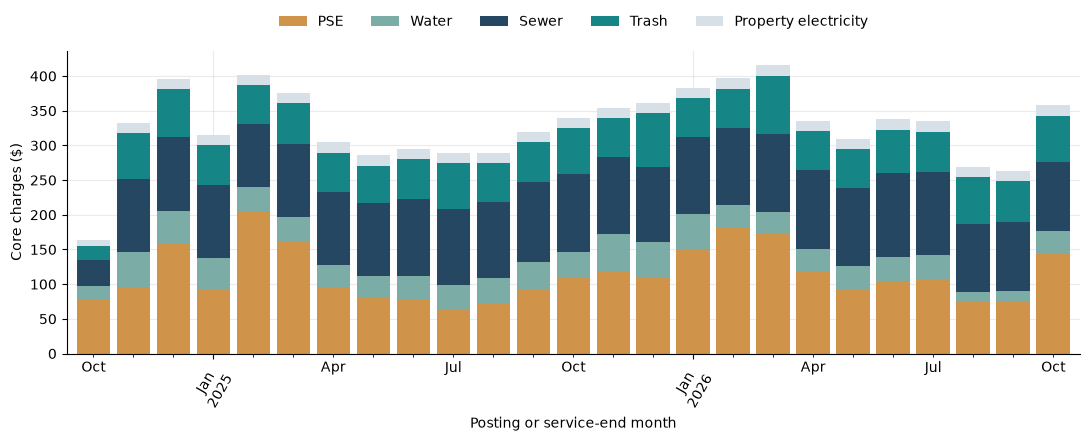

In [4]:

changes = cost[[*SERVICES, CORE]].diff().add_prefix("change_")
display(cost[[*SERVICES, CORE, "unit_all_listed"]].join(changes).round(2))
fig, ax = plt.subplots(figsize=(11, 4.6))
plot = cost[[*SERVICES]].rename(columns={
    'pse_full':'PSE', 'water':'Water', 'sewer':'Sewer', 'trash':'Trash',
    'property_electric':'Property electricity'})
plot.plot.bar(stacked=True, ax=ax, color=['#CD8D40','#75A8A1','#193D5A','#087F80','#D6DFE6'],
              width=.84, alpha=.95)
ax.set(ylabel='Core charges ($)', xlabel='Posting or service-end month')
ax.tick_params(axis='x',labelrotation=60)
ax.legend(ncol=5,frameon=False,loc='upper center',bbox_to_anchor=(.5,1.16))

idx = {month: i for i, month in enumerate(cost.index.astype(str))}
def y_total(month):
    return float(cost.loc[month, SERVICES].sum())

ax.annotate('Partial first month', xy=(idx['2024-10'], y_total('2024-10')),
            xytext=(idx['2024-10'] + 1.0, y_total('2024-10') + 40),
            arrowprops=dict(arrowstyle='->', color='#555555'), fontsize=9, color='#444444')
ax.annotate('Feb 2025 +$86.78', xy=(idx['2025-02'], y_total('2025-02')),
            xytext=(idx['2025-02'] - 2.0, y_total('2025-02') + 55),
            arrowprops=dict(arrowstyle='->', color='#555555'), fontsize=9)
ax.annotate('Apr 2026 -$80.10', xy=(idx['2026-04'], y_total('2026-04')),
            xytext=(idx['2026-04'] - 2.2, y_total('2026-04') - 70),
            arrowprops=dict(arrowstyle='->', color='#555555'), fontsize=9)
ax.annotate('Oct 2026 +$94.70', xy=(idx['2026-10'], y_total('2026-10')),
            xytext=(idx['2026-10'] - 3.2, y_total('2026-10') + 45),
            arrowprops=dict(arrowstyle='->', color='#555555'), fontsize=9)

fig.tight_layout()
plt.show()


## 3. Separate electricity usage from effective price
Pair eleven bill-end months from December 2024–October 2025 and December 2025–October 2026. The periods both span 336 billed days. Effective price is full current charges divided by meter kWh. The midpoint method gives an exact and order-independent breakdown of the observed cost change. A within-month decomposition and leave-one-pair-out checks assess sensitivity. Statement line items distinguish the Power Cost Adjustment from other factors in the effective price.

Monthly pairs
       prior_days  prior_kwh  prior_pse_statement  recent_days  recent_kwh  recent_pse_statement  usage_effect  price_effect  bill_change
month                                                                                                                                    
Dec         30.00   1,046.00               158.58        29.00      612.00                110.62        -72.12         24.16       -47.96
Jan         33.00     621.00                91.01        33.00      770.00                149.54         25.39         33.14        58.53
Feb         29.00   1,248.00               205.84        29.00      877.00                182.95        -69.29         46.40       -22.89
Mar         29.00     957.00               160.79        32.00      822.00                173.09        -25.55         37.85        12.30
Apr         32.00     582.00                96.44        29.00      555.00                116.96         -5.08         25.60        20.52
May         29.00   

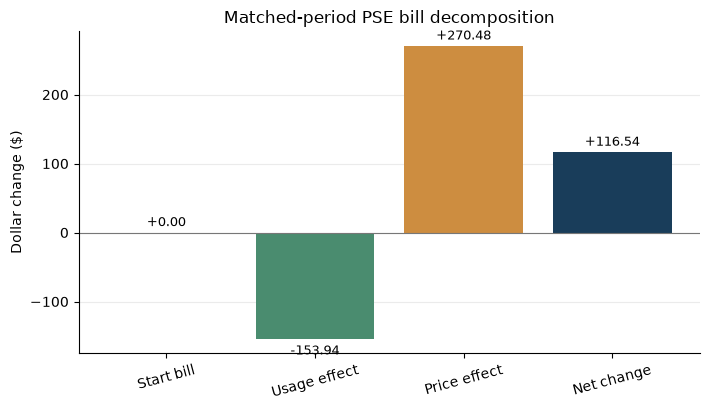

In [5]:

"""Compare PSE billing periods ending in the same calendar month one year apart."""
from pathlib import Path
import numpy as np
import pandas as pd

STATEMENT_COLUMNS = ["month", "service_start", "service_end", "days", "kwh",
                     "pse_statement", "city_tax", "pse_separate_credit",
                     "printed_subtotal_line_gap", "bill_total_arithmetic_gap"]

def prepare_statements(data_dir=DATA):
    bills = pd.read_csv(data_dir / "apartment_utility_monthly.csv", usecols=STATEMENT_COLUMNS)
    bills = bills.loc[bills.pse_statement.notna()].copy().set_index("month").sort_index()
    assert bills.index.is_unique and len(bills) == 23
    days_inclusive = (pd.to_datetime(bills.service_end) - pd.to_datetime(bills.service_start)).dt.days + 1
    assert bills.days.eq(days_inclusive).all()
    assert bills.kwh.gt(0).all()
    assert bills.printed_subtotal_line_gap.abs().le(.01).all()
    assert bills.bill_total_arithmetic_gap.abs().le(.01).all()
    return bills

def midpoint(old_kwh, new_kwh, old_cost, new_cost):
    old_price = old_cost / old_kwh
    new_price = new_cost / new_kwh
    usage_effect = (new_kwh - old_kwh) * (old_price + new_price) / 2
    price_effect = (new_price - old_price) * (old_kwh + new_kwh) / 2
    assert np.allclose(usage_effect + price_effect, new_cost - old_cost, atol=1e-8, rtol=0)
    return usage_effect, price_effect

def matched_months(bills):
    windows = []
    for label, start, end in [("prior", "2024-12", "2025-10"), ("recent", "2025-12", "2026-10")]:
        periods = bills.loc[start:end, ["days", "kwh", "pse_statement"]].copy()
        periods.index = pd.PeriodIndex(periods.index, freq="M").strftime("%b")
        assert len(periods) == 11
        windows.append(periods.add_prefix(label + "_"))
    pairs = windows[0].join(windows[1], validate="one_to_one")
    pairs["usage_effect"], pairs["price_effect"] = pair_effect(pairs)
    pairs["bill_change"] = pairs.recent_pse_statement - pairs.prior_pse_statement
    return pairs

def pair_effect(pairs):
    return midpoint(pairs.prior_kwh, pairs.recent_kwh, pairs.prior_pse_statement, pairs.recent_pse_statement)

def summarize_pairs(pairs):
    sums = pairs.sum(numeric_only=True)
    aggregate_usage, aggregate_price = pair_effect(sums)
    alternative = pair_effect(pairs.drop(index="Oct").sum(numeric_only=True))
    leave_one_out = [pair_effect(pairs.drop(index=name).sum(numeric_only=True)) for name in pairs.index]
    print("Monthly pairs")
    print(pairs.round(3).to_string())
    print("Period totals")
    for label in ("prior", "recent"):
        cost, kwh, days = (sums[f"{label}_{key}"] for key in ("pse_statement", "kwh", "days"))
        print(label, dict(cost=round(cost,2), kwh=kwh, days=days, cents_kwh=100*cost/kwh, kwh_day=kwh/days))
    print("aggregate effects", aggregate_usage, aggregate_price)
    print("sum of within-month effects", sums["usage_effect"], sums["price_effect"])
    print("exclude October in both periods", tuple(float(term) for term in alternative))
    print("leave one matched month out ranges", np.min(leave_one_out,axis=0), np.max(leave_one_out,axis=0))
    print("monthly counts positive usage, price, bill", pairs[["usage_effect","price_effect","bill_change"]].gt(0).sum().to_dict())
    return sums, aggregate_usage, aggregate_price

def charge_component_check(bills, data_dir=DATA):
    lines = pd.read_csv(data_dir / "pse_printed_charge_lines.csv")
    labels = lines.charge.str
    lines["component"] = np.select(
        [labels.startswith("Tier"), labels.startswith("Power Cost Adjustment"), labels.startswith("Basic Charge"),
         labels.startswith("Electric Cons.")],
        ["Tiered electricity", "Power Cost Adjustment", "Basic charge", "Conservation"],
        default="Other charges and credits")
    assert lines.rate_times_kwh_gap_usd.dropna().abs().le(.00501).all()
    by_bill = lines.pivot_table(index="month", columns="component", values="printed_usd", aggfunc="sum")
    by_bill = by_bill.join(bills[["city_tax","pse_separate_credit","pse_statement","kwh"]],validate="one_to_one")
    components = [c for c in by_bill.columns if c not in {"pse_statement","kwh"}]
    assert np.allclose(by_bill[components].sum(axis=1),by_bill.pse_statement,atol=.01,rtol=0)
    old = by_bill.loc["2024-12":"2025-10"].sum()
    new = by_bill.loc["2025-12":"2026-10"].sum()
    totals = pd.concat({"prior_usd":old,"recent_usd":new,"change_usd":new-old},axis=1)
    for key in ("prior","recent"):
        totals[f"{key}_cents_kwh"] = 100*totals[f"{key}_usd"]/totals.loc["kwh",f"{key}_usd"]
    print("Statement components")
    print(totals.drop(index="kwh").round(4).to_string())
    return totals

statements = prepare_statements()
pairwise = matched_months(statements)
sums, agg_usage, agg_price = summarize_pairs(pairwise)
statement_components = charge_component_check(statements)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
steps = pd.Series({"Start bill": 0.0, "Usage effect": agg_usage, "Price effect": agg_price, "Net change": agg_usage + agg_price})
colors = ['#B8C7D6', '#4A8C6F' if agg_usage < 0 else '#087F80', '#CD8D40' if agg_price >= 0 else '#A65252', '#193D5A']
ax.bar(steps.index, steps.values, color=colors)
ax.axhline(0, color='#777777', linewidth=0.8)
for i, val in enumerate(steps.values):
    ax.text(i, val + (5 if val >= 0 else -9), f"{val:+.2f}", ha='center', va='bottom' if val >= 0 else 'top', fontsize=9)
ax.set_ylabel('Dollar change ($)')
ax.set_title('Matched-period PSE bill decomposition')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()


## 4. Estimate the weather relationship
Daily outdoor temperature is the average of the NOAA maximum and minimum. Sum base-65°F degree days across inclusive PSE service dates. Divide the predictor and outcome by billed days. A simple linear fit estimates the relationship between colder days and electricity use. The comparison with a constant model uses six consecutive holdout blocks. This is a retrospective check, with training observations potentially on either side of the holdout. HC3 uncertainty is approximate, especially given the small series. The analysis varies the heating threshold and adds cooling as sensitivity checks. Weather association cannot isolate changes in household behavior.

In [6]:
"""Associate interval-aligned NOAA weather with PSE consumption."""
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import t


def align_weather(bills, weather, base=65):
    """Create observed degree days using the same inclusive dates as each bill."""
    mean_f = (weather.tmax_f + weather.tmin_f) / 2
    weather = weather.assign(hdd=(base - mean_f).clip(lower=0), cdd=(mean_f - base).clip(lower=0))
    totals = []
    for bill in bills.itertuples():
        start, end = pd.Timestamp(bill.service_start), pd.Timestamp(bill.service_end)
        span = weather.loc[start:end]
        assert span.index.equals(pd.date_range(start, end)) and len(span) == bill.days
        assert span[["hdd","cdd"]].notna().all().all()
        totals.append((span.hdd.sum(), span.cdd.sum()))
    frame = bills.assign(hdd=[row[0] for row in totals], cdd=[row[1] for row in totals])
    return frame.assign(kwh_day=frame.kwh/frame.days, hdd_day=frame.hdd/frame.days, cdd_day=frame.cdd/frame.days)

def design(data, columns):
    return np.column_stack([np.ones(len(data)), data[columns].to_numpy()])

def fit(data, columns, response="kwh_day"):
    """OLS with HC3 standard errors and approximate t intervals."""
    x = design(data, columns)
    y = data[response].to_numpy()
    b = np.linalg.lstsq(x, y, rcond=None)[0]
    fitted = x@b
    u = y - fitted
    bread = np.linalg.inv(x.T@x)
    h = ((x@bread)*x).sum(axis=1)
    scaled_scores = x*(u/(1-h))[:,None]
    hc3 = bread@scaled_scores.T@scaled_scores@bread
    scores = x*u[:,None]
    lag_one = scores[1:].T@scores[:-1]
    hac1 = bread@(scores.T@scores + .5*(lag_one+lag_one.T))@bread * len(y)/(len(y)-x.shape[1])
    critical = t.ppf(.975,len(y)-x.shape[1])
    se = np.sqrt(np.diag(hc3))
    table = pd.DataFrame({"estimate":b,"low_hc3":b-critical*se,"high_hc3":b+critical*se,
                          "se_hac_lag1":np.sqrt(np.diag(hac1))},index=["intercept",*columns])
    r2 = 1 - (u@u)/((y-y.mean())@(y-y.mean()))
    return table, r2, u

def blocked_mae(data, columns):
    """Hold out contiguous blocks for retrospective sensitivity, with same splits for all models."""
    errors = []
    for block in np.array_split(np.arange(len(data)), 6):
        train = data.drop(index=data.index[block])
        test = data.iloc[block]
        coefs = np.linalg.lstsq(design(train, columns), train.kwh_day, rcond=None)[0]
        errors.extend(test.kwh_day - design(test,columns)@coefs)
    return np.mean(np.abs(errors))

def period_change(data):
    old = data.loc["2024-12":"2025-10"]
    new = data.loc["2025-12":"2026-10"]
    assert len(old) == len(new) == 11
    return old, new, new[["days","kwh","hdd","cdd"]].sum() - old[["days","kwh","hdd","cdd"]].sum()

def weather_results():
    bills = pd.read_csv(DATA/"apartment_utility_monthly.csv",index_col="month").dropna(subset=["kwh"])
    weather = pd.read_csv(DATA/"seatac_weather_daily.csv",parse_dates=["date"],index_col="date")
    aligned = align_weather(bills,weather)
    assert np.allclose(aligned.hdd, aligned.bill_hdd65) and np.allclose(aligned.cdd, aligned.bill_cdd65)
    old, new, change = period_change(aligned)
    print("Period totals\n",pd.DataFrame([old[["days","kwh","hdd","cdd"]].sum(),new[["days","kwh","hdd","cdd"]].sum(),change],index=["prior","recent","change"]))
    for features in [[],["hdd_day"],["hdd_day","cdd_day"]]:
        estimates, r2, resid = fit(aligned, features)
        print(features, "\n", estimates, "\nR2", r2, "blocked MAE",blocked_mae(aligned,features),"lag1 residual corr",np.corrcoef(resid[1:],resid[:-1])[0,1])
        print("largest residual", aligned.index[np.abs(resid).argmax()], resid[np.abs(resid).argmax()])
        if features:
            delta_wx = change[["hdd","cdd"]].rename(index=lambda name:name+"_day")
            contribution = estimates.estimate.reindex(delta_wx.index,fill_value=0)@delta_wx
            print("modeled weather change", contribution)
    primary, _, _ = fit(aligned, ["hdd_day"])
    beta = primary.loc["hdd_day"]
    print("HDD contribution/interval and residual", beta[["estimate","low_hc3","high_hc3"]]*change.hdd, change.kwh-beta.estimate*change.hdd)
    print("prior-only fit", fit(old,["hdd_day"])[0].loc["hdd_day","estimate"]*change.hdd)
    for base in [60,70]:
        sensitivity = align_weather(bills,weather,base)
        _, _, delta = period_change(sensitivity)
        print("base sensitivity",base,fit(sensitivity,["hdd_day"])[0].loc["hdd_day","estimate"]*delta.hdd)
    leave_one_out = [fit(aligned.drop(index=month),["hdd_day"])[0].loc["hdd_day","estimate"]*change.hdd
                     for month in aligned.index]
    print("Leave one out min and max", min(leave_one_out),max(leave_one_out))
    pair = pd.DataFrame(new[["kwh_day","hdd_day"]].to_numpy()-old[["kwh_day","hdd_day"]].to_numpy(),
                        columns=["kwh_day","hdd_day"])
    print("matched differences fit",fit(pair,["hdd_day"])[:2])
weather_results()

Period totals
          days      kwh      hdd    cdd
prior  336.00 7,226.00 3,958.50 311.00
recent 336.00 6,405.00 3,700.50 249.50
change   0.00  -821.00  -258.00 -61.50
[] 
            estimate  low_hc3  high_hc3  se_hac_lag1
intercept     20.52    16.87     24.18         2.05 
R2 0.0 blocked MAE 7.13731419801463 lag1 residual corr 0.4516534566215321
largest residual 2025-02 22.51018212484667
['hdd_day'] 
            estimate  low_hc3  high_hc3  se_hac_lag1
intercept     11.52     8.64     14.41         1.16
hdd_day        0.78     0.43      1.13         0.12 
R2 0.6796331074721926 blocked MAE 4.225919928913337 lag1 residual corr -0.21903336992249342
largest residual 2025-01 -10.766251999851544
modeled weather change -200.3505694427188
['hdd_day', 'cdd_day'] 
            estimate  low_hc3  high_hc3  se_hac_lag1
intercept      8.70     0.76     16.64         2.66
hdd_day        0.93     0.32      1.53         0.19
cdd_day        1.38    -1.57      4.34         0.99 
R2 0.6962472553532

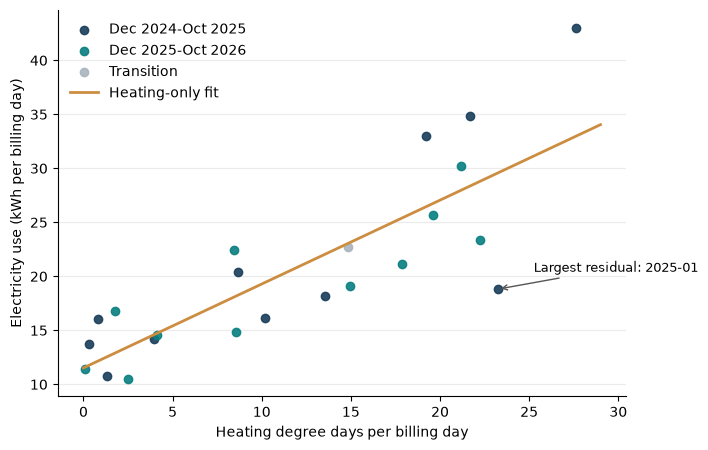

Largest weather-model residual month 2025-01 {'kwh_day': 18.82, 'hdd_day': 23.26, 'residual': -10.77}


In [7]:

meter = pd.read_csv(DATA/"apartment_utility_monthly.csv",index_col="month").dropna(subset=["kwh"])
observed_weather = pd.read_csv(DATA/"seatac_weather_daily.csv",parse_dates=["date"],index_col="date")
weather_aligned = align_weather(meter, observed_weather)
heating_fit, _, _ = fit(weather_aligned, ["hdd_day"])

period_labels = pd.Series('Transition', index=weather_aligned.index)
period_labels.loc['2024-12':'2025-10'] = 'Dec 2024-Oct 2025'
period_labels.loc['2025-12':'2026-10'] = 'Dec 2025-Oct 2026'
colors = {'Dec 2024-Oct 2025': '#193D5A', 'Dec 2025-Oct 2026': '#087F80', 'Transition': '#A9B4BE'}

fig, ax = plt.subplots(figsize=(7.2, 4.6))
for label in ['Dec 2024-Oct 2025', 'Dec 2025-Oct 2026', 'Transition']:
    subset = weather_aligned.loc[period_labels.eq(label)]
    if not subset.empty:
        ax.scatter(subset.hdd_day, subset.kwh_day, color=colors[label], label=label, alpha=.9)

x = np.linspace(0, 29, 80)
ax.plot(x, heating_fit.estimate.intercept + heating_fit.estimate.hdd_day*x, color='#CD8D40', linewidth=2, label='Heating-only fit')
ax.set(xlabel='Heating degree days per billing day',ylabel='Electricity use (kWh per billing day)')
ax.legend(frameon=False)

resid = weather_aligned.kwh_day - (heating_fit.estimate.intercept + heating_fit.estimate.hdd_day * weather_aligned.hdd_day)
outlier_month = resid.abs().idxmax()
outlier = weather_aligned.loc[outlier_month]
ax.annotate(f"Largest residual: {outlier_month}",
            xy=(outlier.hdd_day, outlier.kwh_day),
            xytext=(outlier.hdd_day + 2, outlier.kwh_day + 1.6),
            arrowprops=dict(arrowstyle='->', color='#555555'), fontsize=9)

fig.tight_layout()
plt.show()

print('Largest weather-model residual month', outlier_month,
      {'kwh_day': round(float(outlier.kwh_day), 2), 'hdd_day': round(float(outlier.hdd_day), 2), 'residual': round(float(resid.loc[outlier_month]), 2)})


In [8]:
def climate_context(data_dir=DATA):
    normals = pd.read_csv(data_dir/"seatac_daily_degree_day_normals.csv",index_col="DATE")
    bills = pd.read_csv(data_dir/"apartment_utility_monthly.csv",index_col="month")
    records = []
    for start,end in [("2024-12","2025-10"),("2025-12","2026-10"),("2025-11","2026-10")]:
        window = bills.loc[start:end]
        dates = pd.date_range(window.service_start.iloc[0],window.service_end.iloc[-1])
        norm = normals.reindex(dates.strftime("%m-%d"))
        assert len(dates) == window.days.sum() and norm.notna().all().all()
        observed_hdd = window.bill_hdd65.sum()
        normal_hdd = norm["DLY-HTDD-NORMAL"].sum()
        records.append({"start":start,"end":end,"observed_hdd":observed_hdd,"normal_hdd":normal_hdd,
                        "hdd_deviation_pct":100*(observed_hdd/normal_hdd-1),
                        "observed_cdd":window.bill_cdd65.sum(),
                        "normal_cdd":norm["DLY-CLDD-NORMAL"].sum()})
    table = pd.DataFrame(records)
    print("NOAA normals by meter service window")
    print(table.round(2).to_string(index=False))
    return table



climate_periods = climate_context()

NOAA normals by meter service window
  start     end  observed_hdd  normal_hdd  hdd_deviation_pct  observed_cdd  normal_cdd
2024-12 2025-10      3,958.50    3,896.50               1.59        311.00      264.10
2025-12 2026-10      3,700.50    3,896.50              -5.03        249.50      264.10
2025-11 2026-10      4,130.00    4,375.40              -5.61        249.50      264.10


## 5. Compare regional use and the matched apartment distribution
The EIA regional comparison filters to Puget Sound Energy, Washington, bundled residential accounts. Calculate kWh per customer per day in each calendar month. Approximate within-month daily demand by its monthly mean and average over each apartment bill's service days. October 2026 lacks complete regional coverage in the published release, with 2026 observations preliminary.

The size benchmark uses survey-weighted 2020 RECS for two-bedroom Washington apartments of 1,000–1,499 square feet in buildings of five or more units. The 60 survey jackknife replicates provide approximate uncertainty for the mean. Two-person, adjacent size, and nearby-state estimates are sensitivity checks. These published inputs supply distinct geographic and size comparisons.

Covered and missing intervals
         apt_kwh_day  regional_kwh_customer_day  regional_days_covered
month                                                                 
2024-12        34.87                      35.29                     30
2025-01        18.82                      39.38                     33
2025-02        43.03                      39.87                     29
2025-03        33.00                      33.62                     29
2025-04        18.19                      27.46                     32
2025-05        16.14                      23.16                     29
2025-06        14.20                      21.97                     30
2025-07        10.73                      23.19                     33
2025-08        13.76                      24.24                     29
2025-09        16.03                      21.92                     32
2025-10        20.40                      24.02                     30
2025-11        22.76                      28.94

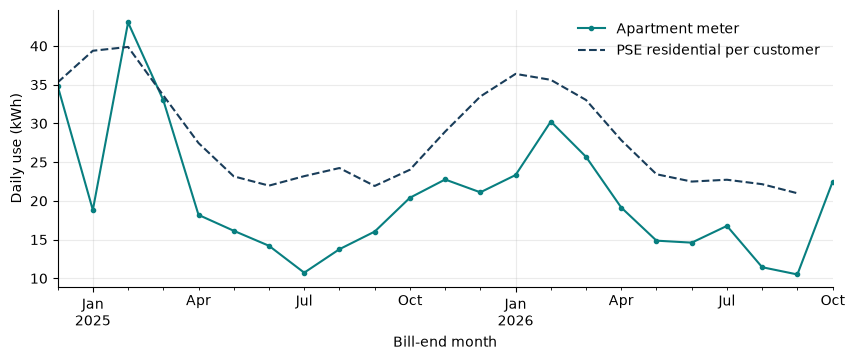

In [9]:

"""Compare PSE residential-sector usage with bill-level apartment usage."""
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr


def prepare_inputs(data_dir=DATA):
    bills = pd.read_csv(data_dir / "apartment_utility_monthly.csv", index_col="month")
    bills = bills.loc[bills.kwh.notna(), ["service_start", "service_end", "days", "kwh", "pse_statement"]].copy()
    bills["apt_kwh_day"] = bills.kwh / bills.days
    region = pd.read_csv(data_dir / "pse_residential_electricity_monthly.csv", index_col="month")
    assert (region.eia_utility_id.eq(15500) & region.state.eq("WA")).all()
    region.index = pd.PeriodIndex(region.index, freq="M")
    assert region.index.equals(pd.period_range(region.index.min(), region.index.max(), freq="M"))
    region["regional_kwh_customer_day"] = 1000 * region.sales_mwh / region.customers / region.index.days_in_month
    return bills, region


def align_to_service_days(bills, region):
    rows = []
    for bill in bills.itertuples():
        days = pd.date_range(bill.service_start, bill.service_end)
        assert len(days) == bill.days
        spans = region.reindex(days.to_period("M"))
        usage = spans.regional_kwh_customer_day
        rows.append({"month": bill.Index, "regional_days_covered": int(usage.notna().sum()),
                     "regional_kwh_customer_day": usage.mean() if usage.notna().all() else np.nan,
                     "regional_preliminary": spans.status.eq("Preliminary").any()})
    return bills.join(pd.DataFrame(rows).set_index("month"), validate="one_to_one")


def monthly_pairs(data):
    columns = ["apt_kwh_day", "regional_kwh_customer_day"]
    matched = []
    for start, end, label in [("2024-12", "2025-09", "prior"), ("2025-12", "2026-09", "recent")]:
        window = data.loc[start:end, [*columns,"days"]].copy()
        assert len(window) == 10 and window[columns].notna().all().all()
        window.index = pd.PeriodIndex(window.index, freq="M").strftime("%b")
        matched.append(window.add_prefix(label + "_"))
    return matched[0].join(matched[1], validate="one_to_one")


def summarize(aligned, region):
    sample = aligned.dropna(subset=["regional_kwh_customer_day"])
    print("Covered and missing intervals")
    print(aligned[["apt_kwh_day", "regional_kwh_customer_day", "regional_days_covered"]].round(3).to_string())
    print("Spearman aligned", spearmanr(sample.apt_kwh_day, sample.regional_kwh_customer_day).statistic)
    print("Spearman calendar (sensitivity)", spearmanr(sample.apt_kwh_day, region.reindex(
        pd.PeriodIndex(sample.index, freq="M")).regional_kwh_customer_day).statistic)

    relative = 100 * (sample.apt_kwh_day / sample.regional_kwh_customer_day - 1)
    print("Apartment vs regional level gap (%)",
          {"mean": round(relative.mean(), 1), "min": round(relative.min(), 1), "max": round(relative.max(), 1)})
    print("Months apartment below regional", int((relative < 0).sum()), "of", len(relative))

    periods = pd.PeriodIndex(sample.index, freq="M")
    rel = sample[["apt_kwh_day","regional_kwh_customer_day"]]
    for season, months in [("winter", [12,1,2]), ("summer", [6,7,8,9])]:
        mask = periods.month.isin(months)
        print(season, mask.sum(), dict(zip(rel, np.average(rel.loc[mask],weights=sample.loc[mask,"days"],axis=0))))

    pairs = monthly_pairs(aligned)
    pair_means = {}
    for label in ("prior", "recent"):
        print(label, pairs[f"{label}_days"].sum())
        pair_means[label] = pd.Series({col:np.average(pairs[f"{label}_{col}"],weights=pairs[f"{label}_days"])
                                      for col in ["apt_kwh_day","regional_kwh_customer_day"]})
    print("period rate")
    print(pd.DataFrame(pair_means))
    print("relative change %", 100*(pair_means["recent"]/pair_means["prior"]-1))
    print("Reconciliation: -11.4% uses 11 matched Dec-Oct bills; -13.4% uses 10 months where regional data overlaps through Sep.")

    raw_calendar = region.regional_kwh_customer_day
    for year in (2024,2025):
        dates = pd.period_range(f"{year}-12",f"{year+1}-09",freq="M")
        print("calendar comparison",year,np.average(raw_calendar.loc[dates], weights=dates.days_in_month))
    both = pd.DataFrame({col: (pairs[f"recent_{col}"] / pairs[f"prior_{col}"] - 1)*100
                         for col in ["apt_kwh_day","regional_kwh_customer_day"]})
    print("monthly changes %")
    print(both.round(3))
    print("within month changes Spearman",spearmanr(both.iloc[:,0],both.iloc[:,1]).statistic)
    print("same direction",(np.sign(both.iloc[:,0])==np.sign(both.iloc[:,1])).sum())
    prior_only = sample.loc[~sample.regional_preliminary]
    print("Final regional only",len(prior_only),spearmanr(prior_only.apt_kwh_day,prior_only.regional_kwh_customer_day).statistic)

    jan = sample.loc['2025-01']
    print("Jan 2025 daily usage check", {"apt_kwh_day": round(float(jan.apt_kwh_day),2),
                                         "regional_kwh_day": round(float(jan.regional_kwh_customer_day),2)})

regional_bills, regional_data = prepare_inputs()
aligned_regional = align_to_service_days(regional_bills, regional_data)
summarize(aligned_regional, regional_data)
fig, ax = plt.subplots()
aligned_regional[['apt_kwh_day','regional_kwh_customer_day']].set_axis(
    pd.to_datetime(aligned_regional.index)).rename(columns={
        'apt_kwh_day':'Apartment meter','regional_kwh_customer_day':'PSE residential per customer'
    }).plot(ax=ax,color=['#087F80','#193D5A'],style=['-o','--'],markersize=3)
ax.set(xlabel='Bill-end month',ylabel='Daily use (kWh)')
ax.legend(frameon=False)
plt.show()


In [10]:
RECS_WEIGHTS = ["NWEIGHT", *(f"NWEIGHT{i}" for i in range(1, 61))]

def weighted_recs_estimates(group, apartment_kwh):
    y, w = group.KWH.to_numpy(), group.NWEIGHT.to_numpy()
    mean = np.average(y,weights=w)
    above = np.average(y < apartment_kwh,weights=w)
    rep = group[RECS_WEIGHTS[1:]].to_numpy()
    assert (rep.sum(axis=0)>0).all()
    replicate_means = y@rep/rep.sum(axis=0)
    se = np.sqrt((59/60)*np.square(replicate_means-mean).sum())
    order = np.argsort(y)
    qs = y[order][np.searchsorted(np.cumsum(w[order]),np.array([.25,.5,.75])*w.sum())]
    return [len(y),mean,*qs,se,mean-1.645*se,mean+1.645*se,above]

def recs_benchmark(data_dir=DATA):
    data = pd.read_csv(data_dir/"recs2020_matched_public_extract.csv")
    was = data.state_postal.eq("WA")
    pacific = data.DIVISION.eq("Pacific") & data.state_postal.isin(["WA","OR","CA"])
    estimates = []
    statement = pd.read_csv(data_dir/"apartment_utility_monthly.csv",index_col="month")
    recent = statement.loc["2025-11":"2026-10"]
    assert len(recent)==12 and recent.kwh.notna().all() and recent.days.sum()==365
    apt_kwh = recent.kwh.sum()
    main = data.TYPEHUQ.eq(5) & data.BEDROOMS.eq(2) & data.TOTSQFT_EN.between(1000,1499)
    broad = data.BEDROOMS.eq(2) & data.TOTSQFT_EN.between(1000,1499)
    scopes = [
        ("WA 1000–1499 ft² 2BR building 5+ units",was & main),
        ("WA 1000–1499 ft² 2BR all apartment buildings",was & broad),
        ("WA 1000–1499 ft² 2BR 5+ two occupants",was & main & data.NHSLDMEM.eq(2)),
        ("WA 1000–1499 ft² 2BR 5+ electric heat",was & main & data.FUELHEAT.eq(5)),
        ("WA or OR 1000–1499 ft² 2BR 5+",data.state_postal.isin(["WA","OR"]) & main),
        ("Pacific mainland 1000–1499 ft² 2BR 5+",pacific & main),
        ("WA 950–1450 ft² 2BR building 5+ units",was & data.TYPEHUQ.eq(5) & data.BEDROOMS.eq(2)
            & data.TOTSQFT_EN.between(950,1450)),
    ]
    for label,mask in scopes:
        estimates.append(weighted_recs_estimates(data.loc[mask],apt_kwh))
    table = pd.DataFrame(estimates,index=[name for name,_ in scopes],
                         columns=["n","mean","p25","median","p75","mean_se","mean_90ci_low","mean_90ci_high","fraction_below_apt"])
    print("Your annual meter kWh:",apt_kwh," and kWh/ft²:",apt_kwh/1195)
    print("RECS estimates\n",table.round(3).to_string())
    return table
recs_results = recs_benchmark()

Your annual meter kWh: 7065.0  and kWh/ft²: 5.912133891213389
RECS estimates
                                                n     mean      p25   median       p75  mean_se  mean_90ci_low  mean_90ci_high  fraction_below_apt
WA 1000–1499 ft² 2BR building 5+ units        14 8,518.41 6,514.73 7,647.99 10,886.63   966.35       6,928.77       10,108.06                0.45
WA 1000–1499 ft² 2BR all apartment buildings  16 8,646.02 6,777.23 7,647.99 11,998.21   847.09       7,252.56       10,039.47                0.38
WA 1000–1499 ft² 2BR 5+ two occupants          9 8,459.47 6,362.16 7,647.99 13,308.82 1,423.54       6,117.76       10,801.18                0.44
WA 1000–1499 ft² 2BR 5+ electric heat         10 9,066.37 6,777.23 7,865.59 13,308.82 1,152.17       7,171.05       10,961.69                0.44
WA or OR 1000–1499 ft² 2BR 5+                 20 8,341.51 6,686.30 7,647.99 10,886.63   721.40       7,154.81        9,528.23                0.46
Pacific mainland 1000–1499 ft² 2BR 5+         

## 6. Benchmark spending
Use November 2025 through October 2026. Include full PSE, water, sewer and trash for the same-service comparison. The separately listed property electricity charge has no clear counterpart in the peer disclosures, so it is shown separately in the core figure. Elements and Brio publish property-wide estimates and include gas in their energy amounts. ARCH is a two-bedroom program allowance. The Greater Bellevue Census comparison uses 2024 one-year housing data, with annual water and sewer amounts divided by 12. The notebook uses an adjusted-price sensitivity based on general Seattle-area CPI-U. No apartment-level 98004 sample is available for a precise mean or formal significance test.

Average documented apartment cost and published estimates
                   Elements  Brio   ARCH  observed_apartment
Energy                   71    70 137.00              120.64
Water and sewer          96   117    NaN              144.84
Trash                    45    34    NaN               62.79
Water/sewer/trash       141   151 112.00              207.64
Core bundle             212   221 249.00              328.28
Dollar gaps
                   Elements   Brio   ARCH
Energy                49.64  50.64 -16.36
Water and sewer       48.84  27.84    NaN
Trash                 17.79  28.79    NaN
Water/sewer/trash     66.64  56.64  95.64
Core bundle          116.28 107.28  79.28
Percentage gaps
                   Elements  Brio   ARCH
Energy                69.92 72.35 -11.94
Water and sewer       50.88 23.80    NaN
Trash                 39.54 84.68    NaN
Water/sewer/trash     47.26 37.51  85.39
Core bundle           54.85 48.54  31.84
Months above estimates (where comparable)
        

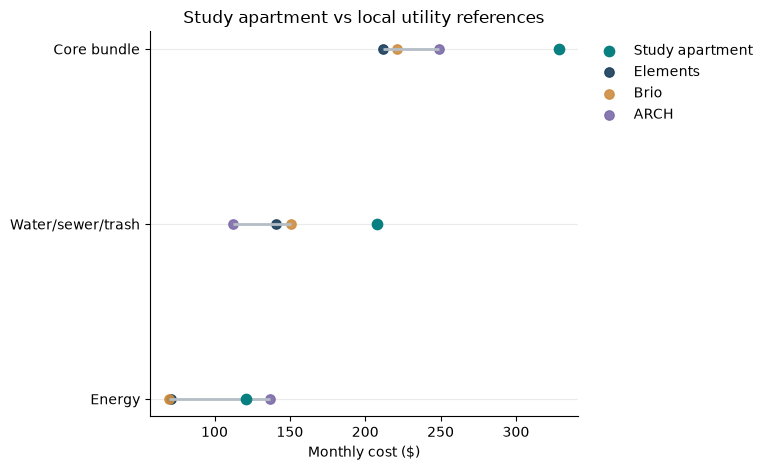

CPI sensitivity factor 1.0760915843089662
ACS summary
                               n   mean  mean_ci_lo  mean_ci_hi  median    q25    q75  q75_oct_2026  pct_below_observed_2024  pct_below_observed_oct2026  winsor_upper5_mean  observed_usd
water_sewer_separate          59  74.08       54.03       94.13   41.67  11.67 125.00        134.51                    77.81                       77.81               72.60        144.84
water_sewer_separate_two_occ  35  67.83       43.33       92.33   41.67  10.00 116.67        125.54                    83.49                       83.49               67.83        144.84
electricity_separate          93 208.21       93.99      322.44  100.00  80.00 160.00        172.18                    61.86                       57.03              120.73        120.64
bundle_all                    96 258.89      138.69      379.10  140.00 100.00 216.67        233.15                    84.82                       79.22              162.97        265.49
bundle_both

In [11]:

"""Benchmark comparable monthly service bundles with portal-verified apartment charges."""
from pathlib import Path
import numpy as np
import pandas as pd

CPI_2024_HALVES = (351.426, 355.551)
CPI_OCT_2026 = 380.386
INFLATION_SENSITIVITY = CPI_OCT_2026 / np.mean(CPI_2024_HALVES)
ACS_WEIGHTS = ["WGTP", *(f"WGTP{i}" for i in range(1, 81))]


def load_apartment(data_dir=DATA):
    apartment = pd.read_csv(data_dir/"apartment_monthly_portal_verified.csv",index_col="month")
    recent = apartment.loc["2025-11":"2026-10"].copy()
    assert len(recent) == 12
    assert recent[["water","sewer","trash","pse_verified","property_electric"]].notna().all().all()
    recent["electricity_gas_observed"] = recent.pse_verified
    recent["water_sewer_observed"] = recent.water + recent.sewer
    recent["water_sewer_trash_observed"] = recent.water_sewer_observed + recent.trash
    recent["electricity_gas_water_sewer_observed"] = recent.pse_verified + recent.water_sewer_observed
    recent["matched_core_observed"] = recent.pse_verified + recent.water_sewer_trash_observed
    return recent


def compare_local_properties(recent, data_dir=DATA):
    peers = pd.read_csv(data_dir/"downtown_bellevue_posted_utility_estimates.csv",index_col="property")
    allowance = pd.read_csv(data_dir/"arch_2br_allowance_2026.csv",index_col="service").monthly_usd
    labels = ["Energy", "Water and sewer", "Trash", "Water/sewer/trash", "Core bundle"]
    benchmarks = pd.DataFrame(index=labels)
    for property_name, row in peers.iterrows():
        benchmarks[property_name] = [row.electricity_usd + row.gas_usd,row.water_sewer_usd,row.trash_usd,
                                     row.water_sewer_usd + row.trash_usd,row.core_bundle_total_usd]
    benchmarks["ARCH"] = [allowance.loc["Electricity and gas"],np.nan,np.nan,
                          allowance.loc["Water, sewer and garbage"],allowance.sum()]
    monthly = recent[["electricity_gas_observed","water_sewer_observed","trash","water_sewer_trash_observed","matched_core_observed"]].copy()
    monthly.columns = labels
    mean = monthly.mean()

    print("Average documented apartment cost and published estimates")
    print(benchmarks.assign(observed_apartment=mean).round(2))
    print("Dollar gaps")
    print(benchmarks.rsub(mean,axis=0).round(2))
    print("Percentage gaps")
    print((100*(benchmarks.rdiv(mean,axis=0)-1)).round(2))
    print("Months above estimates (where comparable)")
    print(pd.DataFrame({name:monthly.gt(values).sum().where(values.notna()) for name,values in benchmarks.items()}))
    print("Personal core / listed all-in", recent[["personal_core_workbook_equal_split","personal_all_listed_workbook_equal_split"]].mean().round(2))
    print("Apartment core with property electric", recent.unit_core_including_property_electric.mean().round(2))

    core_gaps = benchmarks.loc["Core bundle"].dropna().rsub(mean.loc["Core bundle"])
    print("Comparable bundle gap range (all references)",
          {"min_gap": round(core_gaps.min(), 2), "max_gap": round(core_gaps.max(), 2)})
    print("Energy gap vs UDR average and ARCH", {
        "vs_udr_avg": round(mean.loc["Energy"] - benchmarks.loc["Energy", [c for c in benchmarks.columns if c != 'ARCH']].mean(), 2),
        "vs_arch": round(mean.loc["Energy"] - benchmarks.loc["Energy", "ARCH"], 2)
    })

    fig, ax = plt.subplots(figsize=(7.8, 4.8))
    services = ["Energy", "Water/sewer/trash", "Core bundle"]
    y = np.arange(len(services))
    ax.scatter(mean.loc[services], y, color='#087F80', s=55, label='Study apartment', zorder=4)
    for name, color in [('Elements', '#193D5A'), ('Brio', '#CD8D40'), ('ARCH', '#7B6AA8')]:
        vals = benchmarks[name].reindex(services)
        ax.scatter(vals.values, y, color=color, s=45, label=name, alpha=.9)
    for yi, service in enumerate(services):
        refs = benchmarks.loc[service].dropna().values
        ax.hlines(yi, refs.min(), refs.max(), color='#B5BEC6', linewidth=2, zorder=1)
    ax.set_yticks(y)
    ax.set_yticklabels(services)
    ax.set_xlabel('Monthly cost ($)')
    ax.set_title('Study apartment vs local utility references')
    ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
    fig.tight_layout()
    plt.show()


def load_acs(data_dir=DATA):
    return pd.read_csv(data_dir/"acs2024_greater_bellevue_extract.csv")


def weighted_stats(data, value, observed):
    v = data[value].to_numpy()
    w = data.WGTP.to_numpy()
    order = np.argsort(v)
    quantiles = v[order][np.searchsorted(np.cumsum(w[order]),np.array([.25,.5,.75,.95])*sum(w))]
    median = quantiles[1]
    mean = np.average(v,weights=w)
    rw = data[ACS_WEIGHTS[1:]].to_numpy()
    replicate_means = v@rw/rw.sum(axis=0)
    se = np.sqrt((4/80)*np.square(replicate_means-mean).sum())
    return dict(n=len(v),mean=mean,mean_ci_lo=mean-1.645*se,mean_ci_hi=mean+1.645*se,
                median=median,q25=quantiles[0],q75=quantiles[2],
                q75_oct_2026=quantiles[2]*INFLATION_SENSITIVITY,
                pct_below_observed_2024=100*w[(v<observed)].sum()/sum(w),
                pct_below_observed_oct2026=100*w[v*INFLATION_SENSITIVITY<observed].sum()/sum(w),
                winsor_upper5_mean=np.average(np.minimum(v,quantiles[3]),weights=w),
                observed_usd=observed)


def compare_acs(recent, data_dir=DATA):
    renters = load_acs(data_dir)
    separate_water = renters.WATFP.eq(3)
    separate_electricity = renters.ELEFP.eq(3)
    two_occupants = renters.NP.eq(2)
    observed = recent.mean(numeric_only=True)
    results = {
        "water_sewer_separate":weighted_stats(renters.loc[separate_water],
                                             "water_sewer",observed.water_sewer_observed),
        "water_sewer_separate_two_occ":weighted_stats(renters.loc[separate_water & two_occupants],
                                                     "water_sewer",observed.water_sewer_observed),
        "electricity_separate":weighted_stats(renters.loc[separate_electricity],
                                             "electricity",observed.electricity_gas_observed),
        "bundle_all":weighted_stats(renters,"bundle",observed.electricity_gas_water_sewer_observed),
        "bundle_both_elec_water_paid":weighted_stats(renters.loc[separate_electricity & separate_water],
                                                    "bundle",observed.electricity_gas_water_sewer_observed),
        "bundle_two_occ":weighted_stats(renters.loc[two_occupants],
                                        "bundle",observed.electricity_gas_water_sewer_observed),
        "bundle_two_occ_large":weighted_stats(renters.loc[two_occupants & renters.BLD.eq(9)],
                                              "bundle",observed.electricity_gas_water_sewer_observed),
    }
    frame = pd.DataFrame.from_dict(results,orient="index")
    print("CPI sensitivity factor",INFLATION_SENSITIVITY)
    print("ACS summary")
    print(frame.round(3).to_string())

    uncertainty = frame.eval('mean_ci_hi - mean_ci_lo').sort_values(ascending=False)
    print("Widest ACS intervals (too noisy for headline use)", uncertainty.head(3).round(2).to_dict())

apartment = load_apartment()
compare_local_properties(apartment)
compare_acs(apartment)



## 7. Key results and sources

- Electricity drove most of the winter-summer cost difference and about 87% of the variance in month-to-month core-cost changes. Lower kWh use reduced costs, but a higher effective price more than offset those savings.
- The weather model associates about 20-40% of the 821 kWh matched-period decline with milder weather (about 168-324 kWh), leaving roughly 500-650 kWh to occupancy, behavior, and appliance factors that this dataset cannot isolate.
- The apartment used 7,065 kWh over 365 billed days, within the middle half of the size-matched Washington survey group and generally below PSE's regional per-customer daily use.
- Comparable utility spending was $328.28 per apartment-month, about $79-$116 above the available references. The strongest evidence of above-benchmark costs is water/sewer/trash; several ACS electricity and bundle estimates were too noisy for headline conclusions.

| Embedded inputs | Original source and preparation |
|---|---|
| Apartment cost, posting crosswalk, meter statements, charge lines | MyEquity resident portal PDF and screenshot, Utilities Trend and three Rent Distribution workbooks, 23 PSE statements. Charges were reconciled by line item and statement total. Dates and amounts were extracted from PDF text, with the first two portal months transcribed from the screenshot. |
| Weather and normals | [NOAA Daily Summaries USW00024233](https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND%3AUSW00024233/detail) and [daily normals 1991-2020](https://www.ncei.noaa.gov/access/search/datasets/normals-daily-1991-2020/). |
